# 02 Aede

Notebook original: `02_aede.ipynb`.

# 02 · Análisis exploratorio de datos espaciales

| | |
|---|---|
| **Objetivo** | Caracterizar la distribución del acceso a canales financieros en los 327 distritos de Tumbes, Piura, Lambayeque, La Libertad y Cajamarca, definir la variable respuesta y detectar atípicos antes de modelar la dependencia espacial. |
| **Unidad de análisis** | Distrito (UBIGEO INEI 2026), n = 327. |
| **Variable de interés** | Puntos de atención (ATM, establecimientos con cajeros corresponsales, EOB y oficinas de todas las entidades SBS, mar-2026) por 10 mil adultos. |
| **Métodos** | Transformaciones de normalización, suavizado Bayes empírico de tasas (Clayton y Kaldor, 1987), mapas coropléticos, boxmap, correlación de rangos y estadísticos centrográficos ponderados. |
| **Entrada** | `data/processed/geobanca_norte.gpkg`, capa `distritos`. |
| **Salidas** | `outputs/figuras/02_*.png` · `data/processed/base_aede.csv` (variable `acceso_eb`). |

In [1]:
# Librerías
from pathlib import Path
import warnings

import geopandas as gpd
import mapclassify as mc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from esda.smoothing import Empirical_Bayes

warnings.filterwarnings("ignore")

# Rutas: el notebook vive en notebooks/, la raíz del proyecto es la carpeta superior
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

CRS_METRICO = "EPSG:32717"  # UTM 17S: distancias y áreas en metros

# Estilo común de figuras
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORES_DEP = {"TUMBES": "#1b9e77", "PIURA": "#d95f02", "LAMBAYEQUE": "#7570b3",
               "LA LIBERTAD": "#e7298a", "CAJAMARCA": "#66a61e"}

## 1. Carga de datos

In [2]:
g = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs(CRS_METRICO)
deps = gpd.GeoDataFrame(geometry=g.dissolve("departamento").geometry, crs=g.crs).reset_index()

print(f"Distritos: {len(g)} | CRS: {g.crs.to_string()} | columnas: {g.shape[1]}")
g[["ubigeo", "distrito", "provincia", "departamento", "pob_total_2025", "pob_18mas",
   "puntos_atencion", "puntos_x10k_adultos", "pobreza_2018"]].head()

Distritos: 327 | CRS: EPSG:32717 | columnas: 41


,ubigeo,distrito,provincia,departamento,pob_total_2025,pob_18mas,puntos_atencion,puntos_x10k_adultos,pobreza_2018
0,060101,CAJAMARCA,CAJAMARCA,CAJAMARCA,242285,181666.401617,4006.0,220.514083,19.748740
1,060102,ASUNCION,CAJAMARCA,CAJAMARCA,7544,5656.525719,21.0,37.125262,58.253570
2,060103,CHETILLA,CAJAMARCA,CAJAMARCA,3340,2504.347283,4.0,15.972226,74.378962
3,060104,COSPAN,CAJAMARCA,CAJAMARCA,6809,5105.419356,32.0,62.678495,73.630185
4,060105,ENCAÑADA,CAJAMARCA,CAJAMARCA,21697,16268.509878,117.0,71.918080,74.909599


## 2. El ámbito por departamento

Primer vistazo agregado: población, puntos de atención (cajeros automáticos + establecimientos con cajeros
corresponsales + EOB + oficinas, de todas las entidades supervisadas por la SBS) y pobreza.

In [3]:
resumen = (g.groupby("departamento")
             .agg(distritos=("ubigeo", "size"),
                  poblacion_2025=("pob_total_2025", "sum"),
                  adultos_est=("pob_18mas", "sum"),
                  puntos_atencion=("puntos_atencion", "sum"),
                  atm=("n_atm", "sum"),
                  oficinas=("n_oficinas", "sum"),
                  pobreza_mediana=("pobreza_2018", "median"),
                  sin_puntos=("sin_punto_atencion", "sum")))
resumen["puntos_x10k_adultos"] = 1e4 * resumen["puntos_atencion"] / resumen["adultos_est"]
resumen.loc["TOTAL"] = resumen.sum(numeric_only=True)
resumen.loc["TOTAL", "pobreza_mediana"] = g["pobreza_2018"].median()
resumen.loc["TOTAL", "puntos_x10k_adultos"] = 1e4 * g["puntos_atencion"].sum() / g["pob_18mas"].sum()
resumen.round(1)

,distritos,poblacion_2025,adultos_est,puntos_atencion,atm,oficinas,pobreza_mediana,sin_puntos,puntos_x10k_adultos
departamento,,,,,,,,,
CAJAMARCA,127.0,1490732.0,1115708.3,15357.0,670.0,153.0,59.8,2.0,137.6
LA LIBERTAD,84.0,2056445.0,1559016.3,19289.0,1319.0,141.0,44.4,3.0,123.7
LAMBAYEQUE,38.0,1404643.0,1062381.1,15015.0,968.0,110.0,18.3,0.0,141.3
PIURA,65.0,2115215.0,1564027.4,21664.0,1769.0,193.0,33.4,0.0,138.5
TUMBES,13.0,256691.0,189727.5,4818.0,215.0,32.0,10.6,0.0,253.9
TOTAL,327.0,7323726.0,5490860.5,76143.0,4941.0,629.0,45.6,5.0,138.7


## 3. Variable de acceso: distribución

La variable candidata es `puntos_x10k_adultos`: puntos de atención por cada 10 mil adultos, la misma métrica
que usa la SBS en sus reportes de inclusión financiera. Revisamos su forma y posibles transformaciones.

                 mean  median    std  skew
original       116.10  102.03  89.25  1.44
log(1+x)         4.38    4.64   1.05 -1.42
raíz cuadrada    9.92   10.10   4.20  0.13


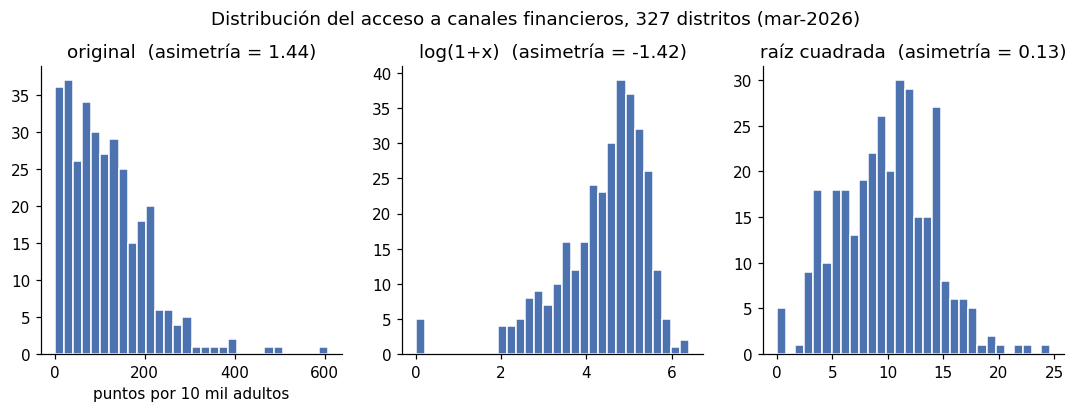

In [4]:
y = g["puntos_x10k_adultos"]
transf = pd.DataFrame({
    "original": y,
    "log(1+x)": np.log1p(y),
    "raíz cuadrada": np.sqrt(y),
})
print(transf.agg(["mean", "median", "std", "skew"]).round(2).T)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col in zip(axes, transf.columns):
    ax.hist(transf[col], bins=30, color="#4c72b0", edgecolor="white")
    ax.set_title(f"{col}  (asimetría = {transf[col].skew():.2f})")
axes[0].set_xlabel("puntos por 10 mil adultos")
fig.suptitle("Distribución del acceso a canales financieros, 327 distritos (mar-2026)", y=1.03)
fig.savefig(FIG / "02_histogramas_acceso.png", bbox_inches="tight")
plt.show()

## 4. Inestabilidad de tasas en distritos pequeños

Una tasa calculada sobre pocos adultos es muy variable: un distrito de 400 adultos con 20 agentes queda
"arriba" solo por el denominador. El gráfico de embudo lo muestra; la corrección estándar en estadística
espacial es el **suavizado Bayes empírico** (EB), que acerca las tasas de distritos pequeños a la media global
en proporción a su incertidumbre.

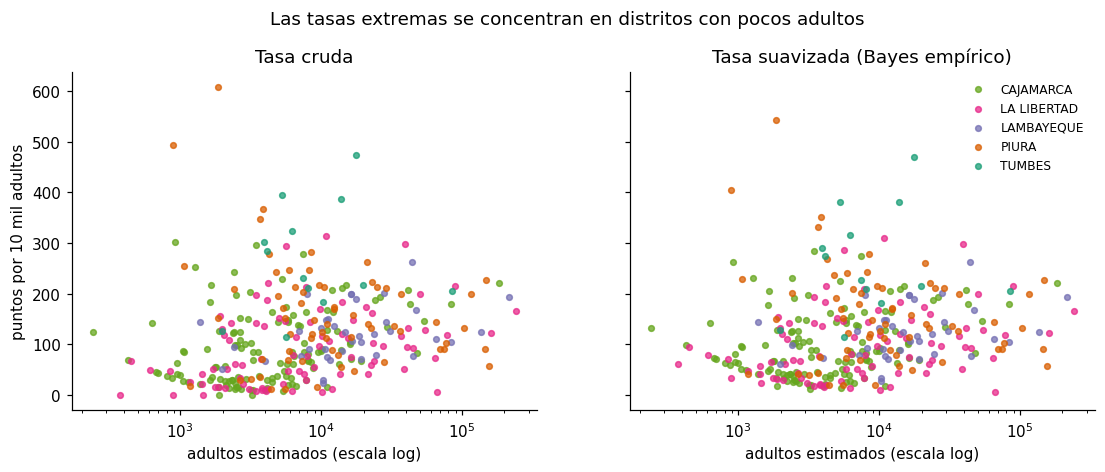

,distrito,provincia,pob_18mas,puntos_atencion,puntos_x10k_adultos,acceso_eb
288,AMOTAPE,PAITA,1842.5,112.0,607.9,543.4
289,ARENAL,PAITA,893.0,44.0,492.7,405.2
323,ZARUMILLA,ZARUMILLA,17699.4,840.0,474.6,469.1
326,PAPAYAL,ZARUMILLA,5244.4,207.0,394.7,381.1
324,AGUAS VERDES,ZARUMILLA,13766.6,532.0,386.4,381.3
292,TAMARINDO,PAITA,3842.0,141.0,367.0,350.8
309,BELLAVISTA DE LA UNION,SECHURA,3711.3,129.0,347.6,332.3
317,PAMPAS DE HOSPITAL,TUMBES,6167.3,200.0,324.3,315.9


In [5]:
eventos = g["puntos_atencion"].to_numpy().reshape(-1, 1)
base = g["pob_18mas"].to_numpy().reshape(-1, 1)
eb = Empirical_Bayes(eventos, base)
g["acceso_eb"] = 1e4 * eb.r.flatten()        # tasa suavizada por 10 mil adultos

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, titulo in [(axes[0], "puntos_x10k_adultos", "Tasa cruda"),
                        (axes[1], "acceso_eb", "Tasa suavizada (Bayes empírico)")]:
    for dep, sub in g.groupby("departamento"):
        ax.scatter(sub["pob_18mas"], sub[col], s=14, alpha=0.75, color=COLORES_DEP[dep], label=dep)
    ax.set_xscale("log")
    ax.set_xlabel("adultos estimados (escala log)")
    ax.set_title(titulo)
axes[0].set_ylabel("puntos por 10 mil adultos")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Las tasas extremas se concentran en distritos con pocos adultos", y=1.02)
fig.savefig(FIG / "02_embudo_tasas.png", bbox_inches="tight")
plt.show()

comp = g[["distrito", "provincia", "pob_18mas", "puntos_atencion", "puntos_x10k_adultos", "acceso_eb"]]
comp.sort_values("puntos_x10k_adultos", ascending=False).head(8).round(1)

## 5. Mapas temáticos

Acceso y pobreza en quintiles. La población urbana y los créditos tienen muchos ceros (distritos 100% rurales
o sin oficinas), por eso se usan cortes manuales: con quintiles varias clases quedarían vacías.

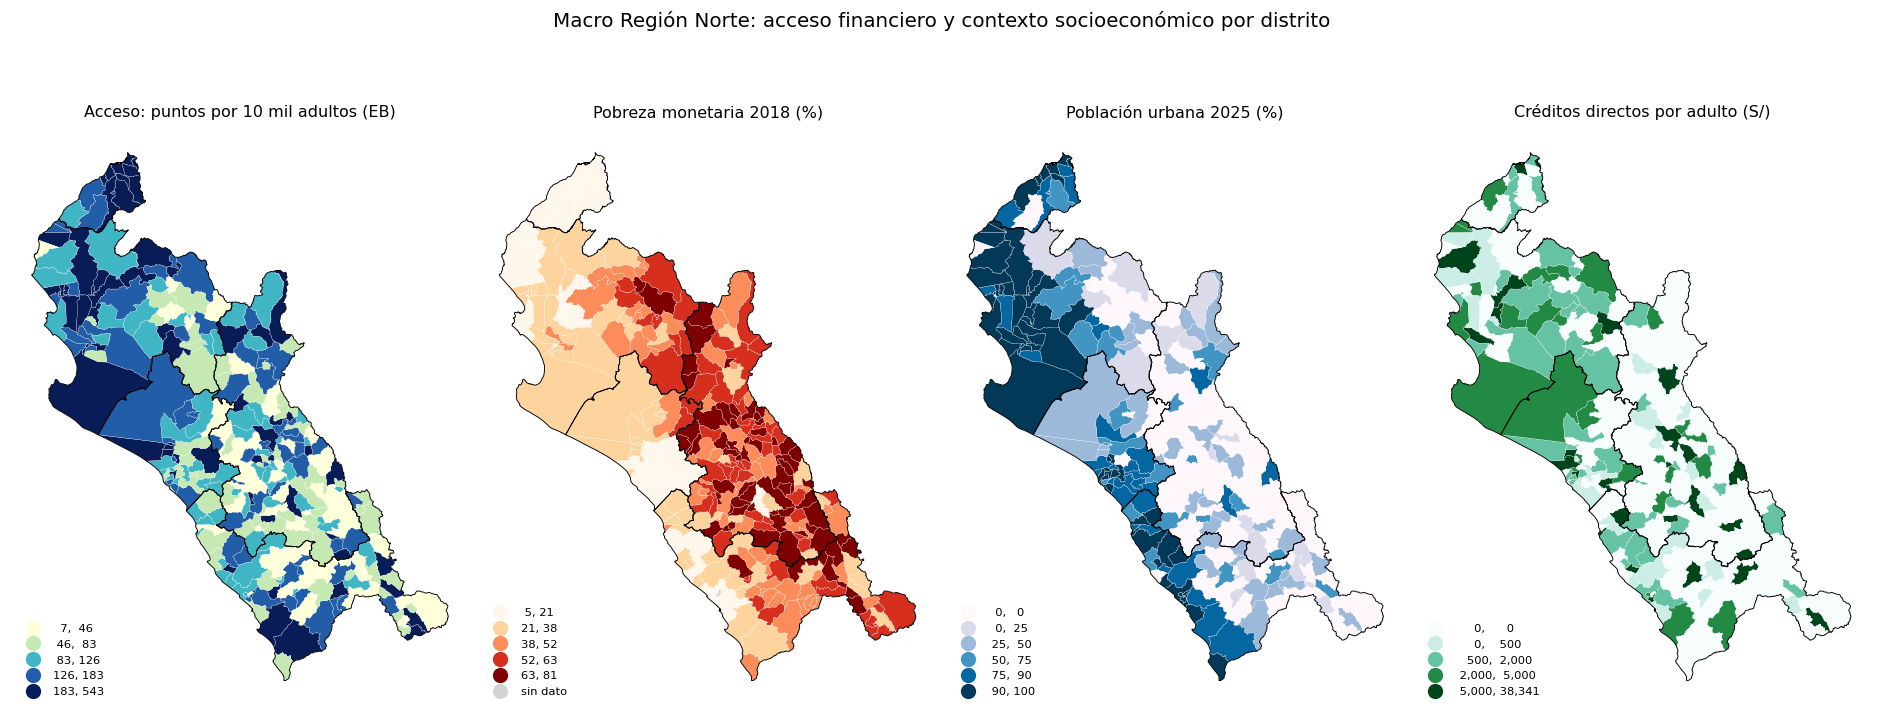

In [6]:
variables = [
    ("acceso_eb", "Acceso: puntos por 10 mil adultos (EB)", "YlGnBu", mc.Quantiles(g["acceso_eb"], k=5).bins),
    ("pobreza_2018", "Pobreza monetaria 2018 (%)", "OrRd", mc.Quantiles(g["pobreza_2018"].dropna(), k=5).bins),
    ("pct_urbana", "Población urbana 2025 (%)", "PuBu", [0, 25, 50, 75, 90, 100]),
    ("creditos_pc_soles", "Créditos directos por adulto (S/)", "BuGn", [0, 500, 2000, 5000, g["creditos_pc_soles"].max()]),
]

fig, axes = plt.subplots(1, 4, figsize=(17, 7.2), constrained_layout=True)
for ax, (col, titulo, cmap, bins) in zip(axes, variables):
    g.plot(column=col, scheme="UserDefined", classification_kwds={"bins": list(bins)}, cmap=cmap, ax=ax,
           edgecolor="white", linewidth=0.15, legend=True,
           legend_kwds={"loc": "lower left", "fontsize": 7.5, "frameon": False, "fmt": "{:,.0f}"},
           missing_kwds={"color": "lightgrey", "label": "sin dato"})
    deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(titulo, fontsize=10.5)
    ax.set_axis_off()
fig.suptitle("Macro Región Norte: acceso financiero y contexto socioeconómico por distrito", fontsize=13)
fig.savefig(FIG / "02_mapas_tematicos.png", bbox_inches="tight")
plt.show()

## 6. Boxmap: valores atípicos

El boxmap clasifica cada distrito según la caja del boxplot (bigotes a 1,5 veces el rango intercuartílico),
de modo que los atípicos quedan marcados en el mapa. Se compara la tasa cruda con la suavizada.

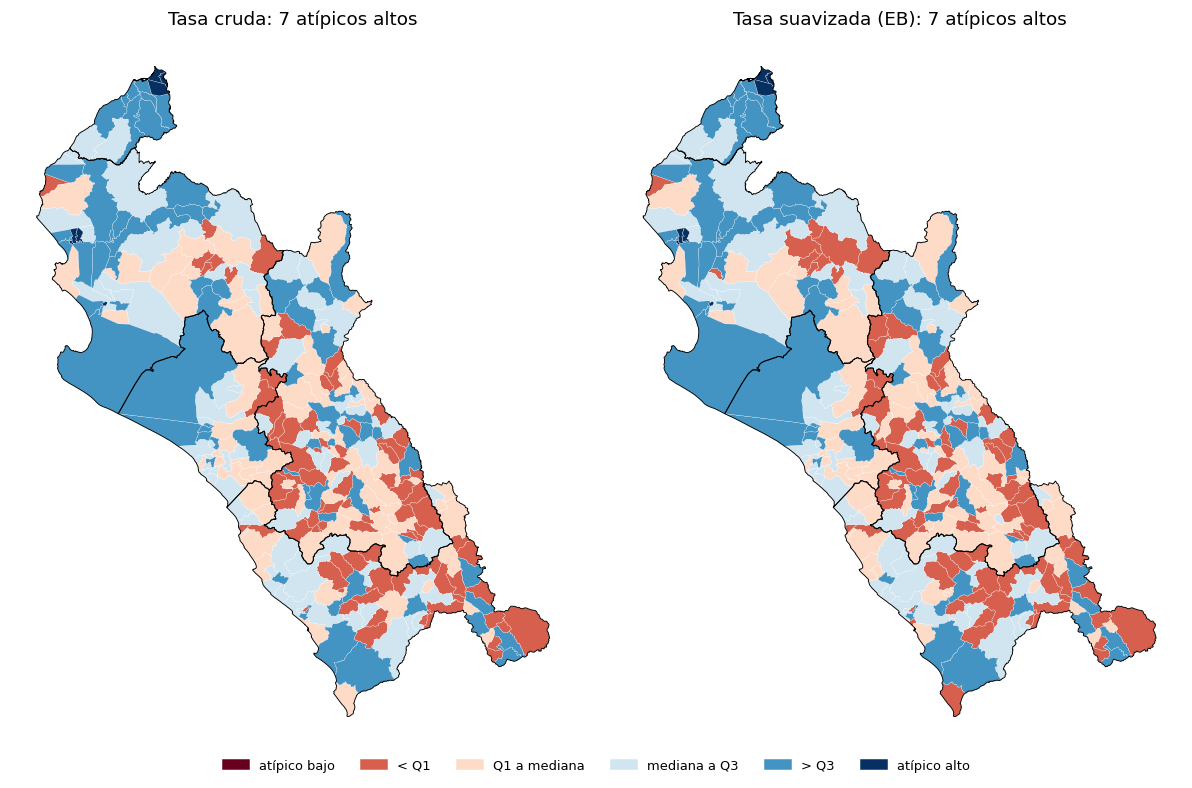

Límites del boxplot (EB): [-95.7  59.4 103.7 162.7 317.8 543.4]


,distrito,provincia,departamento,pob_18mas,acceso_eb
288,AMOTAPE,PAITA,PIURA,1842.5,543.4
323,ZARUMILLA,ZARUMILLA,TUMBES,17699.4,469.1
289,ARENAL,PAITA,PIURA,893.0,405.2
324,AGUAS VERDES,ZARUMILLA,TUMBES,13766.6,381.3
326,PAPAYAL,ZARUMILLA,TUMBES,5244.4,381.1
292,TAMARINDO,PAITA,PIURA,3842.0,350.8
309,BELLAVISTA DE LA UNION,SECHURA,PIURA,3711.3,332.3


In [7]:
CLASES_BOX = ["atípico bajo", "< Q1", "Q1 a mediana", "mediana a Q3", "> Q3", "atípico alto"]
COLORES_BOX = ["#67001f", "#d6604d", "#fddbc7", "#d1e5f0", "#4393c3", "#053061"]

fig, axes = plt.subplots(1, 2, figsize=(11, 6.8), constrained_layout=True)
for ax, col, titulo in [(axes[0], "puntos_x10k_adultos", "Tasa cruda"),
                        (axes[1], "acceso_eb", "Tasa suavizada (EB)")]:
    clas = mc.BoxPlot(g[col])
    for k, color in enumerate(COLORES_BOX):          # se pinta clase por clase para fijar los colores
        sub = g[clas.yb == k]
        if len(sub):
            sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.15)
    deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(f"{titulo}: {(clas.yb == 5).sum()} atípicos altos")
    ax.set_axis_off()
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES_BOX]
fig.legend(handles, CLASES_BOX, loc="lower center", ncol=6, frameon=False, fontsize=8.5, bbox_to_anchor=(0.5, -0.04))
fig.savefig(FIG / "02_boxmap_acceso.png", bbox_inches="tight")
plt.show()

clas_eb = mc.BoxPlot(g["acceso_eb"])
print("Límites del boxplot (EB):", np.round(clas_eb.bins, 1))
g[clas_eb.yb == 5][["distrito", "provincia", "departamento", "pob_18mas", "acceso_eb"]].sort_values("acceso_eb", ascending=False).round(1)

## 7. Relaciones bivariadas

Correlaciones de Spearman (robustas a la asimetría) entre el acceso suavizado y las covariables candidatas
para la regresión espacial (notebook 04).

pobreza_2018        -0.46
altitud_capital_m   -0.40
densidad_hab_km2     0.28
creditos_pc_soles    0.38
idh_2019             0.45
pct_urbana           0.46


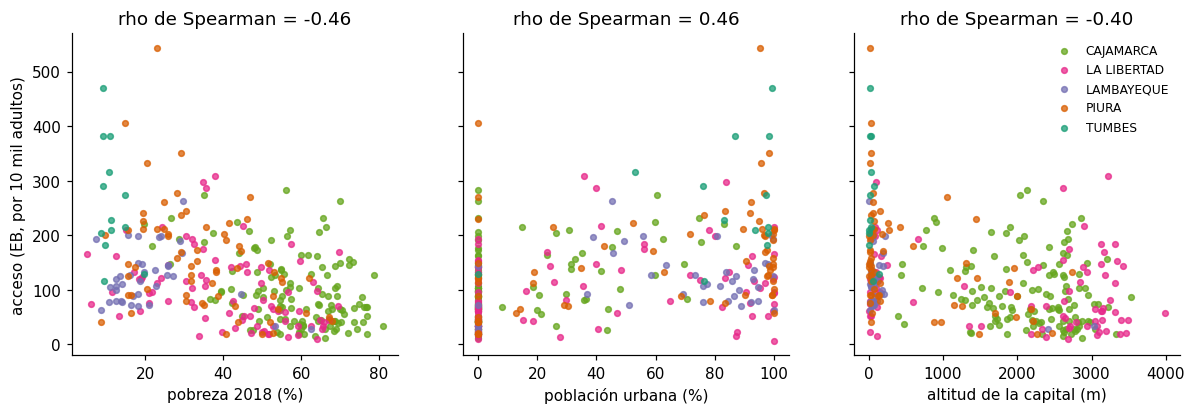

In [8]:
covs = ["pobreza_2018", "idh_2019", "pct_urbana", "densidad_hab_km2", "altitud_capital_m", "creditos_pc_soles"]
corr = g[["acceso_eb"] + covs].corr(method="spearman")["acceso_eb"].drop("acceso_eb").sort_values()
print(corr.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, col, xl in [(axes[0], "pobreza_2018", "pobreza 2018 (%)"),
                    (axes[1], "pct_urbana", "población urbana (%)"),
                    (axes[2], "altitud_capital_m", "altitud de la capital (m)")]:
    for dep, sub in g.groupby("departamento"):
        ax.scatter(sub[col], sub["acceso_eb"], s=14, alpha=0.75, color=COLORES_DEP[dep], label=dep)
    ax.set_xlabel(xl)
    ax.set_title(f"rho de Spearman = {corr[col]:.2f}")
axes[0].set_ylabel("acceso (EB, por 10 mil adultos)")
axes[2].legend(frameon=False, fontsize=8)
fig.savefig(FIG / "02_dispersion_covariables.png", bbox_inches="tight")
plt.show()

## 8. Estadísticos descriptivos espaciales: centro medio y distancia estándar

¿La oferta de canales está donde vive la gente? Comparamos el centro medio ponderado por población con el
centro medio ponderado por puntos de atención (usando el centroide de cada distrito), y la distancia estándar
(dispersión espacial alrededor del centro).

                     distancia_estandar_km  desplazamiento_vs_poblacion_km
población 2025                       172.4                             0.0
puntos de atención                   179.5                            14.3
cajeros automáticos                  178.0                            29.8


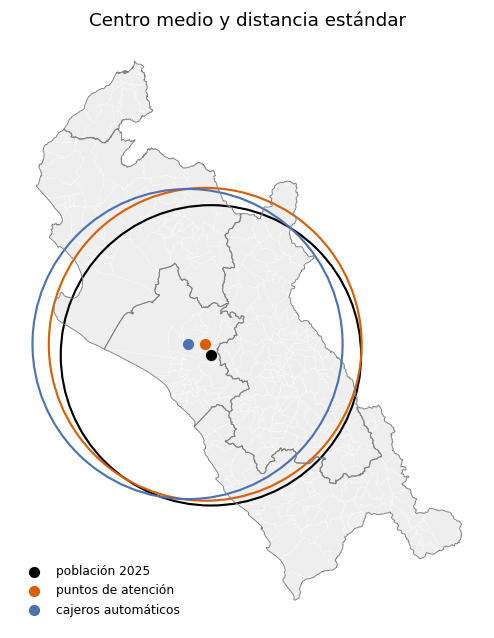

In [9]:
cent = g.geometry.centroid
x, yc = cent.x.to_numpy(), cent.y.to_numpy()

def centro_y_distancia(w):
    w = np.asarray(w, dtype=float)
    mx, my = np.average(x, weights=w), np.average(yc, weights=w)
    ds = np.sqrt(np.average((x - mx) ** 2 + (yc - my) ** 2, weights=w))
    return mx, my, ds

filas = {}
for nombre, w in [("población 2025", g["pob_total_2025"]), ("puntos de atención", g["puntos_atencion"]),
                  ("cajeros automáticos", g["n_atm"])]:
    mx, my, ds = centro_y_distancia(w)
    filas[nombre] = {"x_utm": mx, "y_utm": my, "distancia_estandar_km": ds / 1000}
cm = pd.DataFrame(filas).T
base_pob = cm.loc["población 2025", ["x_utm", "y_utm"]]
cm["desplazamiento_vs_poblacion_km"] = np.hypot(cm["x_utm"] - base_pob["x_utm"], cm["y_utm"] - base_pob["y_utm"]) / 1000
print(cm[["distancia_estandar_km", "desplazamiento_vs_poblacion_km"]].round(1))

fig, ax = plt.subplots(figsize=(6, 7))
g.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="grey", linewidth=0.6)
for (nombre, fila), color in zip(cm.iterrows(), ["black", "#d95f02", "#4c72b0"]):
    ax.add_patch(plt.Circle((fila.x_utm, fila.y_utm), fila.distancia_estandar_km * 1000,
                            fill=False, color=color, linewidth=1.4))
    ax.scatter(fila.x_utm, fila.y_utm, color=color, s=40, zorder=3, label=nombre)
ax.legend(frameon=False, loc="lower left", fontsize=8)
ax.set_title("Centro medio y distancia estándar")
ax.set_axis_off()
fig.savefig(FIG / "02_centro_medio.png", bbox_inches="tight")
plt.show()

## 9. Exportar la variable suavizada

In [10]:
g.drop(columns="geometry").to_csv(DATA / "base_aede.csv", index=False)
print("Guardado:", (DATA / "base_aede.csv").relative_to(ROOT))

Guardado: data/processed/base_aede.csv


## 10. Hallazgos para el proyecto

1. **Hay mucha oferta, pero mal repartida.** El ámbito tiene 139 puntos de atención por 10 mil adultos, aunque la
   mediana distrital es 102 y va de 0 a 608. Tumbes (mediana EB 227) y Piura (141) duplican a Cajamarca (83) y
   La Libertad (80).
2. **El acceso se apoya en los corresponsales.** 237 de 327 distritos no tienen ningún cajero automático y 197 no
   tienen oficina; en ellos el canal es casi siempre el agente corresponsal.
3. **Las tasas crudas engañan en distritos pequeños.** Los valores más altos (Amotape, Arenal) son distritos con
   menos de 2 mil adultos. Se usará la **tasa suavizada por Bayes empírico (`acceso_eb`)** como variable
   respuesta; su distribución es asimétrica (1,44 en la cruda), así que en la regresión conviene la raíz cuadrada
   (asimetría 0,13).
4. **Bajo acceso = sierra pobre.** De los 66 distritos del quintil más bajo de acceso, 57 están en Cajamarca y
   La Libertad, y su pobreza mediana es 60% frente a 38% en el resto. Los mapas sugieren un patrón agrupado,
   no aleatorio: eso se prueba con Moran y LISA en el notebook 03.
5. **Covariables candidatas** (Spearman con `acceso_eb`): % urbana +0,46, IDH +0,45, pobreza -0,46, altitud -0,40.
   Pobreza e IDH miden casi lo mismo; en la regresión se elegirá una para evitar colinealidad.
6. **La oferta está corrida hacia la costa.** El centro medio de los cajeros automáticos está 30 km al oeste del
   centro medio de la población, y el de todos los puntos de atención, 14 km.

# 03 Pesos Autocorrelacion

Notebook original: `03_pesos_autocorrelacion.ipynb`.

# 03 · Estructura de vecindad y autocorrelación espacial

| | |
|---|---|
| **Pregunta** | ¿El acceso a canales financieros se distribuye aleatoriamente entre distritos o forma agrupamientos, en particular zonas contiguas de bajo acceso ("desiertos financieros")? |
| **Variable** | y = √acceso_eb (tasa suavizada por Bayes empírico, notebook 02). |
| **Métodos** | Matrices de contigüidad (Reina, Torre), k vecinos más cercanos y banda de distancia; I de Moran y C de Geary globales con inferencia por permutación; LISA (Anselin, 1995) con control FDR; Getis-Ord Gi*; Moran bivariado global y local. |
| **Salidas** | `outputs/figuras/03_*.png` · `data/processed/lisa_acceso.csv`. |

In [1]:
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from esda import Geary, Moran, Moran_BV, Moran_Local, Moran_Local_BV, G_Local
from libpysal import weights

warnings.filterwarnings("ignore")
np.random.seed(2026)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
CRS_METRICO = "EPSG:32717"
PERM = 999   # permutaciones para la inferencia por aleatorización

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Datos

In [2]:
g = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs(CRS_METRICO)
aede = pd.read_csv(DATA / "base_aede.csv", dtype={"ubigeo": str})[["ubigeo", "acceso_eb"]]
g = g.merge(aede, on="ubigeo", how="left").reset_index(drop=True)
g["y"] = np.sqrt(g["acceso_eb"])
deps = g.dissolve("departamento").reset_index()[["departamento", "geometry"]]
print(f"{len(g)} distritos | y: media {g['y'].mean():.2f}, desv. {g['y'].std():.2f}")

327 distritos | y: media 10.28, desv. 3.64


## 2. Matrices de pesos espaciales

Se comparan cuatro definiciones de vecindad. Todas se estandarizan por filas (cada fila suma 1), de modo que el
rezago espacial `W·y` es el promedio de los vecinos.

- **Reina (Queen):** vecinos si comparten al menos un vértice.
- **Torre (Rook):** vecinos si comparten un borde.
- **k vecinos más cercanos (k = 6):** los 6 centroides más cercanos; todos tienen el mismo número de vecinos.
- **Banda de distancia:** vecinos a menos de *d* km, con *d* el mínimo que no deja distritos aislados.

In [3]:
cent = g.copy(); cent["geometry"] = g.geometry.centroid
d_min = weights.min_threshold_distance(np.column_stack([cent.geometry.x, cent.geometry.y]))

W = {
    "Reina": weights.Queen.from_dataframe(g, use_index=False),
    "Torre": weights.Rook.from_dataframe(g, use_index=False),
    "kNN (k=6)": weights.KNN.from_dataframe(cent, k=6),
    f"Banda {d_min/1000:.0f} km": weights.DistanceBand.from_dataframe(cent, threshold=d_min, binary=True),
}
filas = []
for nombre, w in W.items():
    card = pd.Series(w.cardinalities)
    filas.append({"matriz": nombre, "aislados": len(w.islands), "vecinos_media": card.mean(),
                  "vecinos_min": card.min(), "vecinos_max": card.max(), "% no ceros": w.pct_nonzero})
    w.transform = "r"
pd.DataFrame(filas).set_index("matriz").round(2)

,aislados,vecinos_media,vecinos_min,vecinos_max,% no ceros
matriz,,,,,
Reina,0,5.45,1,14,1.67
Torre,0,5.33,1,13,1.63
kNN (k=6),0,6.00,6,6,1.83
Banda 43 km,0,17.83,1,41,5.45


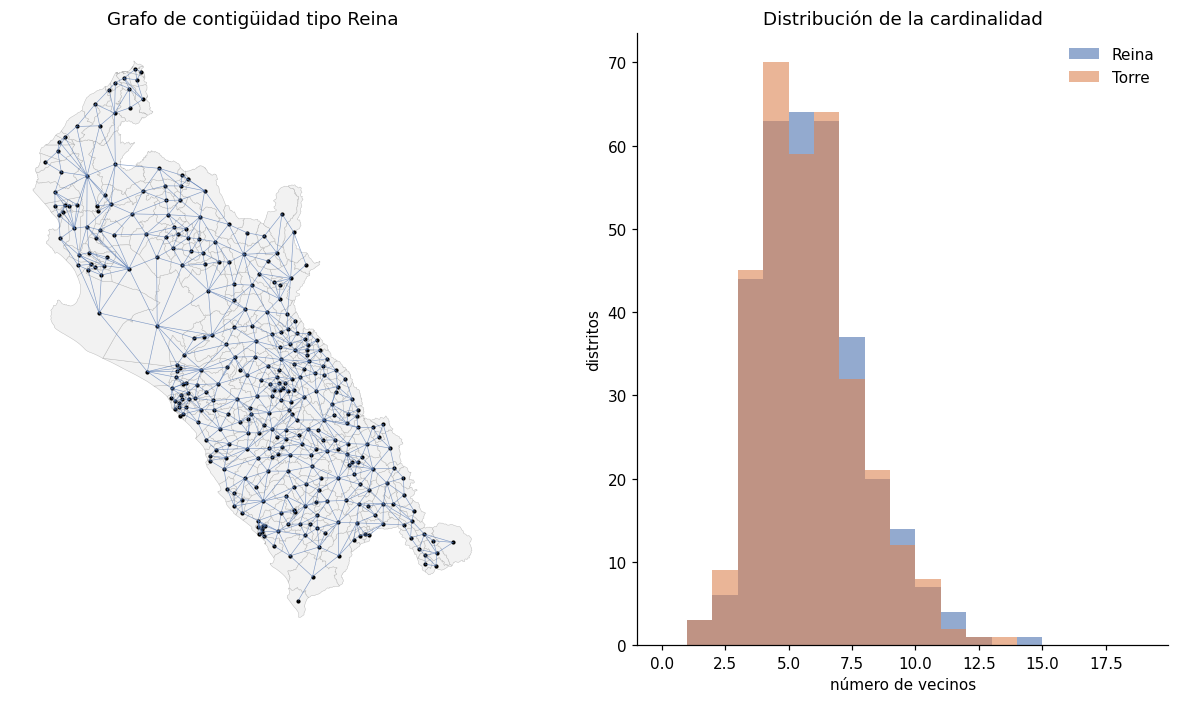

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
g.plot(ax=ax, color="#f2f2f2", edgecolor="#bbbbbb", linewidth=0.3)
w = W["Reina"]
xy = np.column_stack([cent.geometry.x, cent.geometry.y])
for i, vecinos in w.neighbors.items():
    for j in vecinos:
        if j > i:
            ax.plot(*zip(xy[i], xy[j]), color="#4c72b0", linewidth=0.4, alpha=0.7)
ax.scatter(xy[:, 0], xy[:, 1], s=3, color="black")
ax.set_title("Grafo de contigüidad tipo Reina")
ax.set_axis_off()

ax = axes[1]
bins = np.arange(0, 20)
for nombre, color in [("Reina", "#4c72b0"), ("Torre", "#dd8452")]:
    ax.hist(pd.Series(W[nombre].cardinalities), bins=bins, alpha=0.6, color=color, label=nombre)
ax.set_xlabel("número de vecinos"); ax.set_ylabel("distritos"); ax.legend(frameon=False)
ax.set_title("Distribución de la cardinalidad")
fig.tight_layout()
fig.savefig(FIG / "03_matriz_pesos.png", bbox_inches="tight")
plt.show()

## 3. Autocorrelación global: I de Moran y C de Geary

- **I de Moran** > 0 indica agrupamiento de valores parecidos; su esperanza bajo aleatoriedad es -1/(n-1) ≈ 0.
- **C de Geary** < 1 indica autocorrelación positiva (diferencias pequeñas entre vecinos).

La significancia se obtiene por **999 permutaciones aleatorias** de los valores sobre el mapa (pseudo p-valor).

In [5]:
res = []
for nombre, w in W.items():
    mi = Moran(g["y"], w, permutations=PERM)
    gc = Geary(g["y"], w, permutations=PERM)
    res.append({"matriz": nombre, "I": mi.I, "E[I]": mi.EI, "z (perm.)": mi.z_sim, "p (perm.)": mi.p_sim,
                "C de Geary": gc.C, "p Geary": gc.p_sim})
moran_tab = pd.DataFrame(res).set_index("matriz")
moran_tab.round(3)

,I,E[I],z (perm.),p (perm.),C de Geary,p Geary
matriz,,,,,,
Reina,0.277,-0.003,8.176,0.001,0.721,0.001
Torre,0.277,-0.003,8.229,0.001,0.720,0.001
kNN (k=6),0.281,-0.003,9.743,0.001,0.736,0.001
Banda 43 km,0.264,-0.003,13.092,0.001,0.737,0.001


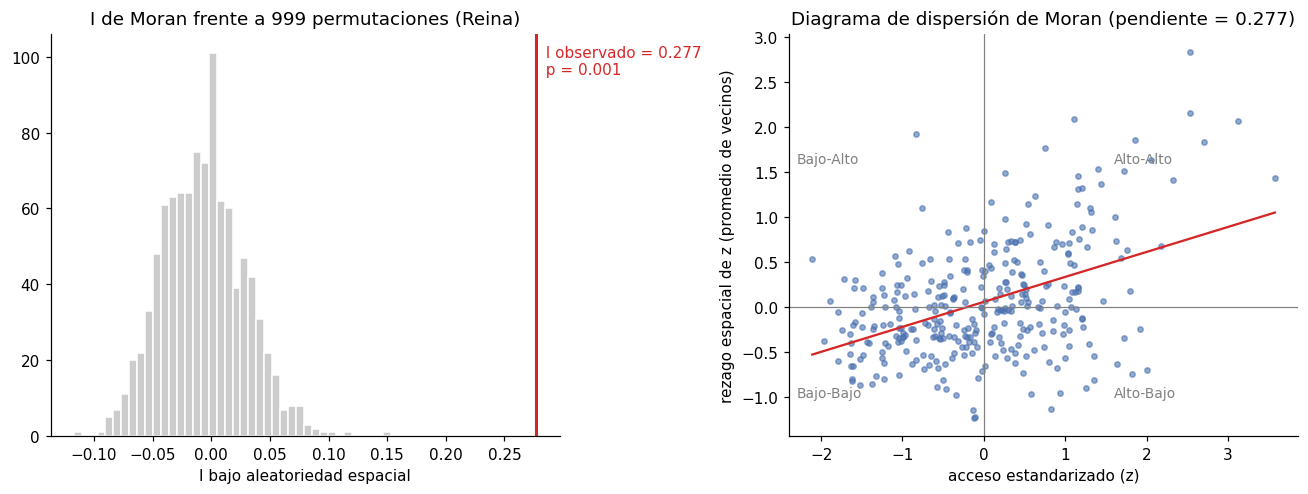

In [6]:
mi = Moran(g["y"], W["Reina"], permutations=PERM)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

ax = axes[0]
ax.hist(mi.sim, bins=40, color="#cccccc", edgecolor="white")
ax.axvline(mi.I, color="#d62728", linewidth=2)
ax.text(mi.I, ax.get_ylim()[1] * 0.9, f"  I observado = {mi.I:.3f}\n  p = {mi.p_sim:.3f}", color="#d62728")
ax.set_title("I de Moran frente a 999 permutaciones (Reina)")
ax.set_xlabel("I bajo aleatoriedad espacial")

ax = axes[1]
z = (g["y"] - g["y"].mean()) / g["y"].std()
lag = weights.lag_spatial(W["Reina"], z)
ax.scatter(z, lag, s=12, alpha=0.6, color="#4c72b0")
b = np.polyfit(z, lag, 1)
xs = np.linspace(z.min(), z.max(), 10)
ax.plot(xs, b[0] * xs + b[1], color="#d62728")
ax.axhline(0, color="grey", linewidth=0.8); ax.axvline(0, color="grey", linewidth=0.8)
for txt, (xx, yy) in {"Alto-Alto": (1.6, 1.6), "Bajo-Bajo": (-2.3, -1.0), "Bajo-Alto": (-2.3, 1.6), "Alto-Bajo": (1.6, -1.0)}.items():
    ax.text(xx, yy, txt, color="grey", fontsize=9)
ax.set_xlabel("acceso estandarizado (z)"); ax.set_ylabel("rezago espacial de z (promedio de vecinos)")
ax.set_title(f"Diagrama de dispersión de Moran (pendiente = {b[0]:.3f})")
fig.tight_layout()
fig.savefig(FIG / "03_moran_global.png", bbox_inches="tight")
plt.show()

## 4. Autocorrelación local: LISA

El I de Moran local descompone el índice global por distrito. Con 999 permutaciones condicionales se clasifica
cada distrito significativo (p < 0,05) en:

- **Alto-Alto (HH):** buen acceso rodeado de buen acceso.
- **Bajo-Bajo (LL):** poco acceso rodeado de poco acceso: **desierto financiero**, el objetivo comercial del proyecto.
- **Bajo-Alto (LH) / Alto-Bajo (HL):** atípicos espaciales.

Como se hacen 327 pruebas a la vez, se reporta también cuántos siguen siendo significativos con la corrección
FDR (tasa de falsos descubrimientos) como prueba de robustez.

In [7]:
from esda import fdr

lisa = Moran_Local(g["y"], W["Reina"], permutations=PERM, seed=2026)
ETQ = {0: "No significativo", 1: "Alto-Alto", 2: "Bajo-Alto", 3: "Bajo-Bajo", 4: "Alto-Bajo"}
COL = {"No significativo": "#e6e6e6", "Alto-Alto": "#d7191c", "Bajo-Bajo": "#2c7bb6",
       "Bajo-Alto": "#abd9e9", "Alto-Bajo": "#fdae61"}
g["lisa_q"] = np.where(lisa.p_sim < 0.05, lisa.q, 0)
g["lisa"] = g["lisa_q"].map(ETQ)
g["lisa_p"] = lisa.p_sim
g["lisa_Ii"] = lisa.Is

umbral_fdr = fdr(lisa.p_sim, 0.05)
print(f"Umbral FDR: {umbral_fdr:.4f} -> distritos significativos con FDR: {(lisa.p_sim <= umbral_fdr).sum()}")
pd.crosstab(g["lisa"], g["departamento"], margins=True, margins_name="Total")

Umbral FDR: 0.0021 -> distritos significativos con FDR: 14


departamento,CAJAMARCA,LA LIBERTAD,LAMBAYEQUE,PIURA,TUMBES,Total
lisa,,,,,,
Alto-Alto,1,0,1,22,10,34
Alto-Bajo,5,5,0,0,0,10
Bajo-Alto,0,1,0,2,0,3
Bajo-Bajo,14,1,0,4,0,19
No significativo,107,77,37,37,3,261
Total,127,84,38,65,13,327


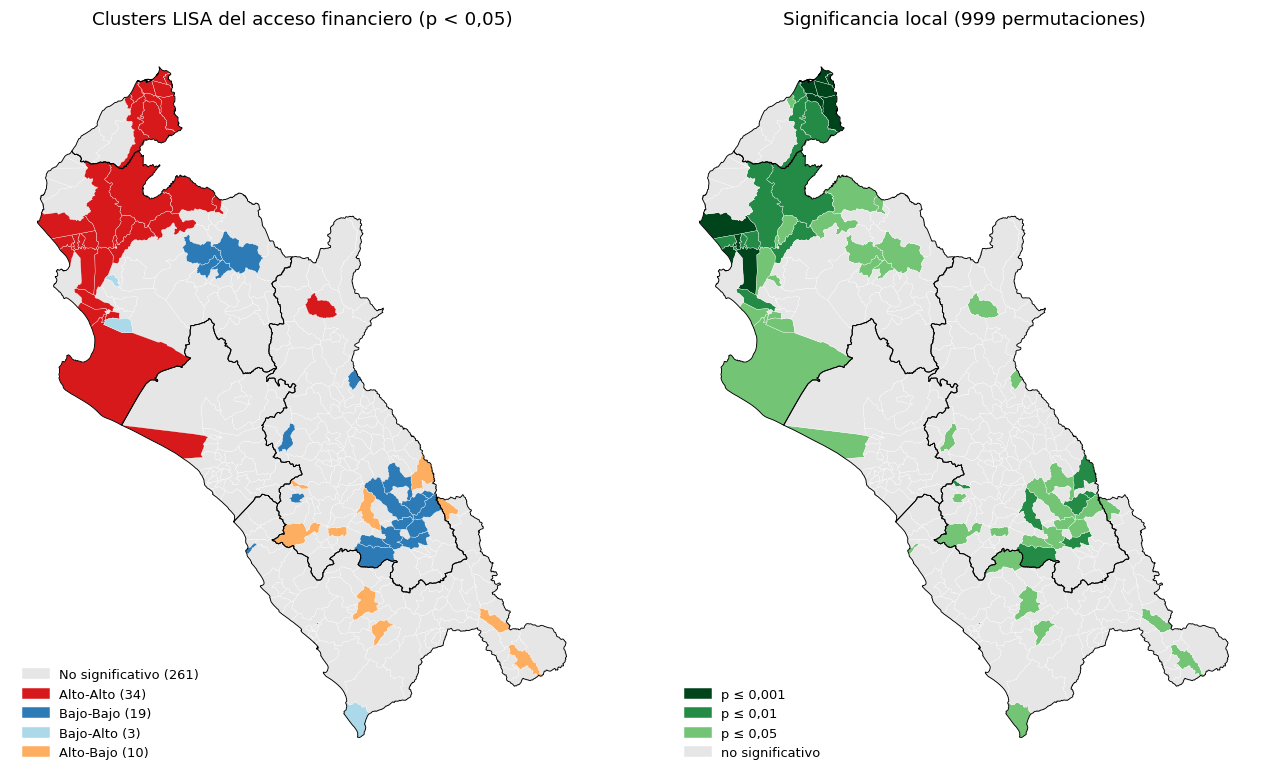

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7), constrained_layout=True)
ax = axes[0]
for etq, color in COL.items():
    sub = g[g["lisa"] == etq]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()],
          [f"{k} ({(g['lisa'] == k).sum()})" for k in COL], loc="lower left", frameon=False, fontsize=8.5)
ax.set_title("Clusters LISA del acceso financiero (p < 0,05)")
ax.set_axis_off()

ax = axes[1]
cortes = [0, 0.001, 0.01, 0.05, 1.0]
etiquetas_p = ["p ≤ 0,001", "p ≤ 0,01", "p ≤ 0,05", "no significativo"]
colores_p = ["#00441b", "#238b45", "#74c476", "#e6e6e6"]
g["p_clase"] = pd.cut(g["lisa_p"], cortes, labels=etiquetas_p, include_lowest=True)
for etq, color in zip(etiquetas_p, colores_p):
    sub = g[g["p_clase"] == etq]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_p], etiquetas_p,
          loc="lower left", frameon=False, fontsize=8.5)
ax.set_title("Significancia local (999 permutaciones)")
ax.set_axis_off()
fig.savefig(FIG / "03_lisa_acceso.png", bbox_inches="tight")
plt.show()

In [9]:
# Desiertos financieros: distritos Bajo-Bajo
desiertos = g[g["lisa"] == "Bajo-Bajo"].sort_values("acceso_eb")
print(f"{len(desiertos)} distritos Bajo-Bajo | {desiertos['pob_total_2025'].sum():,.0f} habitantes | "
      f"{desiertos['pob_18mas'].sum():,.0f} adultos estimados")
desiertos[["distrito", "provincia", "departamento", "pob_total_2025", "acceso_eb", "pobreza_2018", "lisa_p"]].round(2)

19 distritos Bajo-Bajo | 212,000 habitantes | 157,222 adultos estimados


,distrito,provincia,departamento,pob_total_2025,acceso_eb,pobreza_2018,lisa_p
95,GREGORIO PITA,SAN MARCOS,CAJAMARCA,5492,18.68,60.85,0.04
279,CHALACO,MORROPON,PIURA,7401,19.10,49.98,0.04
285,SANTO DOMINGO,MORROPON,PIURA,5955,19.21,40.74,0.04
25,SUCRE,CELENDIN,CAJAMARCA,5581,22.59,53.91,0.01
23,OXAMARCA,CELENDIN,CAJAMARCA,6029,33.54,81.00,0.01
1,ASUNCION,CAJAMARCA,CAJAMARCA,7544,42.13,58.25,0.04
264,PACAIPAMPA,AYABACA,PIURA,24326,49.68,67.17,0.04
260,FRIAS,AYABACA,PIURA,19849,57.83,61.37,0.04
5,JESUS,CAJAMARCA,CAJAMARCA,17951,62.58,70.50,0.05
3,COSPAN,CAJAMARCA,CAJAMARCA,6809,66.81,73.63,0.00


## 5. Extra: puntos calientes y fríos (Getis-Ord Gi*)

Gi* compara la suma local (el distrito y sus vecinos) con la esperada. A diferencia del LISA no separa atípicos,
pero es la medida más usada para comunicar "zonas frías" a un público no técnico, útil para el póster.

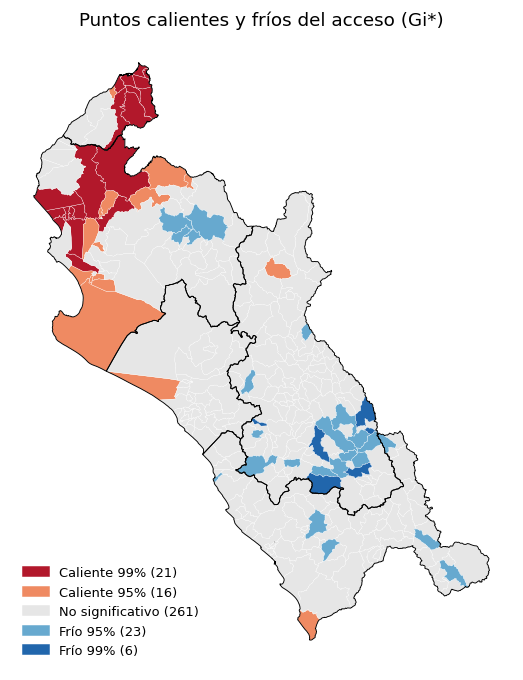

In [10]:
gi = G_Local(g["y"], W["Reina"], star=True, permutations=PERM, seed=2026)
g["gi_z"] = gi.Zs
g["gi_clase"] = np.select(
    [(gi.p_sim < 0.01) & (gi.Zs > 0), (gi.p_sim < 0.05) & (gi.Zs > 0),
     (gi.p_sim < 0.01) & (gi.Zs < 0), (gi.p_sim < 0.05) & (gi.Zs < 0)],
    ["Caliente 99%", "Caliente 95%", "Frío 99%", "Frío 95%"], default="No significativo")
COL_GI = {"Caliente 99%": "#b2182b", "Caliente 95%": "#ef8a62", "No significativo": "#e6e6e6",
          "Frío 95%": "#67a9cf", "Frío 99%": "#2166ac"}

fig, ax = plt.subplots(figsize=(6.5, 7.5))
for etq, color in COL_GI.items():
    sub = g[g["gi_clase"] == etq]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COL_GI.values()],
          [f"{k} ({(g['gi_clase'] == k).sum()})" for k in COL_GI], loc="lower left", frameon=False, fontsize=8.5)
ax.set_title("Puntos calientes y fríos del acceso (Gi*)")
ax.set_axis_off()
fig.savefig(FIG / "03_getis_ord.png", bbox_inches="tight")
plt.show()

## 6. Dependencia bivariada: pobreza y acceso de los vecinos

El LISA bivariado relaciona la **pobreza de cada distrito** con el **acceso promedio de sus vecinos**.
Los distritos "Alto-Bajo" (pobres rodeados de poco acceso) son los más difíciles de atender: ni el propio
distrito ni su entorno tienen canales. Alto Trujillo, sin dato de pobreza 2018, se imputa con el promedio de
sus vecinos (rezago espacial).

Imputados por rezago espacial: ['ALTO TRUJILLO']
I de Moran bivariado (pobreza, acceso de los vecinos) = -0.270, p = 0.001


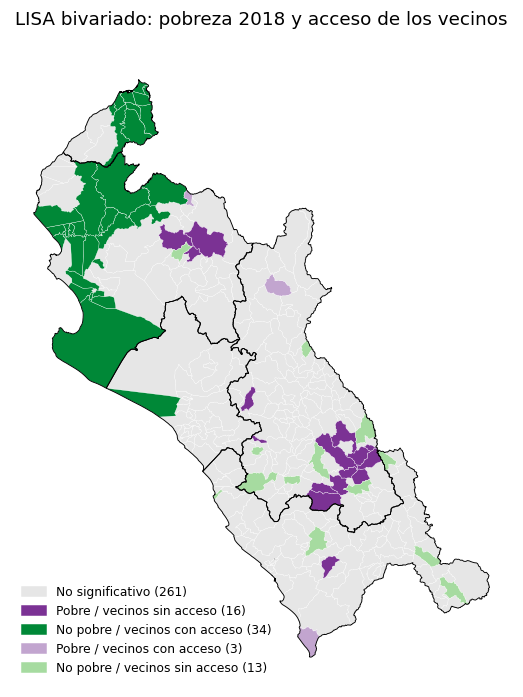

lisa_bv
No significativo                 261
No pobre / vecinos con acceso     34
Pobre / vecinos sin acceso        16
No pobre / vecinos sin acceso     13
Pobre / vecinos con acceso         3
Name: count, dtype: int64

In [11]:
pob = g["pobreza_2018"].copy()
faltan = pob.isna()
if faltan.any():
    lag_pob = weights.lag_spatial(W["Reina"], pob.fillna(pob.mean()))
    pob[faltan] = lag_pob[faltan]
    print("Imputados por rezago espacial:", g.loc[faltan, "distrito"].tolist())
g["pobreza_imp"] = pob

bv = Moran_BV(g["pobreza_imp"], g["y"], W["Reina"], permutations=PERM)
print(f"I de Moran bivariado (pobreza, acceso de los vecinos) = {bv.I:.3f}, p = {bv.p_sim:.3f}")

lbv = Moran_Local_BV(g["pobreza_imp"], g["y"], W["Reina"], permutations=PERM, seed=2026)
ETQ_BV = {0: "No significativo", 1: "Pobre / vecinos con acceso", 2: "No pobre / vecinos con acceso",
          3: "No pobre / vecinos sin acceso", 4: "Pobre / vecinos sin acceso"}
COL_BV = {"No significativo": "#e6e6e6", "Pobre / vecinos sin acceso": "#7b3294",
          "No pobre / vecinos con acceso": "#008837", "Pobre / vecinos con acceso": "#c2a5cf",
          "No pobre / vecinos sin acceso": "#a6dba0"}
g["lisa_bv"] = pd.Series(np.where(lbv.p_sim < 0.05, lbv.q, 0)).map(ETQ_BV).values

fig, ax = plt.subplots(figsize=(6.5, 7.5))
for etq, color in COL_BV.items():
    sub = g[g["lisa_bv"] == etq]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COL_BV.values()],
          [f"{k} ({(g['lisa_bv'] == k).sum()})" for k in COL_BV], loc="lower left", frameon=False, fontsize=8)
ax.set_title("LISA bivariado: pobreza 2018 y acceso de los vecinos")
ax.set_axis_off()
fig.savefig(FIG / "03_lisa_bivariado.png", bbox_inches="tight")
plt.show()
g["lisa_bv"].value_counts()

## 7. ¿Las covariables también tienen dependencia espacial?

Si la variable respuesta y sus explicativas están autocorrelacionadas, un modelo OLS dejará residuos
autocorrelacionados. Esto anticipa la necesidad de los modelos SAR y SEM del notebook 04.

In [12]:
covs = {"acceso (y)": g["y"], "pobreza 2018": g["pobreza_imp"], "IDH 2019": g["idh_2019"].fillna(g["idh_2019"].mean()),
        "% urbana": g["pct_urbana"], "altitud": g["altitud_capital_m"].fillna(g["altitud_capital_m"].mean()),
        "log densidad": np.log1p(g["densidad_hab_km2"])}
pd.DataFrame({k: {"I de Moran": (m := Moran(v, W["Reina"], permutations=PERM)).I, "p": m.p_sim}
              for k, v in covs.items()}).T.round(3)

,I de Moran,p
acceso (y),0.277,0.001
pobreza 2018,0.692,0.001
IDH 2019,0.615,0.001
% urbana,0.646,0.001
altitud,0.857,0.001
log densidad,0.564,0.001


## 8. Exportar

In [13]:
cols = ["ubigeo", "distrito", "provincia", "departamento", "y", "acceso_eb", "lisa", "lisa_p", "lisa_Ii",
        "gi_z", "gi_clase", "lisa_bv", "pobreza_imp"]
g[cols].to_csv(DATA / "lisa_acceso.csv", index=False)
print("Guardado:", (DATA / "lisa_acceso.csv").relative_to(ROOT))

Guardado: data/processed/lisa_acceso.csv


## 9. Hallazgos para el proyecto

1. **El acceso no es aleatorio en el espacio.** I de Moran = 0,277 (p = 0,001 con 999 permutaciones) y C de Geary
   = 0,72 (p = 0,001). El resultado es casi idéntico con las cuatro matrices (I entre 0,26 y 0,28), así que no
   depende de cómo se definan los vecinos. Se adopta la matriz **Reina** para el resto del proyecto (sin
   aislados, 5,5 vecinos en promedio).
2. **Dos regímenes claros.** Hay 34 distritos Alto-Alto, casi todos en la costa de Piura y Tumbes (corredor
   Tumbes-Sullana-Piura-Paita), y **19 desiertos financieros Bajo-Bajo** con 212 mil habitantes: 14 en
   Cajamarca (Cajamarca, Celendín, San Marcos) y 4 en la sierra de Piura (Ayabaca y Morropón).
3. **Robustez.** Con corrección FDR por pruebas múltiples siguen siendo significativos 14 distritos; los núcleos
   de ambos regímenes se mantienen. Gi* confirma el mismo patrón: 37 puntos calientes y 29 fríos.
4. **Pobreza y acceso del entorno van en sentido opuesto.** I de Moran bivariado = -0,27 (p = 0,001). Hay 16
   distritos pobres rodeados de vecinos sin acceso (12 en Cajamarca): ni el distrito ni su entorno tienen canales,
   son el segmento prioritario para agentes o EOB.
5. **Las covariables están aún más autocorrelacionadas** que el acceso (pobreza 0,69, altitud 0,86, % urbana 0,65).
   Un OLS dejaría dependencia en los residuos: el notebook 04 compara OLS, SAR y SEM.

# 04 Regresion Espacial

Notebook original: `04_regresion_espacial.ipynb`.

# 04 · Modelos econométricos espaciales del acceso financiero

| | |
|---|---|
| **Objetivo** | Estimar el efecto de la pobreza, la urbanización, la altitud y la densidad poblacional sobre el acceso a canales financieros, controlando la dependencia espacial detectada en el notebook 03 (I de Moran = 0,28). |
| **Especificación** | y = √acceso_eb; matriz de contigüidad Reina estandarizada por filas. |
| **Modelos** | OLS con diagnóstico LM (Anselin, 1988); SAR y SEM por máxima verosimilitud; S2SLS y GMM heterocedástico (Kelejian y Prucha, 1998, 2010); modelo espacial de Durbin con descomposición de impactos (LeSage y Pace, 2009). |
| **Salidas** | `outputs/figuras/04_*.png` · `outputs/tablas/04_comparacion_modelos.csv`. |

In [1]:
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spreg
from esda import Moran
from libpysal import weights

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("spreg", spreg.__version__)

spreg 1.9.0


## 1. Datos y variables

In [2]:
g = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs("EPSG:32717")
lisa = pd.read_csv(DATA / "lisa_acceso.csv", dtype={"ubigeo": str})[["ubigeo", "y", "pobreza_imp", "lisa"]]
g = g.merge(lisa, on="ubigeo").reset_index(drop=True)

# Covariables (faltantes de Alto Trujillo: pobreza imputada por rezago espacial en el notebook 03; altitud con la media)
g["altitud_km"] = g["altitud_capital_m"].fillna(g["altitud_capital_m"].mean()) / 1000
g["log_densidad"] = np.log(g["densidad_hab_km2"])

Y_NAME = "y"
X_NAMES = ["pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]
ETIQUETAS = {"CONSTANT": "Constante", "pobreza_imp": "Pobreza 2018 (%)", "pct_urbana": "Población urbana (%)",
             "altitud_km": "Altitud (km)", "log_densidad": "log densidad (hab/km²)",
             "W_y": "rho (rezago de y)", "lambda": "lambda (error espacial)"}

y = g[[Y_NAME]].to_numpy()
X = g[X_NAMES].to_numpy()
w = weights.Queen.from_dataframe(g, use_index=False)
w.transform = "r"
g[[Y_NAME] + X_NAMES].describe().round(2)

,y,pobreza_imp,pct_urbana,altitud_km,log_densidad
count,327.00,327.00,327.00,327.00,327.00
mean,10.28,43.12,37.41,1.45,3.90
std,3.64,19.77,40.67,1.21,1.46
min,2.59,4.99,0.00,0.00,-0.02
25%,7.70,25.80,0.00,0.08,3.04
50%,10.18,45.33,20.69,1.56,3.59
75%,12.76,59.53,83.27,2.62,4.47
max,23.31,81.00,100.00,3.99,10.04


## 2. Multicolinealidad

Pobreza e IDH miden casi lo mismo (notebook 02), por eso se incluye solo pobreza. Se revisan los factores de
inflación de varianza (VIF): valores mayores a 5 o 10 indicarían colinealidad problemática.

In [3]:
def vif(df):
    Z = (df - df.mean()) / df.std()
    R = np.corrcoef(Z.T)
    return pd.Series(np.diag(np.linalg.inv(R)), index=df.columns, name="VIF")
vif(g[X_NAMES]).round(2)

pobreza_imp     3.47
pct_urbana      3.98
altitud_km      2.73
log_densidad    1.60
Name: VIF, dtype: float64

## 3. Modelo lineal clásico (OLS) y diagnóstico espacial

Si los residuos del OLS están autocorrelacionados, sus errores estándar son inválidos. Las pruebas de
multiplicadores de Lagrange (LM) indican qué estructura espacial falta:

- **LM-rezago / LM-rezago robusto:** dependencia en la variable respuesta (modelo SAR).
- **LM-error / LM-error robusto:** dependencia en el término de error (modelo SEM).

Regla de decisión de Anselin (2005): si ambas LM simples son significativas, se comparan las versiones robustas.

In [4]:
ols = spreg.OLS(y, X, w=w, spat_diag=True, moran=True, white_test=True,
                name_y=Y_NAME, name_x=X_NAMES, name_w="Reina", name_ds="GeoBanca Norte")
print(ols.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :GeoBanca Norte
Weights matrix      :       Reina
Dependent Variable  :           y                Number of Observations:         327
Mean dependent var  :     10.2784                Number of Variables   :           5
S.D. dependent var  :      3.6434                Degrees of Freedom    :         322
R-squared           :      0.2334
Adjusted R-squared  :      0.2239
Sum squared residual:     3317.46                F-statistic           :     24.5075
Sigma-square        :      10.303                Prob(F-statistic)     :   1.007e-17
S.E. of regression  :       3.210                Log likelihood        :    -842.822
Sigma-square ML     :      10.145                Akaike info criterion :    1695.643
S.E of regression ML:      3.1851                Schwarz criterion     :    1714.593

---------------

In [5]:
diag = pd.DataFrame({
    "estadístico": [ols.moran_res[0], ols.lm_lag[0], ols.rlm_lag[0], ols.lm_error[0], ols.rlm_error[0], ols.jarque_bera["jb"], ols.breusch_pagan["bp"]],
    "p-valor": [ols.moran_res[2], ols.lm_lag[1], ols.rlm_lag[1], ols.lm_error[1], ols.rlm_error[1], ols.jarque_bera["pvalue"], ols.breusch_pagan["pvalue"]],
}, index=["I de Moran (residuos)", "LM rezago", "LM rezago robusto", "LM error", "LM error robusto",
          "Jarque-Bera (normalidad)", "Breusch-Pagan (heterocedasticidad)"])
diag.round(4)

,estadístico,p-valor
I de Moran (residuos),0.2144,0.0000
LM rezago,21.6376,0.0000
LM rezago robusto,15.3055,0.0001
LM error,37.6966,0.0000
LM error robusto,31.3645,0.0000
Jarque-Bera (normalidad),6.5351,0.0381
Breusch-Pagan (heterocedasticidad),3.2686,0.5139


## 4. Modelos espaciales por máxima verosimilitud (ML)

- **SAR (rezago espacial):** `y = ρWy + Xβ + ε`. El acceso de un distrito depende del acceso de sus vecinos
  (derrame: un agente atiende también a gente del distrito vecino).
- **SEM (error espacial):** `y = Xβ + u,  u = λWu + ε`. La dependencia viene de factores no observados con
  estructura espacial (geografía, vías, mercados).

In [6]:
sar = spreg.ML_Lag(y, X, w=w, name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
sem = spreg.ML_Error(y, X, w=w, name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
print(sar.summary)
print(sem.summary)

ML_Lag
ML_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       Reina
Dependent Variable  :           y                Number of Observations:         327
Mean dependent var  :     10.2784                Number of Variables   :           6
S.D. dependent var  :      3.6434                Degrees of Freedom    :         321
Pseudo R-squared    :      0.2864
Spatial Pseudo R-squared:  0.2104
Log likelihood      :   -834.1708
Sigma-square ML     :      9.4532                Akaike info criterion :    1680.342
S.E of regression   :      3.0746                Schwarz criterion     :    1703.081

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------

## 5. Estimación por GMM / variables instrumentales

La estimación ML supone errores normales y homocedásticos; Jarque-Bera y Breusch-Pagan rechazan esos supuestos
(sección 3). Los estimadores GMM de Kelejian y Prucha son robustos a no normalidad y, en su versión `Het`,
a heterocedasticidad. Si los coeficientes coinciden con los de ML, las conclusiones son confiables.

In [7]:
sar_gmm = spreg.GM_Lag(y, X, w=w, w_lags=2, robust="white", name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
sem_gmm = spreg.GM_Error_Het(y, X, w=w, name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
print(sar_gmm.summary)
print(sem_gmm.summary)

GM_Lag
GM_Error_Het
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: SPATIAL TWO STAGE LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       Reina
Dependent Variable  :           y                Number of Observations:         327
Mean dependent var  :     10.2784                Number of Variables   :           6
S.D. dependent var  :      3.6434                Degrees of Freedom    :         321
Pseudo R-squared    :      0.0676
Spatial Pseudo R-squared:  0.2656

White Standard Errors
------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        19.54775         2.96614         6.59030         0.00000
         pobreza_imp        -0.04309         0.0201

**Nota sobre el SAR por GMM.** El estimador S2SLS usa como instrumentos los rezagos de las covariables (WX) y
da un ρ negativo, opuesto al de ML. No es un problema de instrumentos débiles (el estadístico F de la primera
etapa es 14,5): ocurre porque WX **no cumple la restricción de exclusión**, es decir, las covariables de los
vecinos afectan directamente al acceso del distrito. Eso es justamente lo que modela el SDM de la sección
siguiente, y es una señal de que el SAR puro está mal especificado.

## 6. Extra: modelo espacial de Durbin (SDM) e impactos

El SDM agrega el rezago de las covariables (`WX`): `y = ρWy + Xβ + WXθ + ε`. En modelos con `ρ`, los
coeficientes no son efectos marginales; se reportan los **impactos directos** (en el propio distrito),
**indirectos** (derrame hacia los vecinos) y **totales** (LeSage y Pace, 2009).

In [8]:
sdm = spreg.ML_Lag(y, X, w=w, slx_lags=1, spat_impacts="simple",
                   name_y=Y_NAME, name_x=X_NAMES, name_w="Reina")
print(sdm.summary)

ML_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG WITH SLX - SPATIAL DURBIN MODEL (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       Reina
Dependent Variable  :           y                Number of Observations:         327
Mean dependent var  :     10.2784                Number of Variables   :          10
S.D. dependent var  :      3.6434                Degrees of Freedom    :         317
Pseudo R-squared    :      0.3836
Spatial Pseudo R-squared:  0.2760
Log likelihood      :   -814.0206
Sigma-square ML     :      8.1849                Akaike info criterion :    1648.041
S.E of regression   :      2.8609                Schwarz criterion     :    1685.941

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
-----

## 7. Comparación de modelos

In [9]:
def fila(m, nombre, metodo):
    r = {"modelo": nombre, "método": metodo}
    nombres = list(m.name_x)
    for k, nm in enumerate(nombres):
        if nm in ETIQUETAS or nm in X_NAMES:
            p = m.z_stat[k][1] if hasattr(m, "z_stat") else m.t_stat[k][1]
            est = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""
            r[ETIQUETAS.get(nm, nm)] = f"{m.betas[k][0]:.3f}{est}"
    for atr, et in [("rho", "rho (rezago de y)"), ("lam", "lambda (error espacial)")]:
        if hasattr(m, atr) and not isinstance(getattr(m, atr), (list, type(None))):
            r[et] = f"{float(np.ravel(getattr(m, atr))[0]):.3f}"
    r["log-verosimilitud"] = round(float(m.logll), 1) if hasattr(m, "logll") else ""
    r["AIC"] = round(float(m.aic), 1) if hasattr(m, "aic") else ""
    r["pseudo R²"] = round(float(getattr(m, "pr2", getattr(m, "r2", np.nan))), 3)
    res = m.e_filtered if hasattr(m, "e_filtered") else m.u
    r["I de Moran residuos"] = round(Moran(res.flatten(), w, permutations=999).I, 3)
    return r

tabla = pd.DataFrame([fila(ols, "OLS", "MCO"), fila(sar, "SAR", "ML"), fila(sem, "SEM", "ML"),
                      fila(sar_gmm, "SAR", "GMM/2SLS robusto"), fila(sem_gmm, "SEM", "GMM Het"), fila(sdm, "SDM", "ML")]).set_index(["modelo", "método"])
tabla = tabla.fillna("")
tabla.to_csv(ROOT / "outputs" / "tablas" / "04_comparacion_modelos.csv")
tabla.T

modelo,OLS,SAR,SEM,SAR,SEM,SDM
método,MCO,ML,ML,GMM/2SLS robusto,GMM Het,ML
Constante,12.217***,8.690***,12.146***,19.548***,12.143***,8.876***
Pobreza 2018 (%),-0.041**,-0.040**,-0.057***,-0.043**,-0.054***,-0.067***
Población urbana (%),0.022**,0.021**,0.027***,0.024*,0.026**,0.029***
Altitud (km),-0.266,0.000,-0.124,-0.819***,-0.127,-0.955**
log densidad (hab/km²),-0.152,-0.148,-0.092,-0.160,-0.104,0.220
log-verosimilitud,-842.8,-834.2,-825.8,,,-814.0
AIC,1695.6,1680.3,1661.7,,,1648.0
pseudo R²,0.233,0.286,0.231,0.068,0.232,0.384
I de Moran residuos,0.214,0.045,-0.016,0.511,-0.008,0.001


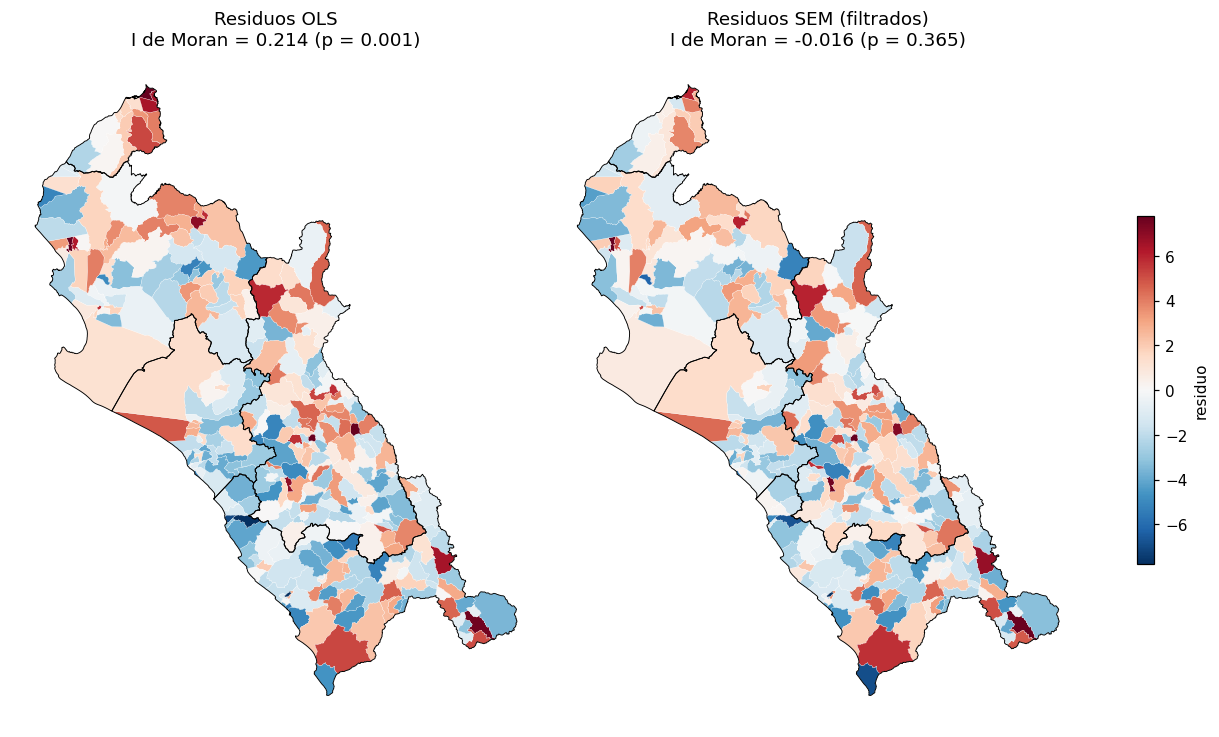

In [10]:
# Residuos: OLS vs SEM
g["res_ols"] = ols.u.flatten()
g["res_sem"] = sem.e_filtered.flatten()
vmax = np.abs(g[["res_ols", "res_sem"]]).quantile(0.98).max()
deps = g.dissolve("departamento").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 6.8), constrained_layout=True)
for ax, col, titulo in [(axes[0], "res_ols", "Residuos OLS"), (axes[1], "res_sem", "Residuos SEM (filtrados)")]:
    mi = Moran(g[col], w, permutations=999)
    g.plot(column=col, cmap="RdBu_r", vmin=-vmax, vmax=vmax, ax=ax, edgecolor="white", linewidth=0.15)
    deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(f"{titulo}\nI de Moran = {mi.I:.3f} (p = {mi.p_sim:.3f})")
    ax.set_axis_off()
sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(-vmax, vmax))
fig.colorbar(sm, ax=axes, shrink=0.5, label="residuo")
fig.savefig(FIG / "04_residuos_ols_sem.png", bbox_inches="tight")
plt.show()

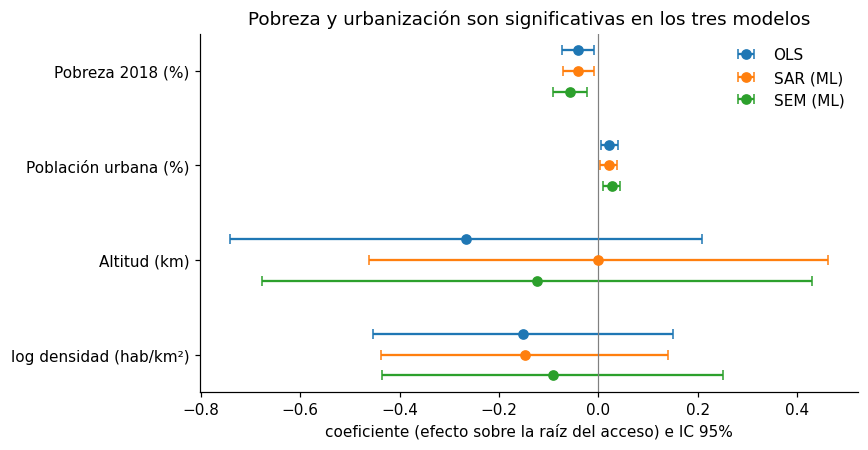

In [11]:
# Coeficientes con intervalos al 95%: OLS vs SAR vs SEM (ML)
modelos = {"OLS": (ols, "t_stat"), "SAR (ML)": (sar, "z_stat"), "SEM (ML)": (sem, "z_stat")}
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, (nombre, (m, _)) in enumerate(modelos.items()):
    nx = list(m.name_x)
    idx = [nx.index(v) for v in X_NAMES]
    b = m.betas.flatten()[idx]
    se = m.std_err[idx]
    pos = np.arange(len(X_NAMES)) + (k - 1) * 0.22
    ax.errorbar(b, pos, xerr=1.96 * se, fmt="o", capsize=3, label=nombre)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_yticks(np.arange(len(X_NAMES)), [ETIQUETAS[v] for v in X_NAMES])
ax.invert_yaxis()
ax.set_xlabel("coeficiente (efecto sobre la raíz del acceso) e IC 95%")
ax.legend(frameon=False)
ax.set_title("Pobreza y urbanización son significativas en los tres modelos")
fig.tight_layout()
fig.savefig(FIG / "04_coeficientes.png", bbox_inches="tight")
plt.show()

## 8. Hallazgos para el proyecto

1. **El OLS no sirve como modelo final.** Explica 23% de la varianza, pero sus residuos tienen I de Moran = 0,21
   (p < 0,001): los errores estándar no son válidos.
2. **Las pruebas LM apuntan al error espacial.** Las dos versiones robustas son significativas, pero LM-error
   robusto (31,4) supera a LM-rezago robusto (15,3). El **SEM** baja el AIC de 1696 a 1662 y deja residuos sin
   autocorrelación (I = -0,02). El λ = 0,45 indica factores no observados con estructura espacial (vías,
   geografía, dinámica de mercados).
3. **Los efectos son robustos a la especificación.** En OLS, SAR, SEM (ML y GMM) y SDM, la pobreza reduce el
   acceso y la urbanización lo aumenta, siempre con p < 0,05. Con el SEM por ML, 10 puntos más de pobreza
   restan 0,57 a la raíz del acceso, alrededor de 11 puntos de atención por 10 mil adultos en la mediana.
4. **El mejor ajuste es el modelo de Durbin (SDM, AIC 1648).** La prueba de factor común rechaza la restricción
   que llevaría al SEM (p = 0,0004). La urbanización tiene un efecto directo positivo y un **derrame negativo**:
   una ciudad grande concentra la oferta y deja con menos acceso a los distritos vecinos. La altitud solo
   aparece significativa al controlar los rezagos (efecto directo -0,96 por km).
5. **Para el póster** se reportan OLS, SEM y SDM (tabla `outputs/tablas/04_comparacion_modelos.csv`) y el
   mapa de residuos OLS frente a SEM como figura del objetivo 2.

# 05 Mapas Interactivos

Notebook original: `05_mapas_interactivos.ipynb`.

# 05 · Álbum de mapas interactivos

| | |
|---|---|
| **Objetivo** | Integrar en mapas web navegables los resultados de los notebooks 02, 03, 07 y 08, para exploración y comunicación a usuarios de negocio. |
| **Herramienta** | folium (Leaflet), capas conmutables, ventanas emergentes por distrito, agrupación de marcadores y mapa de calor. |
| **Salidas** | `outputs/mapas/*.html` (se abren en cualquier navegador, sin servidor). |

Los mapas no se incrustan en el notebook para que el archivo se mantenga liviano y GitHub pueda mostrarlo;
cada celda guarda un HTML y devuelve su ruta.

In [1]:
from pathlib import Path
import json

import branca.colormap as cm
import folium
import geopandas as gpd
import numpy as np
import pandas as pd
from folium.plugins import Fullscreen, HeatMap, MarkerCluster, MiniMap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
MAPAS = ROOT / "outputs" / "mapas"
MAPAS.mkdir(parents=True, exist_ok=True)
CENTRO = [-6.6, -79.4]
TILES = "OpenStreetMap"   # capa base sin clave de API

## 1. Datos integrados

In [2]:
gpkg = DATA / "geobanca_norte.gpkg"
d = gpd.read_file(gpkg, layer="distritos")
d = (d.merge(pd.read_csv(DATA / "base_aede.csv", dtype={"ubigeo": str})[["ubigeo", "acceso_eb"]], on="ubigeo", how="left")
      .merge(pd.read_csv(DATA / "lisa_acceso.csv", dtype={"ubigeo": str})[["ubigeo", "lisa", "lisa_p", "gi_clase", "lisa_bv"]], on="ubigeo", how="left")
      .merge(pd.read_csv(DATA / "brecha_acceso_2025.csv", dtype={"ubigeo": str})[["ubigeo", "tasa_esperada", "brecha"]], on="ubigeo", how="left"))

# Geometría simplificada (~150 m) y coordenadas redondeadas a 1e-4 grados (~11 m) para que los HTML pesen poco
import shapely
d = d.to_crs("EPSG:32717")
d["geometry"] = d.geometry.simplify(150, preserve_topology=True)
d = d.to_crs("EPSG:4326")
d["geometry"] = shapely.set_precision(d.geometry.values, 1e-4)
deps = d.dissolve("departamento").reset_index()[["departamento", "geometry"]]

sitios = gpd.read_file(gpkg, layer="osm_bancos_atm").to_crs("EPSG:4326")
estaciones = gpd.read_file(gpkg, layer="senamhi_estaciones").to_crs("EPSG:4326")

for c in ["acceso_eb", "pobreza_2018", "pct_urbana", "tasa_esperada", "brecha", "creditos_pc_soles"]:
    d[c] = d[c].astype(float).round(2)
d["pob_total_2025"] = d["pob_total_2025"].fillna(0).astype(int)
print(f"{len(d)} distritos | {len(sitios)} sitios OSM | {len(estaciones)} estaciones SENAMHI")

327 distritos | 395 sitios OSM | 175 estaciones SENAMHI


In [3]:
CAMPOS = ["distrito", "provincia", "departamento", "pob_total_2025", "acceso_eb", "pobreza_2018",
          "pct_urbana", "lisa", "brecha"]
ALIAS = ["Distrito", "Provincia", "Departamento", "Población 2025", "Acceso (EB, por 10 mil adultos)",
         "Pobreza 2018 (%)", "Población urbana (%)", "Cluster LISA", "Brecha (log obs − log esp)"]

def capa_coropletica(m, columna, colormap, nombre, mostrar=True):
    colormap.caption = nombre
    fg = folium.FeatureGroup(name=nombre, show=mostrar)
    folium.GeoJson(
        d[CAMPOS + ["geometry"]].assign(_v=d[columna]).to_json(),
        style_function=lambda f: {"fillColor": colormap(f["properties"]["_v"]) if f["properties"]["_v"] is not None else "#cccccc",
                                  "color": "white", "weight": 0.3, "fillOpacity": 0.8},
        highlight_function=lambda f: {"weight": 2, "color": "black"},
        tooltip=folium.GeoJsonTooltip(fields=CAMPOS, aliases=ALIAS, localize=True, sticky=True),
    ).add_to(fg)
    fg.add_to(m)
    return colormap

def capa_categorica(m, columna, colores, nombre, mostrar=False):
    fg = folium.FeatureGroup(name=nombre, show=mostrar)
    folium.GeoJson(
        d[CAMPOS + ["geometry"]].assign(_c=d[columna]).to_json(),
        style_function=lambda f: {"fillColor": colores.get(f["properties"]["_c"], "#e6e6e6"), "color": "white",
                                  "weight": 0.3, "fillOpacity": 0.85 if f["properties"]["_c"] in colores else 0.25},
        tooltip=folium.GeoJsonTooltip(fields=CAMPOS, aliases=ALIAS, sticky=True),
    ).add_to(fg)
    fg.add_to(m)

def leyenda_html(titulo, colores):
    filas = "".join(f'<div><span style="background:{c};width:12px;height:12px;display:inline-block;margin-right:6px"></span>{k}</div>'
                    for k, c in colores.items())
    estilo = ("position:fixed;bottom:30px;left:10px;z-index:9999;background:white;padding:8px 10px;"
              "border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.3);font-size:12px")
    return folium.Element(f'<div style="{estilo}"><b>{titulo}</b>{filas}</div>')

def base(zoom=7):
    m = folium.Map(location=CENTRO, zoom_start=zoom, tiles=TILES, control_scale=True)
    folium.GeoJson(deps.to_json(), name="Departamentos",
                   style_function=lambda f: {"fill": False, "color": "#333333", "weight": 1.2}).add_to(m)
    Fullscreen().add_to(m)
    MiniMap(toggle_display=True).add_to(m)
    return m

## 2. Mapa principal: acceso, pobreza, clusters y brecha

In [4]:
m = base()
cmap_acc = cm.LinearColormap(["#ffffcc", "#41b6c4", "#081d58"], vmin=float(d["acceso_eb"].quantile(0.02)),
                             vmax=float(d["acceso_eb"].quantile(0.98)))
capa_coropletica(m, "acceso_eb", cmap_acc, "Acceso a canales (por 10 mil adultos, EB)").add_to(m)
cmap_pob = cm.LinearColormap(["#fff5eb", "#fd8d3c", "#7f2704"], vmin=0, vmax=80)
capa_coropletica(m, "pobreza_2018", cmap_pob, "Pobreza monetaria 2018 (%)", mostrar=False)

COL_LISA = {"Alto-Alto": "#d7191c", "Bajo-Bajo": "#2c7bb6", "Bajo-Alto": "#abd9e9", "Alto-Bajo": "#fdae61"}
capa_categorica(m, "lisa", COL_LISA, "Clusters LISA (p < 0,05)")
COL_BV = {"Pobre / vecinos sin acceso": "#7b3294", "No pobre / vecinos con acceso": "#008837",
          "Pobre / vecinos con acceso": "#c2a5cf", "No pobre / vecinos sin acceso": "#a6dba0"}
capa_categorica(m, "lisa_bv", COL_BV, "LISA bivariado pobreza / acceso de vecinos")

lim = float(np.nanpercentile(np.abs(d["brecha"]), 97))
cmap_br = cm.LinearColormap(["#b2182b", "#f7f7f7", "#2166ac"], vmin=-lim, vmax=lim)
capa_coropletica(m, "brecha", cmap_br, "Brecha de acceso (rojo = desatendido)", mostrar=False)

folium.LayerControl(collapsed=False).add_to(m)
m.get_root().html.add_child(leyenda_html("Clusters LISA", {**COL_LISA, "No significativo": "#e6e6e6"}))
ruta = MAPAS / "05_mapa_principal.html"
m.save(ruta)
print(ruta.relative_to(ROOT), f"{ruta.stat().st_size / 1e6:.1f} MB")

outputs/mapas/05_mapa_principal.html 3.2 MB


## 3. Desiertos financieros: distritos Bajo-Bajo y su población

In [5]:
m = base(zoom=8)
des = d[d["lisa"] == "Bajo-Bajo"]
folium.GeoJson(d[["geometry"]].to_json(), style_function=lambda f: {"fillColor": "#f2f2f2", "color": "white",
               "weight": 0.3, "fillOpacity": 0.5}).add_to(m)
folium.GeoJson(
    des[CAMPOS + ["geometry"]].to_json(), name="Desiertos financieros",
    style_function=lambda f: {"fillColor": "#2c7bb6", "color": "#08306b", "weight": 1, "fillOpacity": 0.75},
    tooltip=folium.GeoJsonTooltip(fields=CAMPOS, aliases=ALIAS, sticky=True)).add_to(m)
for _, r in des.iterrows():
    p = r.geometry.representative_point()
    folium.CircleMarker([p.y, p.x], radius=3 + np.sqrt(r["pob_total_2025"]) / 25, color="#08306b",
                        fill=True, fill_opacity=0.9, weight=1,
                        popup=f"<b>{r['distrito']}</b><br>{r['pob_total_2025']:,} hab.<br>acceso EB: {r['acceso_eb']}").add_to(m)
m.fit_bounds(des.total_bounds[[1, 0, 3, 2]].reshape(2, 2).tolist())
ruta = MAPAS / "05_desiertos_financieros.html"
m.save(ruta)
print(ruta.relative_to(ROOT), f"{ruta.stat().st_size / 1e6:.1f} MB | {len(des)} distritos, {des['pob_total_2025'].sum():,} habitantes")

outputs/mapas/05_desiertos_financieros.html 0.8 MB | 19 distritos, 212,000 habitantes


## 4. Oferta georreferenciada: bancos y cajeros (OSM) con mapa de calor

In [6]:
m = base()
ICONO = {"bank": ("university", "darkblue"), "atm": ("credit-card", "green"),
         "bureau_de_change": ("usd", "orange"), "payment_centre": ("shopping-cart", "gray")}
cl = MarkerCluster(name="Bancos y ATM (OSM)").add_to(m)
for _, r in sitios.iterrows():
    ic, col = ICONO.get(r["amenity"], ("info-sign", "gray"))
    nombre = r["nombre"] if isinstance(r["nombre"], str) else (r["marca"] if isinstance(r["marca"], str) else r["amenity"])
    folium.Marker([r.geometry.y, r.geometry.x], popup=f"<b>{nombre}</b><br>{r['amenity']}",
                  icon=folium.Icon(icon=ic, prefix="fa", color=col)).add_to(cl)
HeatMap(np.column_stack([sitios.geometry.y, sitios.geometry.x]).tolist(), name="Mapa de calor",
        radius=14, blur=18, min_opacity=0.3, show=False).add_to(m)
fg_est = folium.FeatureGroup(name="Estaciones SENAMHI", show=False)
for _, r in estaciones.iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=3, color="#6a3d9a", fill=True, fill_opacity=0.8,
                        popup=f"{r['nombre']} ({r['categoria']}, {r['estado']})").add_to(fg_est)
fg_est.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
ruta = MAPAS / "05_oferta_osm.html"
m.save(ruta)
print(ruta.relative_to(ROOT), f"{ruta.stat().st_size / 1e6:.1f} MB")

outputs/mapas/05_oferta_osm.html 0.9 MB


## 5. Índice de mapas generados

In [7]:
for f in sorted(MAPAS.glob("05_*.html")):
    print(f"{f.name:32s} {f.stat().st_size / 1e6:5.1f} MB")

05_desiertos_financieros.html      0.8 MB
05_mapa_principal.html             3.2 MB
05_oferta_osm.html                 0.9 MB


**Cómo verlos.** Abrir los archivos de `outputs/mapas/` con doble clic. Para publicarlos en la web basta activar
GitHub Pages en el repositorio y enlazar los HTML desde el README.

**Qué muestra cada mapa**

| Archivo | Contenido | Uso |
|---|---|---|
| `05_mapa_principal.html` | Acceso suavizado, pobreza, clusters LISA, LISA bivariado y brecha, como capas conmutables con ficha por distrito | Exploración general y exposición |
| `05_desiertos_financieros.html` | Los 19 distritos Bajo-Bajo con círculos proporcionales a su población | Priorización comercial |
| `05_oferta_osm.html` | Bancos y ATM agrupados, mapa de calor y estaciones SENAMHI | Contexto de la oferta y de la red de monitoreo climático |

# 06 Geoestadistica Precipitacion

Notebook original: `06_geoestadistica_precipitacion.ipynb`.

# 06 · Geoestadística de la precipitación extrema

| | |
|---|---|
| **Pregunta** | ¿Con qué precisión puede reconstruirse el campo de lluvia de un evento extremo a partir de la red de estaciones que realmente existe en el norte, y dónde se concentra el error? |
| **Datos** | CHIRPS v2.0 mensual (0,05°, ≈ 5,5 km) de marzo de 1998, 2017 y 2023; coordenadas de 235 estaciones meteorológicas SENAMHI (red actual e histórica) dentro del ámbito; Copernicus DEM GLO-90 agregado a la grilla de CHIRPS; límites distritales INEI. |
| **Diseño** | Se observa el campo solo en los píxeles con estación (red real) y se interpola al resto. Como el campo completo es conocido, el error se mide en cada píxel y no solo en las estaciones. |
| **Métodos** | Semivariograma empírico (estimador de Matheron) y ajuste por mínimos cuadrados ponderados (Cressie, 1985); variogramas direccionales para anisotropía; interpolación por distancia inversa (IDW) como referencia; kriging ordinario y kriging con deriva externa de altitud (Goovaerts, 2000); validación cruzada dejando uno fuera y validación contra el campo completo; ratio de error cuadrático estandarizado (MSDR) para calibrar la varianza de kriging. |
| **Salidas** | `outputs/figuras/06_*.png` · `outputs/tablas/06_validacion_interpolacion.csv` · `data/processed/lluvia_extrema_distrito.csv`. |

**Sobre la fuente.** CHIRPS combina satélite con pluviómetros (incluidos los de SENAMHI) y es el producto de referencia
para lluvia mensual en zonas con red escasa (Funk et al., 2015). Aquí cumple el papel de *campo verdadero*: los valores
en las estaciones son los del píxel CHIRPS que las contiene, no el registro del pluviómetro. Lo que se evalúa es
cuánta información pierde la geometría de la red, que es la pregunta relevante para un mapa de exposición.

In [1]:
from pathlib import Path
import time
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import statsmodels.api as sm
from pykrige.ok import OrdinaryKriging
from pykrige.uk import UniversalKriging
from pyproj import Transformer
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.merge import merge
from rasterio.warp import reproject
from rasterio.windows import from_bounds
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")
t0 = time.time()

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
TAB = ROOT / "outputs" / "tablas"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
A_UTM = Transformer.from_crs(4326, 32717, always_xy=True)

## 1. Campo de referencia, relieve y red de estaciones

In [2]:
distritos = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos")
departamentos = distritos.dissolve("departamento").reset_index()
region = distritos.dissolve().geometry.iloc[0]
bounds = distritos.total_bounds + np.array([-0.1, -0.1, 0.1, 0.1])

def leer_chirps(ym):
    with rasterio.open(RAW / "chirps" / f"chirps-v2.0.{ym}.tif") as src:
        win = from_bounds(*bounds, transform=src.transform)
        arr = src.read(1, window=win).astype(float)
        tr = src.window_transform(win)
    arr[arr < 0] = np.nan
    return arr, tr

EVENTOS = {"1998-03": "El Niño extraordinario", "2017-03": "El Niño costero", "2023-03": "Ciclón Yaku"}
campos = {}
for ev in EVENTOS:
    campos[ev], TR = leer_chirps(ev.replace("-", "."))
FORMA = campos["1998-03"].shape
MASK = geometry_mask([region], out_shape=FORMA, transform=TR, invert=True)

# DEM de 90 m llevado a la grilla CHIRPS por promedio de área
teselas = [rasterio.open(f) for f in sorted((RAW / "dem").glob("*.tif"))]
dem, dem_tr = merge(teselas, bounds=tuple(bounds), res=(1 / 120, 1 / 120))
ALT = np.full(FORMA, np.nan)
reproject(dem[0].astype(float), ALT, src_transform=dem_tr, src_crs="EPSG:4326",
          dst_transform=TR, dst_crs="EPSG:4326", resampling=Resampling.average)
for t in teselas:
    t.close()

# Píxeles de la grilla en km (UTM 17S)
rr, cc = np.where(MASK)
lon_g, lat_g = rasterio.transform.xy(TR, rr, cc)
xg, yg = A_UTM.transform(np.array(lon_g), np.array(lat_g))
xg, yg = xg / 1000, yg / 1000
alt_g = ALT[rr, cc] / 1000
print(f"Píxeles en el ámbito: {MASK.sum():,} | altitud media {np.nanmean(alt_g)*1000:,.0f} m")

# Estaciones meteorológicas SENAMHI (red actual tipo M + catálogo histórico)
e1 = pd.read_csv(RAW / "senamhi" / "estaciones_red_actual.csv", dtype=str).query("tipo == 'M'")
e2 = pd.read_csv(RAW / "senamhi" / "estaciones_descarga_historica.csv", dtype=str)
est = (pd.concat([e1[["codigo", "nombre", "lat", "lon"]], e2[["codigo", "nombre", "lat", "lon"]]])
         .drop_duplicates("codigo").astype({"lat": float, "lon": float}))
est = gpd.GeoDataFrame(est, geometry=gpd.points_from_xy(est.lon, est.lat), crs=4326)
est = est[est.within(region)].copy()
est["r"], est["c"] = rasterio.transform.rowcol(TR, est.lon.values, est.lat.values)

# Varias estaciones caen en el mismo píxel: se colapsan (un dato por soporte)
red = (est.groupby(["r", "c"]).agg(lon=("lon", "mean"), lat=("lat", "mean"), n_est=("codigo", "size"))
          .reset_index())
red["x"], red["y"] = A_UTM.transform(red.lon.values, red.lat.values)
red["x"] /= 1000; red["y"] /= 1000
red["alt"] = ALT[red.r, red.c] / 1000
print(f"Estaciones en el ámbito: {len(est)} | píxeles distintos con estación: {len(red)}")

d_vecino, _ = cKDTree(red[["x", "y"]].values).query(np.c_[xg, yg])
print(f"Distancia del píxel a la estación más cercana: mediana {np.median(d_vecino):.1f} km, "
      f"p90 {np.percentile(d_vecino, 90):.1f} km, máx {d_vecino.max():.0f} km")

Píxeles en el ámbito: 3,695 | altitud media 1,351 m
Estaciones en el ámbito: 235 | píxeles distintos con estación: 149
Distancia del píxel a la estación más cercana: mediana 14.5 km, p90 42.4 km, máx 112 km


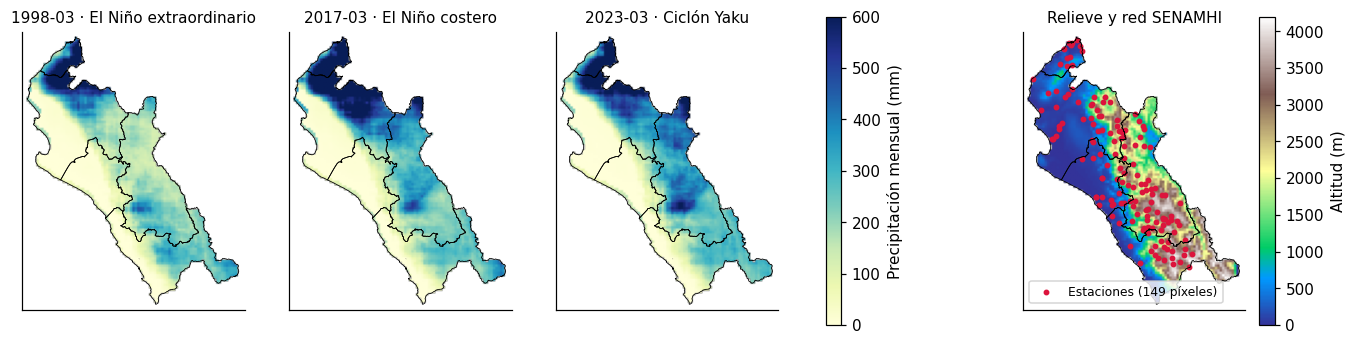

In [3]:
def a_imagen(v):
    img = np.full(FORMA, np.nan); img[rr, cc] = v; return img

EXT = [TR.c, TR.c + TR.a * FORMA[1], TR.f + TR.e * FORMA[0], TR.f]
def fondo(ax, titulo):
    departamentos.boundary.plot(ax=ax, color="k", lw=0.5)
    ax.set_title(titulo, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")

fig, axs = plt.subplots(1, 4, figsize=(15, 5.2))
for ax, ev in zip(axs[:3], EVENTOS):
    im = ax.imshow(np.where(MASK, campos[ev], np.nan), extent=EXT, cmap="YlGnBu", vmin=0, vmax=600)
    fondo(ax, f"{ev} · {EVENTOS[ev]}")
plt.colorbar(im, ax=axs[:3], shrink=0.7, label="Precipitación mensual (mm)")
im = axs[3].imshow(np.where(MASK, ALT, np.nan), extent=EXT, cmap="terrain", vmin=0, vmax=4200)
axs[3].scatter(red.lon, red.lat, s=8, c="crimson", label=f"Estaciones ({len(red)} píxeles)")
fondo(axs[3], "Relieve y red SENAMHI"); axs[3].legend(loc="lower left", fontsize=8)
plt.colorbar(im, ax=axs[3], shrink=0.7, label="Altitud (m)")
plt.savefig(FIG / "06_campos_y_red.png", bbox_inches="tight"); plt.show()

**Lectura.** Los tres eventos concentran la lluvia en Tumbes y en el nororiente de Piura, con más de 600 mm en el
mes en zonas que son semiáridas en un año normal; marzo de 2017 y de 2023 superan a marzo de 1998 (cuyo pico fue
en enero y febrero) y además marcan un núcleo en la sierra sur de Cajamarca. La red está densa en la sierra de
Cajamarca y en los valles costeros, y rala en el litoral de Sechura y Lambayeque y en el extremo oriental de La
Libertad, donde hay píxeles a más de 100 km de una estación. Esa geometría es la que se pone a prueba.

## 2. Semivariograma

La lluvia mensual es muy asimétrica (ceros en el desierto, cientos de milímetros en la sierra), por eso se modela
Z = log(1 + P). El semivariograma empírico usa el estimador de Matheron en clases de 20 km y los modelos esférico,
exponencial y gaussiano se ajustan por mínimos cuadrados ponderados con pesos N(h)/γ(h)², que priorizan las
distancias cortas, las que más pesan en la predicción.

In [4]:
CLASES = np.arange(0, 260, 20)

def esferico(h, c0, c, a):  return np.where(h < a, c0 + c * (1.5 * h / a - 0.5 * (h / a) ** 3), c0 + c)
def exponencial(h, c0, c, a): return c0 + c * (1 - np.exp(-3 * h / a))
def gaussiano(h, c0, c, a):  return c0 + c * (1 - np.exp(-3 * (h / a) ** 2))
MODELOS = {"Esférico": esferico, "Exponencial": exponencial, "Gaussiano": gaussiano}

def variograma_empirico(x, y, v, angulo=None, tol=22.5):
    pares = np.c_[x, y]
    D = pdist(pares); G = 0.5 * pdist(v[:, None]) ** 2
    if angulo is not None:
        i, j = np.triu_indices(len(x), 1)
        az = np.degrees(np.arctan2(x[j] - x[i], y[j] - y[i])) % 180
        dif = np.abs((az - angulo + 90) % 180 - 90)
        D, G = D[dif <= tol], G[dif <= tol]
    k = np.digitize(D, CLASES); h, g, n = [], [], []
    for b in range(1, len(CLASES)):
        s = k == b
        if s.sum() >= 20:
            h.append(D[s].mean()); g.append(G[s].mean()); n.append(s.sum())
    return np.array(h), np.array(g), np.array(n)

def ajustar(h, g, n, f):
    p0 = [0.1, g.max(), 100]
    p, _ = curve_fit(f, h, g, p0=p0, bounds=([0, 0, 5], [5, 10, 1000]), sigma=f(h, *p0) / np.sqrt(n))
    wss = (n / f(h, *p) ** 2 * (g - f(h, *p)) ** 2).sum()
    return p, wss

red["z98"] = np.log1p(campos["1998-03"][red.r, red.c])
h, g, n = variograma_empirico(red.x.values, red.y.values, red.z98.values)
filas = []
for nom, f in MODELOS.items():
    p, wss = ajustar(h, g, n, f)
    filas.append({"modelo": nom, "pepita": p[0], "meseta_parcial": p[1], "rango_km": p[2], "WSS": wss})
ajustes = pd.DataFrame(filas).set_index("modelo")
ajustes.round(3)

,pepita,meseta_parcial,rango_km,WSS
modelo,,,,
Esférico,0.000,2.639,176.780,115.748
Exponencial,0.000,3.252,330.643,217.946
Gaussiano,0.236,2.440,147.131,46.347


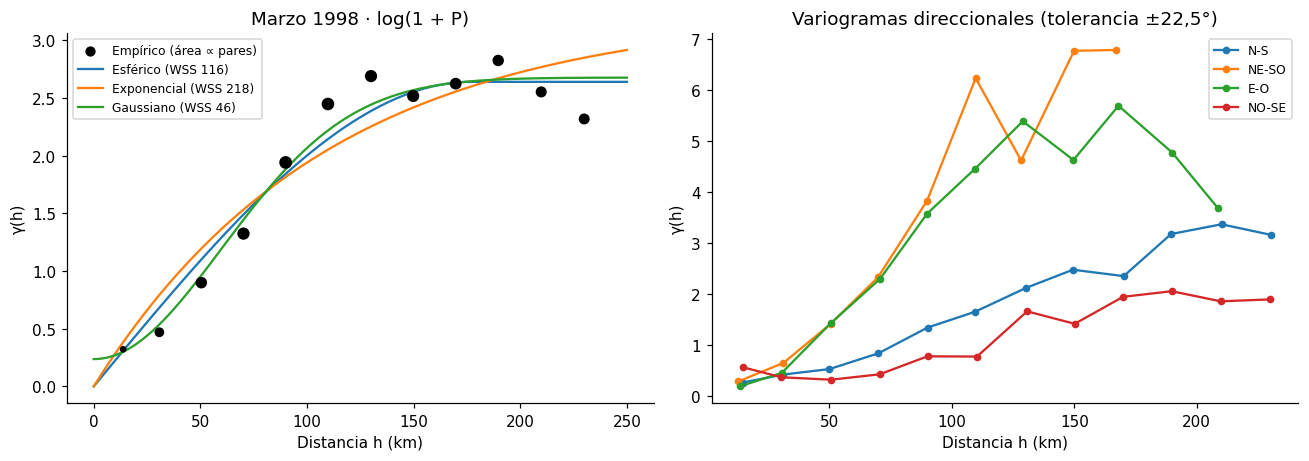

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axs[0]
ax.scatter(h, g, s=n / 15, c="k", zorder=3, label="Empírico (área ∝ pares)")
hh = np.linspace(0, 250, 300)
for nom, f in MODELOS.items():
    ax.plot(hh, f(hh, *ajustes.loc[nom, ["pepita", "meseta_parcial", "rango_km"]]),
            label=f"{nom} (WSS {ajustes.loc[nom, 'WSS']:.0f})")
ax.set(xlabel="Distancia h (km)", ylabel="γ(h)", title="Marzo 1998 · log(1 + P)"); ax.legend(fontsize=8)

ax = axs[1]
for ang, nom in [(0, "N-S"), (45, "NE-SO"), (90, "E-O"), (135, "NO-SE")]:
    hd, gd, nd = variograma_empirico(red.x.values, red.y.values, red.z98.values, angulo=ang)
    ax.plot(hd, gd, "o-", ms=4, label=nom)
ax.set(xlabel="Distancia h (km)", ylabel="γ(h)", title="Variogramas direccionales (tolerancia ±22,5°)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "06_semivariograma.png", bbox_inches="tight"); plt.show()

**Lectura.** El modelo gaussiano tiene el menor error ponderado: el campo es suave a escala de decenas de
kilómetros, con pepita pequeña (0,24 frente a una meseta de 2,7) y rango práctico cercano a 150 km, la escala de
los sistemas de lluvia de El Niño. Los variogramas direccionales muestran **anisotropía marcada**: en dirección
NE-SO y E-O (perpendicular a la costa) la semivarianza a 90-110 km es entre cinco y siete veces la de la dirección NO-SE (paralela a la
costa). El campo cambia rápido de la costa hacia la sierra y lento a lo largo de ella; la altitud como deriva
externa es la forma natural de capturar ese gradiente.

## 3. Interpoladores

* **IDW** (potencia 2): referencia determinista sin modelo de dependencia.
* **Kriging ordinario (KO):** media local desconocida y variograma gaussiano ajustado arriba.
* **Kriging con deriva externa (KDE):** la media depende linealmente de la altitud del DEM, disponible en cada
  píxel. El variograma se reajusta sobre los residuos de la deriva (Hengl, Heuvelink y Rossiter, 2007).

La selección de la deriva se hizo solo con validación cruzada en las estaciones (sección 4): agregar la altitud al
cuadrado o las coordenadas mejora poco dentro de la red y extrapola mal fuera de ella.

In [6]:
def gauss_pk(p, h):            # firma que espera pykrige para variogramas propios
    return gaussiano(h, *p)

def ajustar_variograma(x, y, v):
    hh, gg, nn = variograma_empirico(x, y, v)
    return ajustar(hh, gg, nn, gaussiano)[0]

def idw(xt, yt, xs, ys, zs, pot=2):
    d = np.hypot(xt[:, None] - xs, yt[:, None] - ys) + 1e-6
    w = d ** -pot
    return (w * zs).sum(1) / w.sum(1), None

def ko(xt, yt, xs, ys, zs, p):
    m = OrdinaryKriging(xs, ys, zs, variogram_model="custom", variogram_parameters=list(p),
                        variogram_function=gauss_pk)
    z, s2 = m.execute("points", xt, yt)
    return np.asarray(z), np.asarray(s2)

def kde(xt, yt, at, xs, ys, as_, zs, p):
    m = UniversalKriging(xs, ys, zs, variogram_model="custom", variogram_parameters=list(p),
                         variogram_function=gauss_pk, drift_terms=["specified"], specified_drift=[as_])
    z, s2 = m.execute("points", xt, yt, specified_drift_arrays=[at])
    return np.asarray(z), np.asarray(s2)

def evaluar_evento(ev):
    campo = campos[ev]
    z = np.log1p(campo[red.r, red.c]); x, y, a = red.x.values, red.y.values, red.alt.values
    p_ko = ajustar_variograma(x, y, z)
    res = sm.OLS(z, sm.add_constant(a)).fit()
    p_kde = ajustar_variograma(x, y, res.resid)
    # Validación cruzada dejando uno fuera (variograma fijo, práctica estándar)
    loo = {"IDW": np.empty(len(z)), "KO": np.empty(len(z)), "KDE": np.empty(len(z))}
    var = {"KO": np.empty(len(z)), "KDE": np.empty(len(z))}
    for i in range(len(z)):
        s = np.arange(len(z)) != i
        loo["IDW"][i] = idw(x[[i]], y[[i]], x[s], y[s], z[s])[0][0]
        zk, vk = ko(x[[i]], y[[i]], x[s], y[s], z[s], p_ko); loo["KO"][i], var["KO"][i] = zk[0], vk[0]
        zk, vk = kde(x[[i]], y[[i]], a[[i]], x[s], y[s], a[s], z[s], p_kde); loo["KDE"][i], var["KDE"][i] = zk[0], vk[0]
    # Predicción sobre todo el campo
    grid = {"IDW": idw(xg, yg, x, y, z), "KO": ko(xg, yg, x, y, z, p_ko),
            "KDE": kde(xg, yg, alt_g, x, y, a, z, p_kde)}
    verdad = campo[rr, cc]
    filas = []
    for m in loo:
        e_loo = np.expm1(loo[m]) - np.expm1(z)
        e_g = np.expm1(grid[m][0]) - verdad
        filas.append({"evento": ev, "metodo": m,
                      "RMSE_LOO_mm": np.sqrt(np.mean(e_loo ** 2)), "MAE_LOO_mm": np.mean(np.abs(e_loo)),
                      "MSDR_LOO": np.mean((loo[m] - z) ** 2 / var[m]) if m in var else np.nan,
                      "RMSE_campo_mm": np.sqrt(np.mean(e_g ** 2)), "MAE_campo_mm": np.mean(np.abs(e_g)),
                      "sesgo_campo_mm": np.mean(e_g), "r_campo": np.corrcoef(np.expm1(grid[m][0]), verdad)[0, 1]})
    return pd.DataFrame(filas), grid, loo, z, p_ko, p_kde, res

resultados = {ev: evaluar_evento(ev) for ev in EVENTOS}
validacion = pd.concat([r[0] for r in resultados.values()], ignore_index=True)
validacion.to_csv(TAB / "06_validacion_interpolacion.csv", index=False)
print(f"Tiempo acumulado: {time.time() - t0:.0f} s")
validacion.round(2)

Tiempo acumulado: 34 s


,evento,metodo,RMSE_LOO_mm,MAE_LOO_mm,MSDR_LOO,RMSE_campo_mm,MAE_campo_mm,sesgo_campo_mm,r_campo
0,1998-03,IDW,94.68,56.40,NaN,101.01,57.94,-20.07,0.86
1,1998-03,KO,72.54,50.52,1.61,74.86,48.24,-13.59,0.91
2,1998-03,KDE,74.78,51.66,1.42,74.07,50.72,-17.08,0.91
3,2017-03,IDW,136.91,78.94,NaN,155.01,83.91,-39.36,0.88
4,2017-03,KO,95.25,60.68,1.67,98.23,59.46,-13.62,0.94
5,2017-03,KDE,98.57,64.39,1.50,96.58,62.72,-17.24,0.94
6,2023-03,IDW,111.10,72.51,NaN,115.07,73.49,-34.64,0.89
7,2023-03,KO,94.09,62.86,1.64,86.00,56.14,-13.68,0.92
8,2023-03,KDE,94.88,65.53,1.47,84.77,58.86,-16.12,0.92


In [7]:
_, grid98, loo98, z98, p_ko98, p_kde98, res98 = resultados["1998-03"]
print("Variograma KO  (pepita, meseta parcial, rango km):", np.round(p_ko98, 3))
print("Variograma KDE sobre residuos                     :", np.round(p_kde98, 3))
print(f"Deriva KDE: log(1+P) = {res98.params[0]:.2f} + {res98.params[1]:.2f}·altitud(km)  "
      f"(R² = {res98.rsquared:.2f})")
resumen = validacion.groupby("metodo")[["RMSE_LOO_mm", "RMSE_campo_mm", "r_campo"]].mean()
resumen.round(2)

Variograma KO  (pepita, meseta parcial, rango km): [  0.236   2.44  147.131]
Variograma KDE sobre residuos                     : [  0.303   1.667 157.396]
Deriva KDE: log(1+P) = 4.24 + 0.47·altitud(km)  (R² = 0.16)


,RMSE_LOO_mm,RMSE_campo_mm,r_campo
metodo,,,
IDW,114.23,123.70,0.88
KDE,89.41,85.14,0.93
KO,87.29,86.36,0.92


## 4. Mapas de predicción e incertidumbre (marzo de 1998)

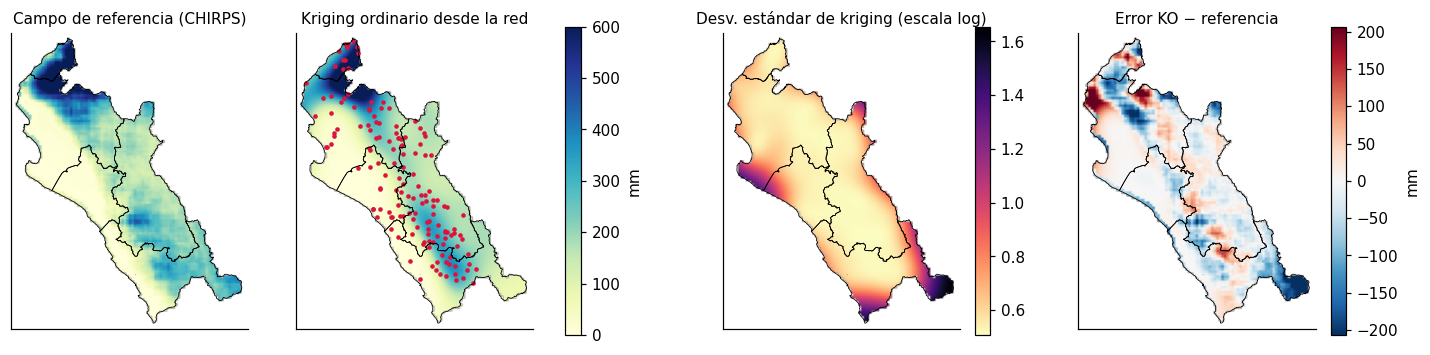

In [8]:
verdad98 = campos["1998-03"][rr, cc]
pred_ko = np.expm1(grid98["KO"][0]); sd_ko = np.sqrt(grid98["KO"][1])
err_ko = pred_ko - verdad98

fig, axs = plt.subplots(1, 4, figsize=(16, 5.2))
im = axs[0].imshow(a_imagen(verdad98), extent=EXT, cmap="YlGnBu", vmin=0, vmax=600); fondo(axs[0], "Campo de referencia (CHIRPS)")
axs[1].imshow(a_imagen(pred_ko), extent=EXT, cmap="YlGnBu", vmin=0, vmax=600); fondo(axs[1], "Kriging ordinario desde la red")
axs[1].scatter(red.lon, red.lat, s=4, c="crimson")
plt.colorbar(im, ax=axs[:2], shrink=0.7, label="mm")
im = axs[2].imshow(a_imagen(sd_ko), extent=EXT, cmap="magma_r"); fondo(axs[2], "Desv. estándar de kriging (escala log)")
plt.colorbar(im, ax=axs[2], shrink=0.7)
lim = np.nanpercentile(np.abs(err_ko), 97)
im = axs[3].imshow(a_imagen(err_ko), extent=EXT, cmap="RdBu_r", vmin=-lim, vmax=lim); fondo(axs[3], "Error KO − referencia")
plt.colorbar(im, ax=axs[3], shrink=0.7, label="mm")
plt.savefig(FIG / "06_kriging_1998.png", bbox_inches="tight"); plt.show()

## 5. ¿Dónde falla la red?

Correlación de Spearman entre la desv. estándar de kriging y el error absoluto real: 0.35


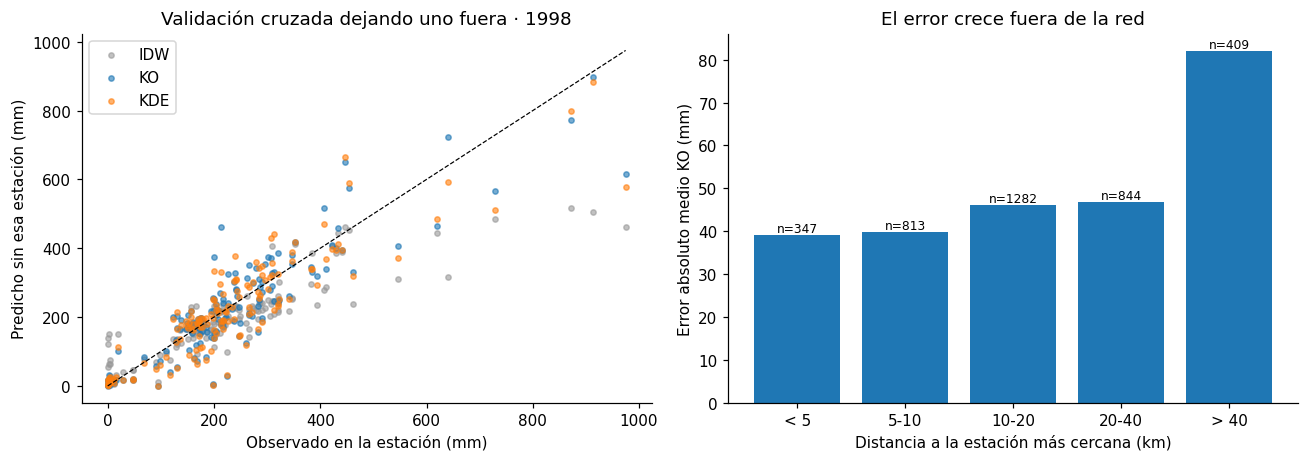

,pixeles,MAE_mm,sd_kriging
tramo,,,
< 5,347,39.11,0.53
5-10,813,39.88,0.54
10-20,1282,46.15,0.56
20-40,844,46.88,0.67
> 40,409,81.98,1.15


In [9]:
tramos = pd.cut(d_vecino, [0, 5, 10, 20, 40, 200], labels=["< 5", "5-10", "10-20", "20-40", "> 40"])
por_dist = (pd.DataFrame({"tramo": tramos, "abs_err": np.abs(err_ko), "sd": sd_ko})
              .groupby("tramo", observed=True).agg(pixeles=("abs_err", "size"), MAE_mm=("abs_err", "mean"),
                                                   sd_kriging=("sd", "mean")))
rho_sd = pd.Series(sd_ko).corr(pd.Series(np.abs(np.log1p(pred_ko) - np.log1p(verdad98))), method="spearman")
print(f"Correlación de Spearman entre la desv. estándar de kriging y el error absoluto real: {rho_sd:.2f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
for m, col in [("IDW", "0.6"), ("KO", "C0"), ("KDE", "C1")]:
    axs[0].scatter(np.expm1(z98), np.expm1(loo98[m]), s=12, alpha=0.6, color=col, label=m)
mx = np.expm1(z98).max(); axs[0].plot([0, mx], [0, mx], "k--", lw=0.8)
axs[0].set(xlabel="Observado en la estación (mm)", ylabel="Predicho sin esa estación (mm)",
           title="Validación cruzada dejando uno fuera · 1998"); axs[0].legend()
axs[1].bar(por_dist.index.astype(str), por_dist.MAE_mm, color="C0")
for i, v in enumerate(por_dist.pixeles): axs[1].text(i, por_dist.MAE_mm.iloc[i], f"n={v}", ha="center", va="bottom", fontsize=8)
axs[1].set(xlabel="Distancia a la estación más cercana (km)", ylabel="Error absoluto medio KO (mm)",
           title="El error crece fuera de la red")
plt.tight_layout(); plt.savefig(FIG / "06_validacion.png", bbox_inches="tight"); plt.show()
por_dist.round(2)

## 6. Exposición distrital a lluvia extrema

Para el score del notebook 09 se usa el **campo de referencia** (es la mejor estimación disponible en cada píxel) y
se agrega por distrito como el promedio de los píxeles cuyo centro cae dentro. Los distritos más pequeños que un
píxel toman el valor del píxel de su centroide. El índice de exposición promedia los puntajes z de los tres eventos,
de modo que pesa igual un distrito golpeado por los tres que uno golpeado por uno solo con intensidad extrema.
Se exporta también la desviación estándar de kriging de 1998 como indicador de cuán observada está la zona.

In [10]:
pix = gpd.GeoDataFrame({"i": np.arange(len(rr))}, geometry=gpd.points_from_xy(lon_g, lat_g), crs=4326)
for ev in EVENTOS:
    pix[f"pp_{ev[:4]}"] = campos[ev][rr, cc]
pix["sd_kriging_1998"] = sd_ko
cols = [c for c in pix.columns if c.startswith(("pp_", "sd_"))]
zonal = gpd.sjoin(pix, distritos[["ubigeo", "geometry"]], predicate="within").groupby("ubigeo")[cols].mean()

faltan = distritos[~distritos.ubigeo.isin(zonal.index)]
cent = faltan.to_crs(32717).geometry.centroid.to_crs(4326)
fr, fc = rasterio.transform.rowcol(TR, cent.x.values, cent.y.values)
relleno = pd.DataFrame({f"pp_{ev[:4]}": campos[ev][fr, fc] for ev in EVENTOS}, index=faltan.ubigeo)
_, idx = cKDTree(np.c_[lon_g, lat_g]).query(np.c_[cent.x, cent.y])
relleno["sd_kriging_1998"] = sd_ko[idx]
lluvia = pd.concat([zonal, relleno]).rename_axis("ubigeo").reset_index()
lluvia["fuente_valor"] = np.where(lluvia.ubigeo.isin(zonal.index), "promedio_pixeles", "pixel_centroide")

zs = [(lluvia[c] - lluvia[c].mean()) / lluvia[c].std() for c in lluvia.columns if c.startswith("pp_")]
lluvia["indice_exposicion"] = np.mean(zs, axis=0)
lluvia = lluvia.merge(distritos[["ubigeo", "distrito", "provincia", "departamento"]], on="ubigeo")
lluvia.to_csv(DATA / "lluvia_extrema_distrito.csv", index=False)
print(f"Distritos: {len(lluvia)} ({(lluvia.fuente_valor == 'pixel_centroide').sum()} por píxel del centroide)")
print(f"Tiempo total: {time.time() - t0:.0f} s")
lluvia.nlargest(10, "indice_exposicion")[["distrito", "provincia", "departamento", "pp_1998", "pp_2017",
                                          "pp_2023", "indice_exposicion"]].round(2)

Distritos: 327 (12 por píxel del centroide)
Tiempo total: 39 s


,distrito,provincia,departamento,pp_1998,pp_2017,pp_2023,indice_exposicion
313,MATAPALO,ZARUMILLA,TUMBES,851.56,1362.00,1133.92,4.95
305,PAMPAS DE HOSPITAL,TUMBES,TUMBES,700.35,1221.08,911.99,3.96
309,CASITAS,CONTRALMIRANTE VILLAR,TUMBES,685.39,1112.49,751.51,3.46
314,PAPAYAL,ZARUMILLA,TUMBES,695.98,977.26,830.63,3.42
288,LANCONES,SULLANA,PIURA,698.59,1101.30,718.73,3.41
307,SAN JUAN DE LA VIRGEN,TUMBES,TUMBES,654.12,1016.80,831.66,3.38
306,SAN JACINTO,TUMBES,TUMBES,668.99,1081.28,744.65,3.36
261,SUYO,AYABACA,PIURA,609.95,952.68,708.83,2.95
312,AGUAS VERDES,ZARUMILLA,TUMBES,609.04,849.37,670.92,2.72
254,JILILI,AYABACA,PIURA,571.88,814.16,649.11,2.53


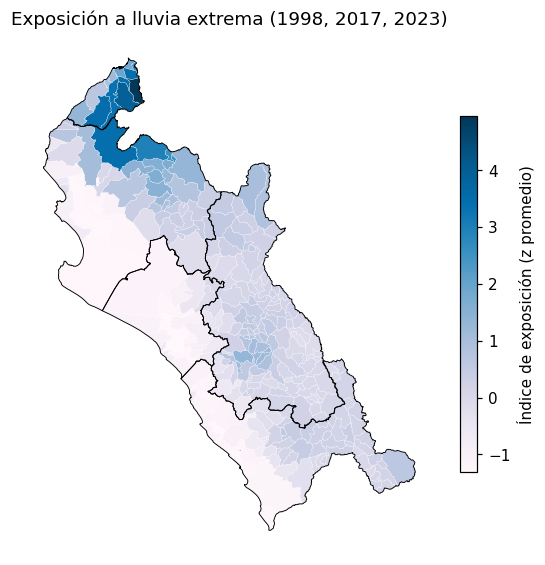

In [11]:
mapa = distritos.merge(lluvia[["ubigeo", "indice_exposicion"]], on="ubigeo")
fig, ax = plt.subplots(figsize=(6, 7))
mapa.plot("indice_exposicion", ax=ax, cmap="PuBu", legend=True, edgecolor="white", linewidth=0.15,
          legend_kwds={"shrink": 0.6, "label": "Índice de exposición (z promedio)"})
departamentos.boundary.plot(ax=ax, color="k", lw=0.6)
ax.set_axis_off(); ax.set_title("Exposición a lluvia extrema (1998, 2017, 2023)")
plt.savefig(FIG / "06_exposicion_distrital.png", bbox_inches="tight"); plt.show()

## Hallazgos

1. **Estructura espacial clara.** El log de la lluvia de marzo de 1998 tiene un semivariograma gaussiano con pepita
   pequeña (0,24) y rango práctico de 147 km, con anisotropía costa-sierra: a unos 100 km, la variación perpendicular a la costa es varias
   veces la paralela.
2. **El kriging supera a la interpolación determinista.** Promediando los tres eventos, el kriging ordinario reduce
   el RMSE frente a IDW de 114 a 87 mm en validación cruzada y de 124 a 86 mm sobre el campo completo; IDW además
   subestima en promedio entre 20 y 39 mm por suavizar los máximos.
3. **La altitud como deriva no mejora la predicción, pero sí la incertidumbre.** El kriging con deriva externa
   empata con el ordinario en error (85 frente a 86 mm sobre el campo) porque la relación lluvia-altitud es débil en
   eventos de El Niño (R² = 0,16), cuando llueve más en la costa que en la sierra. Su varianza está mejor calibrada:
   MSDR de 1,4 a 1,5 frente a 1,6 a 1,7 del ordinario (el valor ideal es 1).
4. **Ambos krigings son optimistas sobre su propio error.** Un MSDR mayor que 1 indica que la varianza de kriging
   subestima el error real; la desviación estándar de kriging ordena bien las zonas de riesgo (Spearman 0,35 con el
   error real), pero no debe leerse como un intervalo literal.
5. **El error depende de la distancia a la red.** El error absoluto medio es de unos 40 mm a menos de 10 km de una
   estación y sube a 82 mm a más de 40 km (409 píxeles, 11% del ámbito). La validación cruzada en estaciones
   (87 mm) coincide con la del campo completo (86 mm) solo en promedio: oculta que el error se concentra donde no
   hay estaciones.
6. **Exposición distrital.** `data/processed/lluvia_extrema_distrito.csv` resume los tres eventos por distrito. Los
   más expuestos están en Tumbes (Matapalo, Pampas de Hospital, Casitas, Papayal) y en la sierra de Piura
   (Lancones, Suyo, Jililí). Este índice es el componente de **riesgo climático** del score del notebook 09.

## Referencias

* Cressie, N. (1985). Fitting variogram models by weighted least squares. *Mathematical Geology, 17*(5), 563-586.
* Funk, C., et al. (2015). The climate hazards infrared precipitation with stations: A new environmental record for monitoring extremes. *Scientific Data, 2*, 150066.
* Goovaerts, P. (2000). Geostatistical approaches for incorporating elevation into the spatial interpolation of rainfall. *Journal of Hydrology, 228*(1-2), 113-129.
* Hengl, T., Heuvelink, G. B. M., & Rossiter, D. G. (2007). About regression-kriging: From equations to case studies. *Computers & Geosciences, 33*(10), 1301-1315.
* Matheron, G. (1963). Principles of geostatistics. *Economic Geology, 58*(8), 1246-1266.

# 07 Patrones Puntuales

Notebook original: `07_patrones_puntuales.ipynb`.

# 07 · Procesos puntuales: localización de bancos y cajeros

| | |
|---|---|
| **Pregunta** | ¿Las sucursales y cajeros se localizan de forma completamente aleatoria (CSR), se agrupan, o su patrón se explica solo por dónde vive la población? |
| **Datos** | 395 bancos, ATM y casas de cambio georreferenciados en OpenStreetMap (16/10/2026); límites INEI 2026; centros poblados INEI con tipo urbano o rural. |
| **Escalas** | (A) Trujillo metropolitano, la zona mejor mapeada; (B) toda la región, con un modelo de intensidad no homogénea. |
| **Métodos** | Prueba de cuadrantes, índice de Clark-Evans, funciones G, F, K y L con envolventes de simulación bajo CSR; estimación kernel de la intensidad; proceso de Poisson no homogéneo log-lineal (aproximación de Berman-Turner por píxeles); simulación por adelgazamiento (Lewis-Shedler); función K no homogénea (Baddeley, Møller y Waagepetersen, 2000). |
| **Salidas** | `outputs/figuras/07_*.png` · `data/processed/intensidad_ipp_grilla.csv`. |

**Limitación declarada:** OSM registra una fracción de lo que reporta la SBS (≈ 395 puntos frente a ≈ 4 900 ATM),
por eso la inferencia de la escala A se restringe a una ciudad con buena cobertura y la escala B se interpreta
como el patrón de la oferta visible, no del total.

In [1]:
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pointpats import QStatistic, f_test, g_test, l_test
from scipy.spatial import cKDTree
from scipy.stats import gaussian_kde
from shapely.geometry import box

warnings.filterwarnings("ignore")
rng = np.random.default_rng(2026)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
CRS = "EPSG:32717"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Datos y depuración

In [2]:
gpkg = DATA / "geobanca_norte.gpkg"
distritos = gpd.read_file(gpkg, layer="distritos").to_crs(CRS)
puntos = gpd.read_file(gpkg, layer="osm_bancos_atm").to_crs(CRS)
ccpp = gpd.read_file(gpkg, layer="centros_poblados").to_crs(CRS)

# Un banco y su ATM suelen estar mapeados como dos objetos en el mismo local: se fusionan los puntos a menos de 15 m
xy = np.column_stack([puntos.geometry.x, puntos.geometry.y])
pares = cKDTree(xy).query_pairs(r=15)
descartar = {j for i, j in pares}
sitios = puntos.drop(index=puntos.index[list(descartar)]).reset_index(drop=True)
print(f"Objetos OSM: {len(puntos)} | sitios únicos tras fusionar duplicados a < 15 m: {len(sitios)}")

cobertura = (sitios.merge(distritos[["ubigeo", "provincia"]], on="ubigeo").groupby("provincia").size().rename("sitios_osm")
             .to_frame().join(distritos.groupby("provincia")[["n_atm", "n_oficinas"]].sum()))
cobertura["osm / (ATM + oficinas SBS)"] = cobertura["sitios_osm"] / (cobertura["n_atm"] + cobertura["n_oficinas"])
cobertura.sort_values("sitios_osm", ascending=False).head(8).round(3)

Objetos OSM: 395 | sitios únicos tras fusionar duplicados a < 15 m: 349


,sitios_osm,n_atm,n_oficinas,osm / (ATM + oficinas SBS)
provincia,,,,
TRUJILLO,99,1031.0,58.0,0.091
PIURA,56,1124.0,71.0,0.047
CHICLAYO,41,836.0,69.0,0.045
CAJAMARCA,26,331.0,30.0,0.072
MORROPON,17,54.0,24.0,0.218
AYABACA,12,26.0,13.0,0.308
TALARA,11,227.0,22.0,0.044
LAMBAYEQUE,9,118.0,34.0,0.059


## Escala A · Trujillo metropolitano

Ventana de estudio: los seis distritos de la conurbación (Trujillo, Víctor Larco Herrera, La Esperanza,
El Porvenir, Florencia de Mora y Alto Trujillo). La elección de la ventana condiciona todas las pruebas: una
ventana que incluya cerros o desierto vacío exageraría el agrupamiento.

In [3]:
URBANOS = ["TRUJILLO", "VICTOR LARCO HERRERA", "LA ESPERANZA", "EL PORVENIR", "FLORENCIA DE MORA", "ALTO TRUJILLO"]
vent_gdf = distritos[(distritos["provincia"] == "TRUJILLO") & (distritos["distrito"].isin(URBANOS))]
ventana = vent_gdf.union_all().simplify(25)   # simplificación de 25 m: acelera las simulaciones sin cambiar el área
pts_tru = sitios[sitios.within(ventana)]
coords = np.column_stack([pts_tru.geometry.x, pts_tru.geometry.y])
area_km2 = ventana.area / 1e6
lam = len(coords) / area_km2
print(f"n = {len(coords)} sitios | área = {area_km2:.1f} km² | intensidad media = {lam:.2f} sitios/km²")

n = 92 sitios | área = 112.3 km² | intensidad media = 0.82 sitios/km²


### A1. Prueba de cuadrantes y vecino más cercano

- **Cuadrantes:** bajo CSR, los conteos por celda siguen una Poisson y el estadístico χ² = Σ(O−E)²/E compara
  la dispersión observada con la esperada.
- **Clark-Evans:** R = d̄_obs / d̄_CSR, con d̄_CSR = 1 / (2√λ). R < 1 indica agrupamiento; R > 1, regularidad.

In [4]:
qs = QStatistic(coords, shape="rectangle", nx=6, ny=6)
print(f"Cuadrantes 6x6: chi2 = {qs.chi2:.1f}, gl = {qs.df}, p = {qs.chi2_pvalue:.2e}")

d_nn = cKDTree(coords).query(coords, k=2)[0][:, 1]
d_esp = 0.5 / np.sqrt(len(coords) / ventana.area)
R = d_nn.mean() / d_esp
se = 0.26136 / np.sqrt(len(coords) ** 2 / ventana.area)
z = (d_nn.mean() - d_esp) / se
print(f"Clark-Evans: distancia media al vecino más cercano = {d_nn.mean():.0f} m (CSR: {d_esp:.0f} m) | R = {R:.3f}, z = {z:.2f}")

Cuadrantes 6x6: chi2 = 326.7, gl = 35, p = 4.88e-49
Clark-Evans: distancia media al vecino más cercano = 224 m (CSR: 552 m) | R = 0.406, z = -10.89


### A2. Funciones de distancia con envolventes de simulación

Se comparan las funciones empíricas con 199 realizaciones de CSR dentro de la misma ventana:

- **G(r):** distribución de la distancia de cada sitio a su vecino más cercano. Por encima de la envolvente → agrupamiento.
- **F(r):** distancia de puntos arbitrarios del espacio al sitio más cercano (espacio vacío). Por debajo → agrupamiento.
- **K(r) y L(r) = √(K/π):** número esperado de sitios a distancia r de un sitio típico, dividido por λ. Bajo CSR,
  L(r) = r; se grafica L(r) − r para leer directamente el exceso de vecinos.

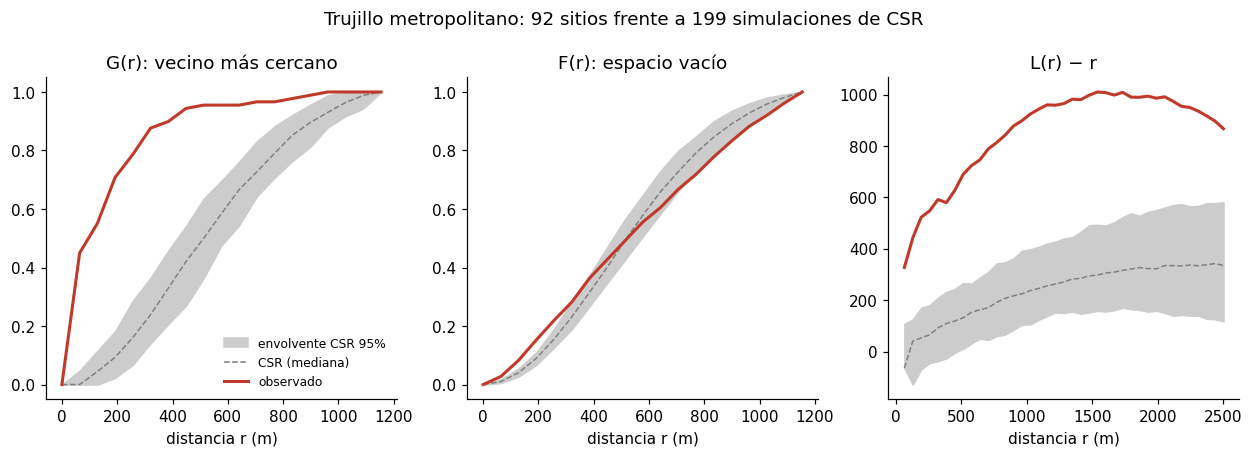

,p-valor mínimo en el rango
G,0.000
F,0.000
L,0.005


In [5]:
dist = np.linspace(0, 2500, 40)
NSIM = 199
res = {
    "G": g_test(coords, hull=ventana, support=dist[dist <= 1200], keep_simulations=True, n_simulations=NSIM),
    "F": f_test(coords, hull=ventana, support=dist[dist <= 1200], keep_simulations=True, n_simulations=NSIM),
    "L": l_test(coords, hull=ventana, support=dist[dist > 0], keep_simulations=True, n_simulations=NSIM),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (nombre, r) in zip(axes, res.items()):
    sims = np.asarray(r.simulations)
    obs = np.asarray(r.statistic)
    x = np.asarray(r.support)
    if nombre == "L":
        sims, obs = sims - x, obs - x
    lo, hi = np.nanpercentile(sims, 2.5, axis=0), np.nanpercentile(sims, 97.5, axis=0)
    ax.fill_between(x, lo, hi, color="#cccccc", label="envolvente CSR 95%")
    ax.plot(x, np.nanmedian(sims, axis=0), color="grey", linestyle="--", linewidth=1, label="CSR (mediana)")
    ax.plot(x, obs, color="#c0392b", linewidth=2, label="observado")
    ax.set_xlabel("distancia r (m)")
    ax.set_title({"G": "G(r): vecino más cercano", "F": "F(r): espacio vacío", "L": "L(r) − r"}[nombre])
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Trujillo metropolitano: {len(coords)} sitios frente a {NSIM} simulaciones de CSR", y=1.04)
fig.savefig(FIG / "07_funciones_distancia_trujillo.png", bbox_inches="tight")
plt.show()

pd.DataFrame({k: {"p-valor mínimo en el rango": float(np.nanmin(np.asarray(v.pvalue)))} for k, v in res.items()}).T

### A3. Intensidad kernel

Estimador gaussiano de la intensidad λ(s) con ancho de banda de Scott. Muestra dónde se concentra la oferta
dentro de la ciudad: la superficie es el insumo descriptivo del que parte el modelo de la escala B.

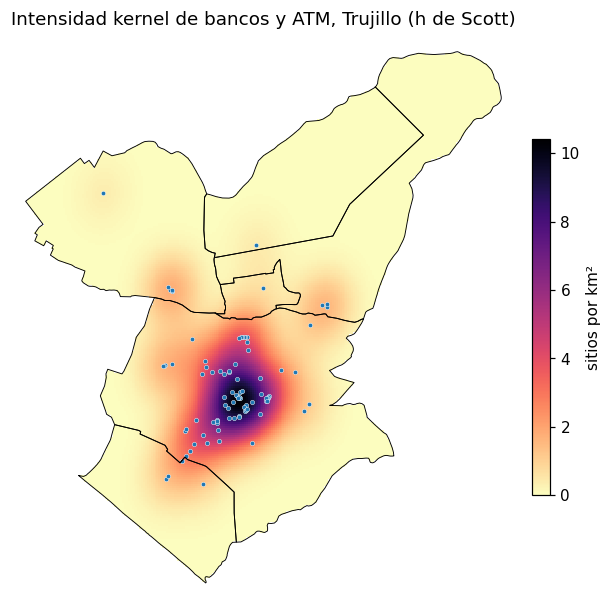

In [6]:
kde = gaussian_kde(coords.T, bw_method="scott")
xmin, ymin, xmax, ymax = ventana.bounds
gx, gy = np.meshgrid(np.linspace(xmin, xmax, 250), np.linspace(ymin, ymax, 250))
dens = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape) * len(coords) * 1e6   # sitios por km²
fuera = ~gpd.GeoSeries(gpd.points_from_xy(gx.ravel(), gy.ravel()), crs=CRS).within(ventana).to_numpy().reshape(gx.shape)
dens = np.ma.array(dens, mask=fuera)

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.pcolormesh(gx, gy, dens, cmap="magma_r", shading="auto")
vent_gdf.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.scatter(coords[:, 0], coords[:, 1], s=8, color="#1f77b4", edgecolor="white", linewidth=0.3)
fig.colorbar(im, ax=ax, shrink=0.6, label="sitios por km²")
ax.set_title(f"Intensidad kernel de bancos y ATM, Trujillo (h de Scott)")
ax.set_axis_off()
fig.savefig(FIG / "07_kernel_trujillo.png", bbox_inches="tight")
plt.show()

## Escala B · Región completa: proceso de Poisson no homogéneo

Que los sitios estén agrupados no significa que exista "contagio" entre ellos: pueden estar donde está la
demanda. Se modela la intensidad de primer orden como

$$\lambda(s) = \exp\{\beta_0 + \beta_1 \log \text{densidad}(s) + \beta_2\, \%\text{urbana}(s) + \beta_3\, d_{\text{urbano}}(s)\}$$

donde $d_{\text{urbano}}$ es la distancia (km) al centro poblado urbano más cercano. Se ajusta por la
aproximación de píxeles: con celdas de 3 km, los conteos $N_c \sim \text{Poisson}(\lambda_c |c|)$ y el
modelo es un GLM de Poisson con *offset* log(área).

In [7]:
region = distritos.union_all().simplify(200)
TAM = 3000  # m
xmin, ymin, xmax, ymax = region.bounds
xs, ys = np.meshgrid(np.arange(xmin, xmax, TAM), np.arange(ymin, ymax, TAM))
xs, ys = xs.ravel(), ys.ravel()
centros = gpd.GeoSeries(gpd.points_from_xy(xs + TAM / 2, ys + TAM / 2), crs=CRS)
dentro = centros.within(region).to_numpy()
celdas = gpd.GeoDataFrame(geometry=[box(x, y, x + TAM, y + TAM) for x, y in zip(xs[dentro], ys[dentro])], crs=CRS)
celdas["area_km2"] = TAM**2 / 1e6
cent = gpd.GeoDataFrame(geometry=centros[dentro].reset_index(drop=True), crs=CRS)

# Covariables por celda
cent = gpd.sjoin_nearest(cent, distritos[["ubigeo", "densidad_hab_km2", "pct_urbana", "geometry"]], how="left")
cent = cent[~cent.index.duplicated()]
urb = ccpp[ccpp["tipo"] == "Urban"]
d_urb, _ = cKDTree(np.column_stack([urb.geometry.x, urb.geometry.y])).query(np.column_stack([cent.geometry.x, cent.geometry.y]))
celdas["log_densidad"] = np.log(cent["densidad_hab_km2"].to_numpy())
celdas["pct_urbana"] = cent["pct_urbana"].to_numpy()
celdas["dist_urbano_km"] = d_urb / 1000

# Conteos
idx = gpd.sjoin(sitios[["geometry"]], celdas[["geometry"]], how="inner", predicate="within")["index_right"]
celdas["n"] = idx.value_counts().reindex(celdas.index, fill_value=0).to_numpy()
celdas = celdas.dropna(subset=["log_densidad", "pct_urbana"]).reset_index(drop=True)
print(f"Celdas: {len(celdas)} | sitios asignados: {celdas['n'].sum()} | celdas con al menos un sitio: {(celdas['n'] > 0).sum()}")

Celdas: 12532 | sitios asignados: 337 | celdas con al menos un sitio: 85


In [8]:
X = sm.add_constant(celdas[["log_densidad", "pct_urbana", "dist_urbano_km"]])
ipp = sm.GLM(celdas["n"], X, family=sm.families.Poisson(), offset=np.log(celdas["area_km2"])).fit()
csr = sm.GLM(celdas["n"], np.ones((len(celdas), 1)), family=sm.families.Poisson(), offset=np.log(celdas["area_km2"])).fit()
print(ipp.summary2().tables[1].round(4))
tabla = pd.DataFrame({"coef": ipp.params, "IRR = exp(coef)": np.exp(ipp.params),
                      "IC95% inf": np.exp(ipp.conf_int()[0]), "IC95% sup": np.exp(ipp.conf_int()[1])}).round(3)
lr = 2 * (ipp.llf - csr.llf)
print(f"Dispersión de Pearson (χ²/gl) = {ipp.pearson_chi2 / ipp.df_resid:.2f}  (< 1: no hay sobredispersión que obligue a un modelo binomial negativo)")
print(f"\nRazón de verosimilitudes Poisson no homogéneo vs homogéneo: {lr:.1f} (gl = 3) | AIC {csr.aic:.0f} -> {ipp.aic:.0f}")
tabla

                 Coef.  Std.Err.         z  P>|z|  [0.025  0.975]
const          -7.2407    0.2178  -33.2466  0.000 -7.6676 -6.8139
log_densidad    0.8871    0.0348   25.4954  0.000  0.8189  0.9553
pct_urbana      0.0071    0.0027    2.6527  0.008  0.0019  0.0123
dist_urbano_km -1.0255    0.0047 -219.1169  0.000 -1.0347 -1.0163
Dispersión de Pearson (χ²/gl) = 0.49  (< 1: no hay sobredispersión que obligue a un modelo binomial negativo)

Razón de verosimilitudes Poisson no homogéneo vs homogéneo: 2437.3 (gl = 3) | AIC 4121 -> 1690


,coef,IRR = exp(coef),IC95% inf,IC95% sup
const,-7.241,0.001,0.000,0.001
log_densidad,0.887,2.428,2.268,2.599
pct_urbana,0.007,1.007,1.002,1.012
dist_urbano_km,-1.025,0.359,0.355,0.362


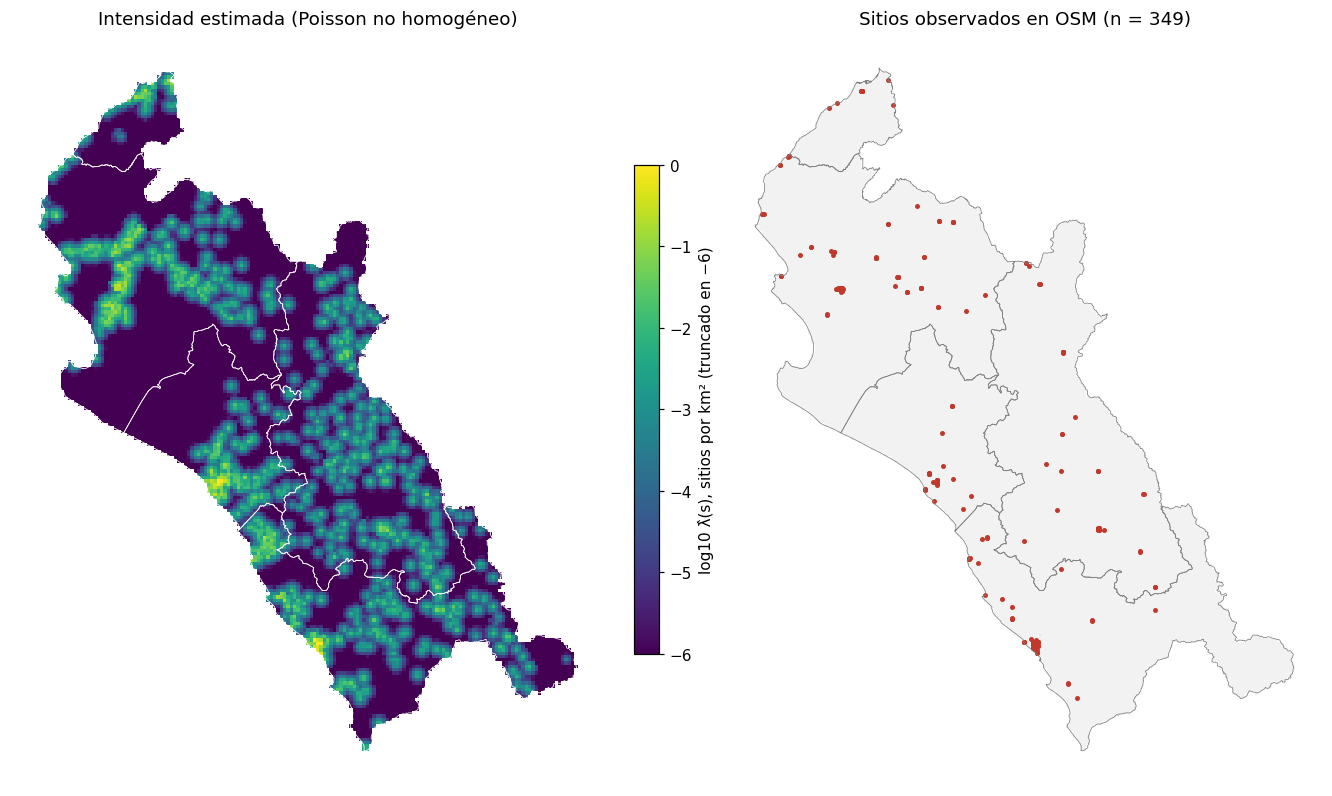

In [9]:
celdas["lambda_hat"] = ipp.predict(X, offset=np.zeros(len(celdas)))   # intensidad por km²
celdas[["log_densidad", "pct_urbana", "dist_urbano_km", "n", "lambda_hat", "area_km2"]].to_csv(DATA / "intensidad_ipp_grilla.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 7.5), constrained_layout=True)
celdas.plot(column=np.log10(celdas["lambda_hat"]).clip(lower=-6), cmap="viridis", ax=axes[0], linewidth=0, vmin=-6, vmax=0,
            legend=True, legend_kwds={"label": "log10 λ̂(s), sitios por km² (truncado en −6)", "shrink": 0.6})
distritos.dissolve("departamento").boundary.plot(ax=axes[0], color="white", linewidth=0.5)
axes[0].set_title("Intensidad estimada (Poisson no homogéneo)")
celdas.plot(ax=axes[1], color="#f2f2f2", linewidth=0)
distritos.dissolve("departamento").boundary.plot(ax=axes[1], color="grey", linewidth=0.5)
sitios.plot(ax=axes[1], markersize=5, color="#c0392b")
axes[1].set_title(f"Sitios observados en OSM (n = {len(sitios)})")
for ax in axes: ax.set_axis_off()
fig.savefig(FIG / "07_intensidad_ipp.png", bbox_inches="tight")
plt.show()

### B1. Simulación del proceso ajustado (adelgazamiento de Lewis-Shedler)

1. Se simula un Poisson homogéneo con intensidad λ_max sobre cada celda.
2. Cada punto se conserva con probabilidad λ(s)/λ_max.

El resultado es una realización del proceso no homogéneo ajustado. Se compara con una realización de CSR con
el mismo número esperado de puntos.

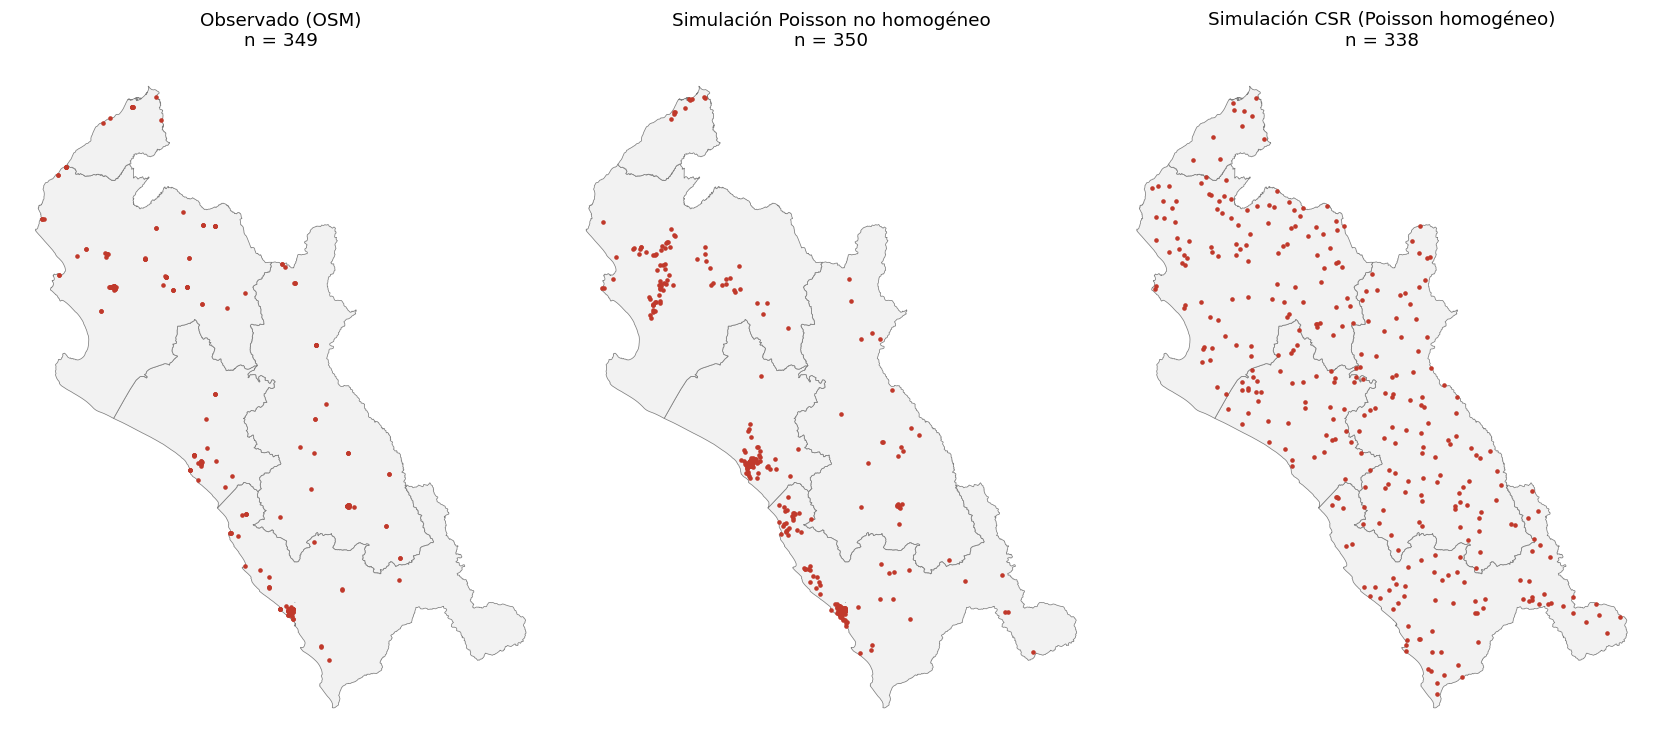

In [10]:
# Simulación por celdas: λ es constante dentro de cada celda de 3 km (aproximación de píxeles). Generar
# N_c ~ Poisson(λ_c |c|) puntos uniformes en cada celda equivale a adelgazar un Poisson homogéneo de
# intensidad λ_max con probabilidad de retención λ_c / λ_max (Lewis y Shedler, 1979).
def simular_ipp_rapido(celdas, rng, lam_col="lambda_hat", devolver_celda=False):
    n = rng.poisson(celdas[lam_col].to_numpy() * celdas["area_km2"].to_numpy())
    b = celdas.geometry.bounds.to_numpy()
    rep = np.repeat(np.arange(len(celdas)), n)
    xy_ = np.column_stack([rng.uniform(b[rep, 0], b[rep, 2]), rng.uniform(b[rep, 1], b[rep, 3])])
    return (xy_, rep) if devolver_celda else xy_

sim_ipp = simular_ipp_rapido(celdas, rng)
celdas["lambda_csr"] = len(sitios) / celdas["area_km2"].sum()
sim_csr = simular_ipp_rapido(celdas, rng, "lambda_csr")

fig, axes = plt.subplots(1, 3, figsize=(15, 7), constrained_layout=True)
for ax, (titulo, xy_) in zip(axes, [("Observado (OSM)", np.column_stack([sitios.geometry.x, sitios.geometry.y])),
                                    ("Simulación Poisson no homogéneo", sim_ipp),
                                    ("Simulación CSR (Poisson homogéneo)", sim_csr)]):
    distritos.dissolve("departamento").plot(ax=ax, color="#f2f2f2", edgecolor="grey", linewidth=0.5)
    ax.scatter(xy_[:, 0], xy_[:, 1], s=4, color="#c0392b")
    ax.set_title(f"{titulo}\nn = {len(xy_)}")
    ax.set_axis_off()
fig.savefig(FIG / "07_simulaciones_ipp_csr.png", bbox_inches="tight")
plt.show()

### B2. ¿Queda agrupamiento después de controlar la intensidad? Función K no homogénea

$$\hat K_{\text{inhom}}(r) = \frac{1}{|A|} \sum_{i}\sum_{j \ne i} \frac{\mathbf 1(d_{ij} \le r)}{\hat\lambda(s_i)\,\hat\lambda(s_j)}$$

Si el patrón observado queda dentro de la envolvente de 199 simulaciones del proceso ajustado, la intensidad de
primer orden (densidad, urbanización y distancia a centros urbanos) basta para explicar la localización. Si la
supera, hay agrupamiento adicional de segundo orden (competencia o arrastre entre entidades).

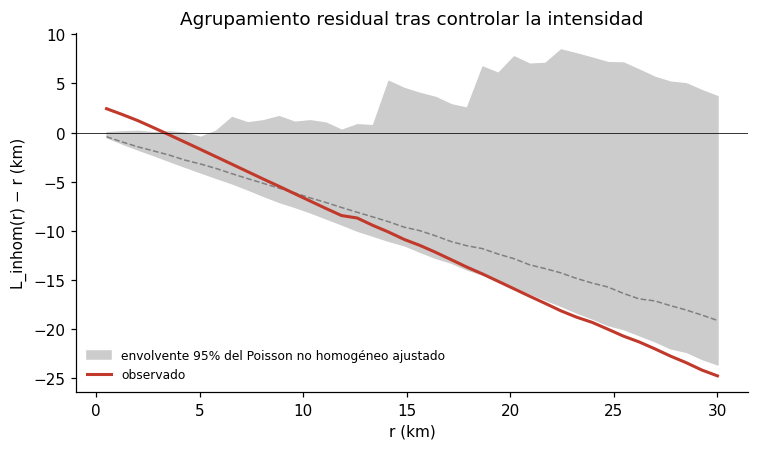

Radios con L observado por debajo de la envolvente: 15 de 40 (desde 19.4 km)
Radios con L observado por encima de la envolvente: 0.5 a 2.7692307692307696 km (4 de 40)


In [11]:
def lambda_en(xy_, celdas):
    g_ = gpd.GeoDataFrame(geometry=gpd.points_from_xy(*xy_.T), crs=CRS)
    j = gpd.sjoin(g_, celdas[["geometry", "lambda_hat"]], how="left", predicate="within")
    j = j[~j.index.duplicated()]
    return j["lambda_hat"].to_numpy() / 1e6   # por m²

def k_inhom(xy_, lam_, area, r):
    ok = ~np.isnan(lam_)
    xy_, lam_ = xy_[ok], lam_[ok]
    tree = cKDTree(xy_)
    pares = tree.query_pairs(r.max(), output_type="ndarray")
    d = np.linalg.norm(xy_[pares[:, 0]] - xy_[pares[:, 1]], axis=1)
    peso = 2.0 / (lam_[pares[:, 0]] * lam_[pares[:, 1]])
    return np.array([peso[d <= ri].sum() for ri in r]) / area

r = np.linspace(500, 30000, 40)
area_reg = celdas["area_km2"].sum() * 1e6
xy_obs = np.column_stack([sitios.geometry.x, sitios.geometry.y])
L_obs = np.sqrt(k_inhom(xy_obs, lambda_en(xy_obs, celdas), area_reg, r) / np.pi) - r

L_sim = []
for _ in range(199):
    s_xy, s_celda = simular_ipp_rapido(celdas, rng, devolver_celda=True)
    lam_s = celdas["lambda_hat"].to_numpy()[s_celda] / 1e6
    L_sim.append(np.sqrt(k_inhom(s_xy, lam_s, area_reg, r) / np.pi) - r)
L_sim = np.array(L_sim)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.fill_between(r / 1000, np.percentile(L_sim, 2.5, 0) / 1000, np.percentile(L_sim, 97.5, 0) / 1000,
                color="#cccccc", label="envolvente 95% del Poisson no homogéneo ajustado")
ax.plot(r / 1000, np.median(L_sim, 0) / 1000, "--", color="grey", linewidth=1)
ax.plot(r / 1000, L_obs / 1000, color="#c0392b", linewidth=2, label="observado")
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlabel("r (km)"); ax.set_ylabel("L_inhom(r) − r (km)")
ax.set_title("Agrupamiento residual tras controlar la intensidad")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "07_k_inhomogenea.png", bbox_inches="tight")
plt.show()

fuera_inf = (L_obs < np.percentile(L_sim, 2.5, 0))
print(f"Radios con L observado por debajo de la envolvente: {fuera_inf.sum()} de {len(r)}"
      + (f" (desde {r[fuera_inf].min()/1000:.1f} km)" if fuera_inf.any() else ""))
fuera_sup = (L_obs > np.percentile(L_sim, 97.5, 0))
print(f"Radios con L observado por encima de la envolvente: {r[fuera_sup].min()/1000 if fuera_sup.any() else '-'}"
      f" a {r[fuera_sup].max()/1000 if fuera_sup.any() else '-'} km ({fuera_sup.sum()} de {len(r)})")

## Hallazgos

**Escala A · Trujillo metropolitano (92 sitios en 112 km²)**

1. **El patrón está fuertemente agrupado.** La prueba de cuadrantes rechaza CSR (χ² = 327 con 35 gl,
   p < 10⁻⁴⁸). El índice de Clark-Evans es R = 0,41 (z = −10,9): la distancia media al vecino más cercano es
   224 m, frente a 552 m esperados bajo CSR.
2. **El agrupamiento ocurre a todas las escalas analizadas.** G(r) queda por encima de la envolvente desde los
   primeros metros (45% de los sitios tiene otro a menos de 70 m) y L(r) − r supera la envolvente en todo el
   rango hasta 2,5 km, con un exceso máximo de ≈ 1 km cerca de 1,5 km. F(r) sigue cerca de CSR: la ciudad
   tiene grandes zonas sin oferta, pero el núcleo concentra casi todo.
3. **La intensidad kernel identifica un núcleo único**, el centro histórico de Trujillo (> 10 sitios por km²), y
   focos secundarios en La Esperanza, El Porvenir y Víctor Larco. Alto Trujillo y Florencia de Mora casi no tienen
   oferta visible.

**Escala B · Región completa (349 sitios, 12 532 celdas de 3 km)**

4. **La intensidad depende de la demanda.** En el Poisson no homogéneo, duplicar la densidad poblacional
   multiplica la intensidad por 2^0,887 ≈ 1,85; cada punto porcentual de población urbana la aumenta en 0,7%; y
   cada kilómetro de distancia al centro poblado urbano más cercano la reduce en 64% (IRR = 0,36). El modelo
   mejora de forma contundente al homogéneo (razón de verosimilitudes = 2 437 con 3 gl; AIC de 4 121 a 1 690).
5. **Queda agrupamiento de corto alcance que la demanda no explica.** La K no homogénea supera la envolvente
   entre 0,5 y 2,8 km: las entidades se instalan unas junto a otras más de lo que justifica la población
   (economías de aglomeración y competencia por el mismo mercado). A distancias largas el patrón observado queda
   por debajo de la envolvente: el término de distancia lineal concentra la intensidad más de lo observado.
6. **Implicancia de negocio:** la oferta se apila en los mismos centros urbanos. Un nuevo agente o EOB aporta más
   cobertura en los centros poblados alejados de la red actual, que es lo que optimiza el notebook 09.

# 08 Espaciotemporal Ml

Notebook original: `08_espaciotemporal_ml.ipynb`.

# 08 · Dinámica espacio-temporal y aprendizaje automático espacial

| | |
|---|---|
| **Pregunta** | ¿Cómo se expandió la red de canales entre 2017 y 2025, se difunde por contigüidad, es predecible su cambio anual, y qué distritos tienen menos acceso del que corresponde a su estructura? |
| **Datos** | Panel SBS de cajeros automáticos, establecimientos con cajeros corresponsales y EOB por distrito (todas las entidades), cierres de diciembre 2017 a 2025: 327 distritos × 9 años. |
| **Métodos** | I de Moran por año; cadenas de Markov clásicas y espaciales (Rey, 2001) con prueba de homogeneidad; predicción del cambio anual con validación de origen móvil frente a persistencia; modelo de acceso potencial (Ridge, Random Forest, XGBoost) con rezagos espaciales de covariables y validación cruzada espacial por bloques provinciales; interpretación con valores SHAP. |
| **Salidas** | `outputs/figuras/08_*.png` · `outputs/tablas/08_*.csv` · `data/processed/brecha_acceso_2025.csv`. |

**Supuesto:** la población adulta de 2025 se usa como denominador en todos los años (no hay serie distrital
anual oficial). Las tasas reflejan sobre todo el cambio en la oferta, no en la población.

In [1]:
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from esda import Moran
from giddy.markov import Markov, Spatial_Markov
from libpysal import weights
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 2026
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
TAB = ROOT / "outputs" / "tablas"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORES_DEP = {"TUMBES": "#1b9e77", "PIURA": "#d95f02", "LAMBAYEQUE": "#7570b3",
               "LA LIBERTAD": "#e7298a", "CAJAMARCA": "#66a61e"}

/sessions/rcw-01lunysqylmxk5xagddf3uwd/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Construcción del panel

In [2]:
g = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs("EPSG:32717").reset_index(drop=True)
lisa = pd.read_csv(DATA / "lisa_acceso.csv", dtype={"ubigeo": str})[["ubigeo", "pobreza_imp"]]
g = g.merge(lisa, on="ubigeo", how="left")
g["altitud_km"] = g["altitud_capital_m"].fillna(g["altitud_capital_m"].mean()) / 1000
g["log_densidad"] = np.log(g["densidad_hab_km2"])

w = weights.Queen.from_dataframe(g, use_index=False)
w.transform = "r"

raw = pd.read_csv(DATA / "sbs_puntos_atencion_panel_distrito.csv", dtype={"ubigeo": str})
raw = raw[raw["corte"].str.startswith("di")].copy()
raw["anio"] = raw["corte"].str[2:].astype(int)
raw["canales"] = raw["atm"] + raw["corresponsal_establecimientos"] + raw["eob"]

ANIOS = sorted(raw["anio"].unique())
idx = pd.MultiIndex.from_product([g["ubigeo"], ANIOS], names=["ubigeo", "anio"])
panel = (raw.set_index(["ubigeo", "anio"])[["canales", "atm", "corresponsal_establecimientos"]]
            .reindex(idx, fill_value=0).reset_index())
panel = panel.merge(g[["ubigeo", "departamento", "provincia", "pob_18mas"]], on="ubigeo")
panel["tasa"] = 1e4 * panel["canales"] / panel["pob_18mas"]
panel["y"] = np.log1p(panel["tasa"])                  # escala de modelado
print(f"Panel: {panel['ubigeo'].nunique()} distritos × {len(ANIOS)} años = {len(panel)} filas")

# Matriz distrito × año en el orden de g (necesaria para Moran y Markov)
Y = panel.pivot(index="ubigeo", columns="anio", values="y").loc[g["ubigeo"]]
TASA = panel.pivot(index="ubigeo", columns="anio", values="tasa").loc[g["ubigeo"]]

Panel: 327 distritos × 9 años = 2943 filas


## 2. Evolución de la red y de su dependencia espacial

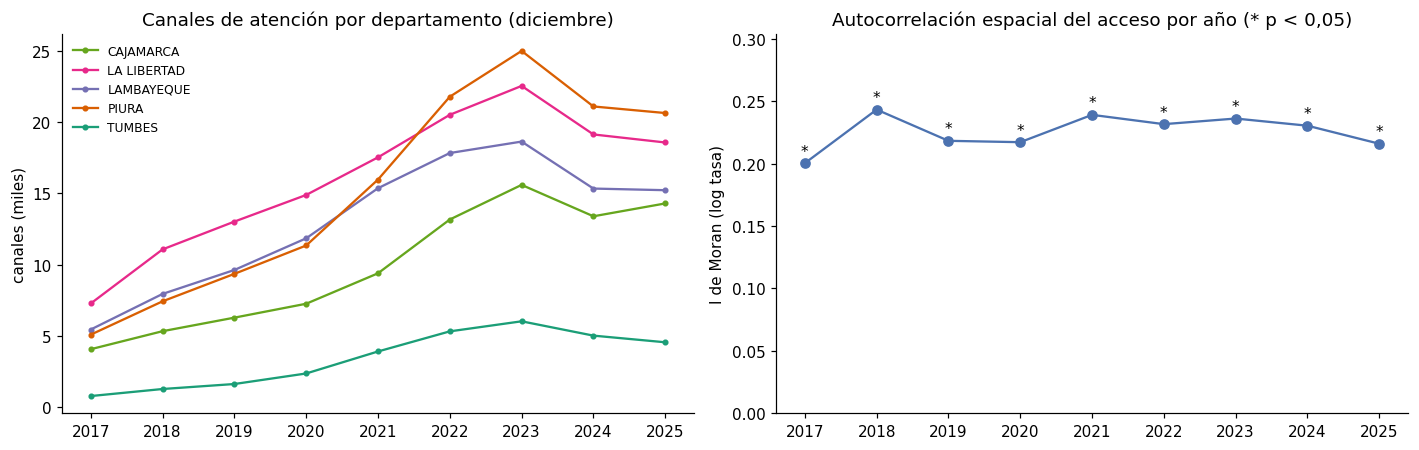

anio,2017,2018,2019,2020,2021,2022,2023,2024,2025
I,0.200,0.243,0.218,0.217,0.239,0.232,0.236,0.230,0.216
p,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001


In [3]:
tot = panel.groupby(["anio", "departamento"])["canales"].sum().unstack()
moran_t = pd.DataFrame([{"anio": a, "I": (m := Moran(Y[a], w, permutations=999)).I, "p": m.p_sim} for a in ANIOS]).set_index("anio")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for dep in tot.columns:
    axes[0].plot(tot.index, tot[dep] / 1000, marker="o", markersize=3, color=COLORES_DEP[dep], label=dep)
axes[0].set_ylabel("canales (miles)"); axes[0].set_title("Canales de atención por departamento (diciembre)")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(moran_t.index, moran_t["I"], marker="o", color="#4c72b0")
for a, r in moran_t.iterrows():
    axes[1].annotate("*" if r.p < 0.05 else "", (a, r.I), textcoords="offset points", xytext=(0, 5), ha="center")
axes[1].set_ylim(0, moran_t["I"].max() * 1.25); axes[1].set_ylabel("I de Moran (log tasa)")
axes[1].set_title("Autocorrelación espacial del acceso por año (* p < 0,05)")
fig.tight_layout()
fig.savefig(FIG / "08_evolucion_moran.png", bbox_inches="tight")
plt.show()
moran_t.round(3).T

## 3. Cadenas de Markov espaciales

Cada distrito se clasifica cada año en quintiles de acceso. La **cadena de Markov clásica** estima la probabilidad
de pasar de un quintil a otro entre años consecutivos. La **cadena de Markov espacial** (Rey, 2001) estima esas
transiciones condicionadas al quintil del rezago espacial (el promedio de los vecinos). Si las matrices
condicionales difieren, el entorno influye en la trayectoria: hay **difusión espacial**.

In [4]:
import mapclassify as mc
q = np.column_stack([mc.Quantiles(Y[a], k=5).yb for a in ANIOS])   # quintiles de cada año
mk = Markov(q)
etq = ["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"]
print("Markov clásica: probabilidades de transición anual")
print(pd.DataFrame(mk.p, index=etq, columns=etq).round(3).to_string())

sm_ = Spatial_Markov(np.asarray(Y), w, fixed=False, k=5, m=5)
print(f"\nPrueba de homogeneidad espacial (Bickenbach y Bode): Q = {sm_.Q:.1f}, gl = {sm_.dof_hom}, p = {sm_.Q_p_value:.4f}")
print(f"Razón de verosimilitudes: LR = {sm_.LR:.1f}, p = {sm_.LR_p_value:.4f}")

The Markov Chain is irreducible and is composed by:
1 Recurrent class (indices):
[0 1 2 3 4]
0 Transient classes.
The Markov Chain has 0 absorbing states.
Markov clásica: probabilidades de transición anual
           Q1 (bajo)     Q2     Q3     Q4  Q5 (alto)
Q1 (bajo)      0.788  0.152  0.045  0.011      0.004
Q2             0.200  0.629  0.125  0.035      0.012
Q3             0.010  0.192  0.600  0.175      0.023
Q4             0.002  0.021  0.217  0.613      0.146
Q5 (alto)      0.004  0.004  0.011  0.163      0.818

Prueba de homogeneidad espacial (Bickenbach y Bode): Q = 146.3, gl = 80, p = 0.0000
Razón de verosimilitudes: LR = 124.3, p = 0.0011


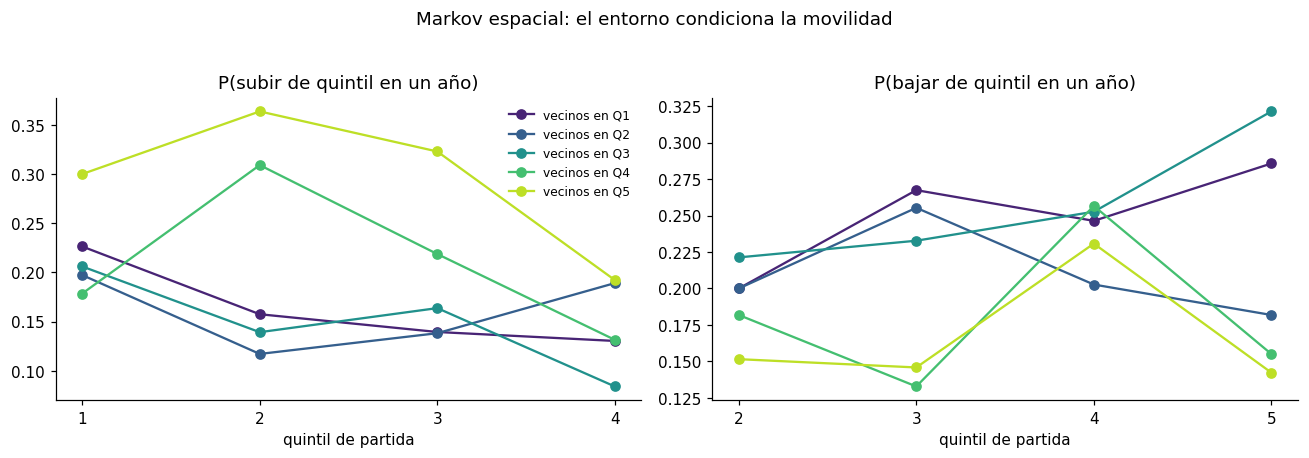

In [5]:
# Probabilidad de subir de quintil según el entorno
def prob_subir(P):
    return np.array([P[i, i + 1:].sum() for i in range(4)])
def prob_bajar(P):
    return np.array([P[i, :i].sum() for i in range(1, 5)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cols = plt.cm.viridis(np.linspace(0.1, 0.9, 5))
for k in range(5):
    axes[0].plot(range(1, 5), prob_subir(sm_.P[k]), marker="o", color=cols[k], label=f"vecinos en Q{k+1}")
    axes[1].plot(range(2, 6), prob_bajar(sm_.P[k]), marker="o", color=cols[k], label=f"vecinos en Q{k+1}")
axes[0].set_xticks(range(1, 5)); axes[0].set_xlabel("quintil de partida"); axes[0].set_title("P(subir de quintil en un año)")
axes[1].set_xticks(range(2, 6)); axes[1].set_xlabel("quintil de partida"); axes[1].set_title("P(bajar de quintil en un año)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Markov espacial: el entorno condiciona la movilidad", y=1.03)
fig.tight_layout()
fig.savefig(FIG / "08_markov_espacial.png", bbox_inches="tight")
plt.show()

## 4. ¿Se puede anticipar el cambio anual de cada distrito?

**Diseño de origen móvil.** Para cada año de prueba t ∈ {2021, …, 2024} se entrena con todas las transiciones
anteriores y se predice el cambio de la log tasa entre t y t+1. Las variables son la log tasa en t, el cambio
t−1 → t, la participación de ATM, los rezagos espaciales (nivel y cambio de los vecinos) y las covariables
estructurales. El punto de comparación es la **persistencia** (cambio = 0), un estándar exigente en paneles cortos.

Además del RMSE se reporta la correlación de rangos de Spearman entre el cambio predicho y el observado: mide si
el modelo **ordena** bien qué distritos crecerán más, que es lo que importaría para priorizar.

In [6]:
WY = pd.DataFrame(weights.lag_spatial(w, Y.to_numpy()), index=Y.index, columns=Y.columns)
filas = []
for i, a in enumerate(ANIOS[1:-1], start=1):
    a_prev, a_next = ANIOS[i - 1], ANIOS[i + 1]
    filas.append(pd.DataFrame({
        "ubigeo": Y.index, "anio": a,
        "y_t": Y[a].to_numpy(), "dy_t": (Y[a] - Y[a_prev]).to_numpy(),
        "wy_t": WY[a].to_numpy(), "wdy_t": (WY[a] - WY[a_prev]).to_numpy(),
        "y_next": Y[a_next].to_numpy()}))
ds = pd.concat(filas, ignore_index=True)
ds = ds.merge(panel[["ubigeo", "anio", "atm", "canales"]], on=["ubigeo", "anio"], how="left")
ds["share_atm"] = np.where(ds["canales"] > 0, ds["atm"] / ds["canales"], 0)
ds = ds.merge(g[["ubigeo", "provincia", "pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]], on="ubigeo")
ds["delta"] = ds["y_next"] - ds["y_t"]

print("Cambio medio de la log tasa por año (choque común a todos los distritos):")
print(ds.groupby("anio")["delta"].mean().rename(lambda a: f"{a}→{a+1}").round(3).to_string())

Cambio medio de la log tasa por año (choque común a todos los distritos):
anio
2018→2019    0.231
2019→2020    0.002
2020→2021    0.539
2021→2022    0.323
2022→2023    0.191
2023→2024   -0.070
2024→2025    0.053


In [7]:
from scipy.stats import spearmanr
F_DIN = ["y_t", "dy_t", "share_atm", "wy_t", "wdy_t", "pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]

def modelos(semilla=SEED):
    return {
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25))),
        "Random Forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=10, n_jobs=-1, random_state=semilla),
        "XGBoost": xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                    min_child_weight=10, random_state=semilla),
    }

res = []
for ta in ANIOS[4:-1]:
    tr, te = ds[ds["anio"] < ta], ds[ds["anio"] == ta]
    fila = {"prueba": f"{ta}→{ta + 1}", "Persistencia RMSE": mean_squared_error(te["y_next"], te["y_t"]) ** 0.5}
    for nombre, m in modelos().items():
        m.fit(tr[F_DIN], tr["delta"])
        d_hat = m.predict(te[F_DIN])
        fila[f"{nombre} RMSE"] = mean_squared_error(te["y_next"], te["y_t"] + d_hat) ** 0.5
        fila[f"{nombre} ρ Spearman"] = spearmanr(d_hat, te["delta"])[0]
    res.append(fila)
origen_movil = pd.DataFrame(res).set_index("prueba")
origen_movil.loc["Promedio"] = origen_movil.mean()
origen_movil.round(3).to_csv(TAB / "08_prediccion_cambio_anual.csv")
origen_movil.round(3)

,Persistencia RMSE,Ridge RMSE,Ridge ρ Spearman,Random Forest RMSE,Random Forest ρ Spearman,XGBoost RMSE,XGBoost ρ Spearman
prueba,,,,,,,
2021→2022,0.586,0.670,-0.071,0.651,-0.003,0.683,-0.042
2022→2023,0.647,0.601,-0.134,0.579,0.123,0.590,0.019
2023→2024,0.521,0.554,0.117,0.529,0.129,0.535,-0.005
2024→2025,0.482,0.463,-0.013,0.480,0.084,0.468,0.098
Promedio,0.559,0.572,-0.025,0.560,0.083,0.569,0.017


**Lectura.** El error de todos los modelos es del mismo orden que el de la persistencia y la correlación de rangos
del cambio es cercana a cero: la variación anual de cada distrito está dominada por choques comunes (expansión de
2020-2021, retroceso de 2023) y por ruido idiosincrático, no por su estructura ni por su entorno. La conclusión
operativa es que **no conviene priorizar distritos según su crecimiento esperado**, sino según la brecha entre su
nivel de acceso y el que corresponde a su estructura, que es lo que modela la sección siguiente.

## 5. Acceso potencial y brecha: modelo transversal con validación cruzada espacial

Se estima el acceso **esperado** de cada distrito en 2025 a partir de su estructura (pobreza, urbanización,
altitud, densidad), del promedio de esas variables en sus vecinos (WX) y de su posición (coordenadas UTM).
Las predicciones son **fuera de pliegue** con 5 pliegues agrupados por provincia: el acceso esperado de un
distrito se calcula con un modelo que nunca vio su provincia, lo que evita que la autocorrelación espacial
infle el ajuste (Roberts et al., 2017).

**Brecha = log tasa observada − log tasa esperada.** Una brecha negativa identifica distritos **desatendidos
respecto de distritos comparables**: oportunidad comercial que no depende de la pobreza en sí.

In [8]:
corte = g[["ubigeo", "distrito", "provincia", "departamento", "pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]].copy()
corte["y"] = Y[ANIOS[-1]].to_numpy()
cent = g.geometry.centroid
corte["x_km"], corte["y_km"] = cent.x.to_numpy() / 1000, cent.y.to_numpy() / 1000
F_EST = ["pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]
for c in F_EST:
    corte[f"W_{c}"] = weights.lag_spatial(w, corte[c].to_numpy())
conj = {"estructurales (X)": F_EST,
        "X + rezagos espaciales (WX)": F_EST + [f"W_{c}" for c in F_EST],
        "X + WX + coordenadas": F_EST + [f"W_{c}" for c in F_EST] + ["x_km", "y_km"]}

gkf = GroupKFold(n_splits=5)
oof, filas = {}, []
for nc, cols in conj.items():
    for nm, _ in modelos().items():
        p = np.zeros(len(corte))
        for tr, va in gkf.split(corte, groups=corte["provincia"]):
            m = modelos()[nm].fit(corte.iloc[tr][cols], corte.iloc[tr]["y"])
            p[va] = m.predict(corte.iloc[va][cols])
        oof[(nm, nc)] = p
        resid = corte["y"].to_numpy() - p
        filas.append({"modelo": nm, "variables": nc,
                      **{"RMSE": mean_squared_error(corte["y"], p) ** 0.5, "MAE": mean_absolute_error(corte["y"], p),
                       "R² (CV espacial)": r2_score(corte["y"], p)},
                      "I de Moran residuos": Moran(resid, w, permutations=999).I})
cv_tab = pd.DataFrame(filas).set_index(["modelo", "variables"])
cv_tab.round(3).to_csv(TAB / "08_acceso_potencial_cv_espacial.csv")
cv_tab.round(3)

,,RMSE,MAE,R² (CV espacial),I de Moran residuos
modelo,variables,,,,
Ridge,estructurales (X),0.964,0.726,0.239,0.124
Random Forest,estructurales (X),0.944,0.704,0.271,0.099
XGBoost,estructurales (X),0.989,0.736,0.200,0.092
Ridge,X + rezagos espaciales (WX),0.932,0.694,0.290,0.131
Random Forest,X + rezagos espaciales (WX),0.926,0.681,0.298,0.092
XGBoost,X + rezagos espaciales (WX),0.989,0.739,0.199,0.107
Ridge,X + WX + coordenadas,0.920,0.690,0.307,0.094
Random Forest,X + WX + coordenadas,0.903,0.659,0.332,0.052
XGBoost,X + WX + coordenadas,0.976,0.725,0.220,0.071


Mejor especificación (CV espacial): ('Random Forest', 'X + WX + coordenadas')


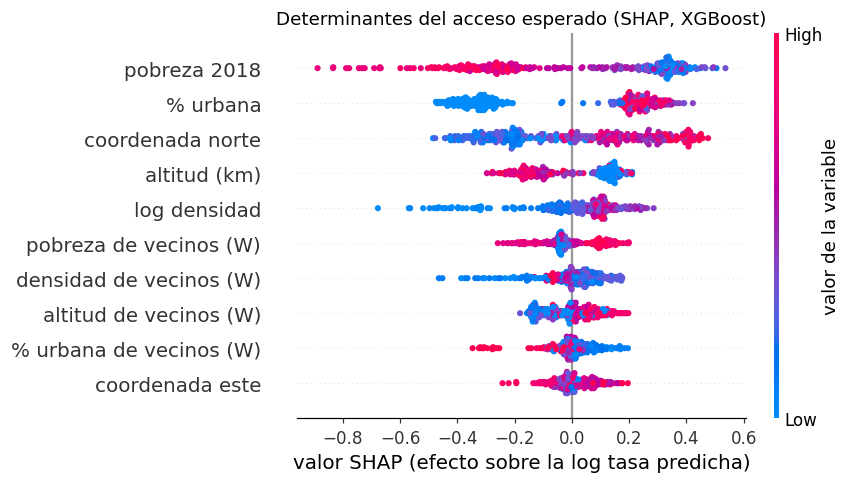

pobreza 2018               0.221
% urbana                   0.204
coordenada norte           0.161
altitud (km)               0.098
log densidad               0.085
pobreza de vecinos (W)     0.054
densidad de vecinos (W)    0.054
altitud de vecinos (W)     0.050
% urbana de vecinos (W)    0.038
coordenada este            0.035
Name: peso relativo |SHAP|, dtype: float32

In [9]:
mejor = cv_tab["RMSE"].idxmin()
print("Mejor especificación (CV espacial):", mejor)
cols = conj[mejor[1]]
corte["y_esperado"] = oof[mejor]
corte["brecha"] = corte["y"] - corte["y_esperado"]
corte["tasa_obs"] = np.expm1(corte["y"])
corte["tasa_esperada"] = np.expm1(corte["y_esperado"])

# Interpretación: modelo ajustado con todos los datos (XGBoost) y SHAP exacto de árboles
xgb_full = modelos()["XGBoost"].fit(corte[cols], corte["y"])
contrib = xgb_full.get_booster().predict(xgb.DMatrix(corte[cols]), pred_contribs=True)
sv = contrib[:, :-1]
nombres = {"pobreza_imp": "pobreza 2018", "pct_urbana": "% urbana", "altitud_km": "altitud (km)",
           "log_densidad": "log densidad", "W_pobreza_imp": "pobreza de vecinos (W)", "W_pct_urbana": "% urbana de vecinos (W)",
           "W_altitud_km": "altitud de vecinos (W)", "W_log_densidad": "densidad de vecinos (W)",
           "x_km": "coordenada este", "y_km": "coordenada norte"}
X_show = corte[cols].rename(columns=nombres)
plt.figure()
shap.summary_plot(sv, X_show, show=False, plot_size=(8, 4.5), color_bar_label="valor de la variable")
plt.title("Determinantes del acceso esperado (SHAP, XGBoost)")
plt.xlabel("valor SHAP (efecto sobre la log tasa predicha)")
plt.tight_layout()
plt.savefig(FIG / "08_shap_acceso_potencial.png", bbox_inches="tight", dpi=300)
plt.show()
imp = pd.Series(np.abs(sv).mean(0), index=X_show.columns).sort_values(ascending=False)
(imp / imp.sum()).round(3).rename("peso relativo |SHAP|")

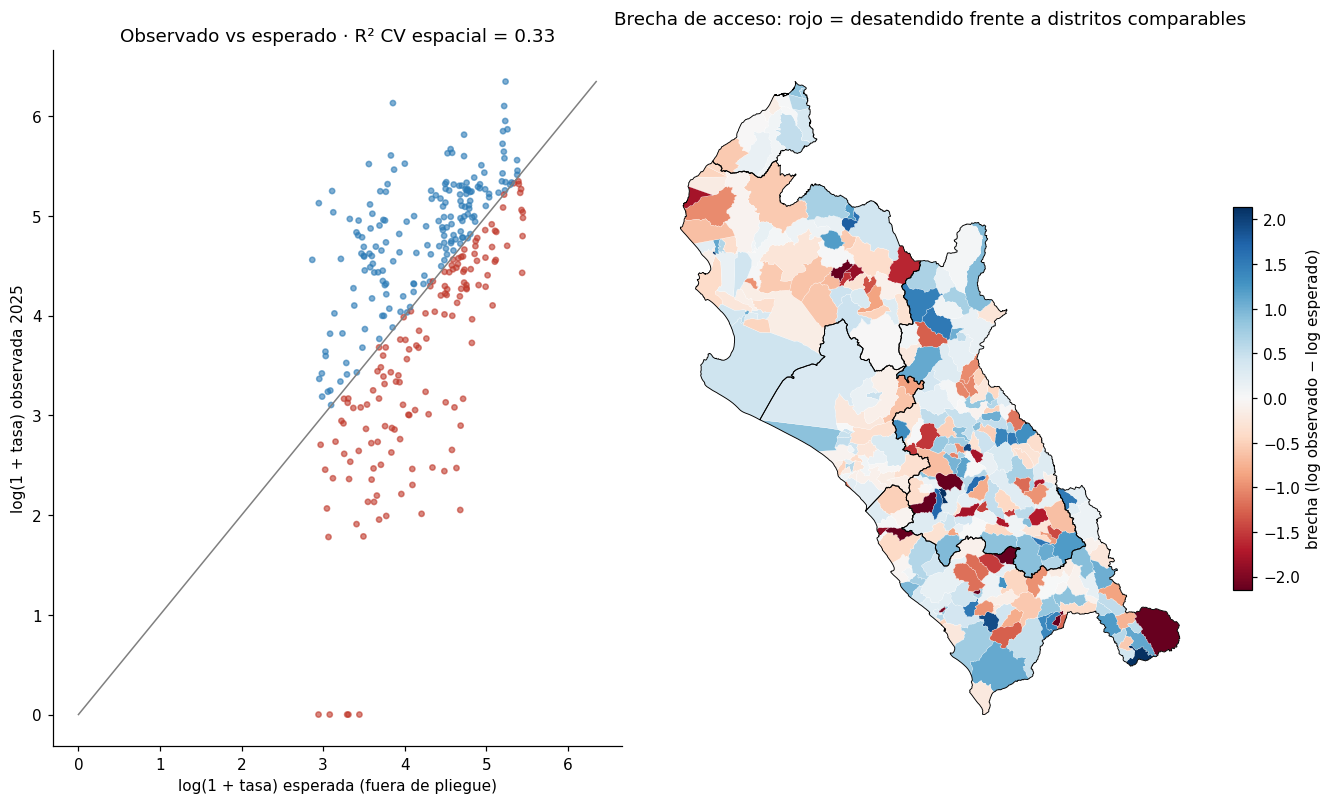

,distrito,provincia,departamento,tasa_obs,tasa_esperada,brecha
199,MOLLEBAMBA,SANTIAGO DE CHUCO,LA LIBERTAD,0.00,30.32,-3.44
108,SAN GREGORIO,SAN MIGUEL,CAJAMARCA,0.00,26.37,-3.31
166,PARANDAY,OTUZCO,LA LIBERTAD,0.00,25.97,-3.29
101,CALQUIS,SAN MIGUEL,CAJAMARCA,0.00,20.77,-3.08
181,ONGON,PATAZ,LA LIBERTAD,0.00,17.98,-2.94
285,SANTO DOMINGO,MORROPON,PIURA,6.78,106.86,-2.63
207,SAYAPULLO,GRAN CHIMU,LA LIBERTAD,6.48,66.13,-2.19
174,SAN JOSE,PACASMAYO,LA LIBERTAD,10.85,101.94,-2.16
138,ALTO TRUJILLO,TRUJILLO,LA LIBERTAD,10.48,87.79,-2.05
172,JEQUETEPEQUE,PACASMAYO,LA LIBERTAD,13.20,96.41,-1.93


In [10]:
gg = g[["ubigeo", "geometry"]].merge(corte, on="ubigeo")
deps = g.dissolve("departamento").reset_index()
lim = np.nanpercentile(np.abs(gg["brecha"]), 97)
fig, axes = plt.subplots(1, 2, figsize=(12, 7.2), constrained_layout=True)
axes[0].scatter(corte["y_esperado"], corte["y"], s=12, alpha=0.6,
                c=np.where(corte["brecha"] < 0, "#c0392b", "#2c7bb6"))
lims = [corte[["y", "y_esperado"]].min().min(), corte[["y", "y_esperado"]].max().max()]
axes[0].plot(lims, lims, color="grey", linewidth=1)
axes[0].set_xlabel("log(1 + tasa) esperada (fuera de pliegue)"); axes[0].set_ylabel("log(1 + tasa) observada 2025")
axes[0].set_title(f"Observado vs esperado · R² CV espacial = {cv_tab.loc[mejor, 'R² (CV espacial)']:.2f}")
gg.plot(column="brecha", cmap="RdBu", vmin=-lim, vmax=lim, ax=axes[1], edgecolor="white", linewidth=0.15,
        legend=True, legend_kwds={"label": "brecha (log observado − log esperado)", "shrink": 0.55})
deps.boundary.plot(ax=axes[1], color="black", linewidth=0.6)
axes[1].set_title("Brecha de acceso: rojo = desatendido frente a distritos comparables")
axes[1].set_axis_off()
fig.savefig(FIG / "08_brecha_acceso.png", bbox_inches="tight")
plt.show()

corte[["ubigeo", "distrito", "provincia", "departamento", "tasa_obs", "tasa_esperada", "brecha"]].round(3) \
    .to_csv(DATA / "brecha_acceso_2025.csv", index=False)
corte.sort_values("brecha")[["distrito", "provincia", "departamento", "tasa_obs", "tasa_esperada", "brecha"]].head(12).round(2)

## Hallazgos

1. **La red se triplicó y luego se ajustó.** Los canales pasaron de 22,7 mil (2017) a 87,8 mil (2023) y bajaron a
   73,3 mil en 2025. El retroceso de 2024 afecta a los cinco departamentos a la vez: es un choque común (cierre o
   consolidación de corresponsales), no un fenómeno local.
2. **La estructura espacial es estable.** El I de Moran del acceso se mantiene entre 0,20 y 0,24 todos los años
   (p = 0,001): la expansión no redujo la segregación entre zonas con y sin acceso.
3. **El entorno condiciona la trayectoria (Markov espacial).** La prueba de homogeneidad rechaza que las
   transiciones sean independientes del vecindario (Q = 146,3 con 80 gl, p < 0,0001; LR = 124,3, p = 0,001). Un
   distrito en el segundo quintil sube de quintil con probabilidad 0,36 si sus vecinos están en el quintil más
   alto y 0,12 si están en el segundo: hay difusión por contigüidad. El quintil más bajo es el más persistente
   (P = 0,79 de seguir ahí al año siguiente).
4. **El cambio anual de cada distrito no es predecible.** En validación de origen móvil (cuatro años de prueba),
   ningún modelo mejora a la persistencia (RMSE promedio 0,56 en todos) y la correlación de rangos del cambio es
   ≈ 0,08 en el mejor caso. Es un resultado negativo útil: priorizar por "crecimiento esperado" no tiene respaldo.
5. **El acceso potencial sí es modelable y la información espacial ayuda.** Con validación cruzada espacial por
   provincia, el Random Forest pasa de R² = 0,27 con covariables propias a 0,33 al agregar los rezagos WX y la
   posición, y el I de Moran de los residuos baja de 0,10 a 0,05. Pobreza y urbanización concentran 43% de la
   importancia SHAP.
6. **Brecha de acceso.** `data/processed/brecha_acceso_2025.csv` identifica distritos con mucho menos acceso que
   distritos de estructura similar: los 5 sin ningún canal (Mollebamba, San Gregorio, Paranday, Calquis, Ongón) y
   otros como Santo Domingo, Sayapullo, San José, Alto Trujillo y Jequetepeque, con tasas entre 7 y 16 veces
   menores a las esperadas. Esta brecha es el componente de **oportunidad** del score del notebook 09.

# 09 Ubicacion Optima

Notebook original: `09_ubicacion_optima.ipynb`.

# 09 · Priorización territorial y ubicación óptima de nuevos canales

| | |
|---|---|
| **Pregunta** | ¿Dónde conviene abrir nuevos canales de atención (cajeros, agentes corresponsales) para cubrir la mayor cantidad de adultos desatendidos, y cómo cambia la decisión si se considera la exposición a lluvia extrema? |
| **Datos** | Brecha de acceso 2025 por distrito (notebook 08); índice de exposición a lluvia extrema (notebook 06); población adulta censo 2025; 14 481 centros poblados INEI con tipo urbano o rural. |
| **Métodos** | Déficit de acceso relativo al acceso esperado; matriz oportunidad × riesgo con análisis de sensibilidad del peso del riesgo (τ de Kendall); problema de máxima cobertura (MCLP; Church y ReVelle, 1974) resuelto de forma exacta por programación lineal entera (CBC) y comparado con la heurística voraz; sensibilidad al radio de cobertura. |
| **Salidas** | `outputs/figuras/09_*.png` · `outputs/tablas/09_*.csv` · `data/processed/priorizacion_distrital.csv`. |

**Definiciones.**

* **Adultos desatendidos** del distrito d: A_d · (1 − tasa observada / tasa esperada) si la brecha es negativa, y 0 en otro caso.
  Es la población adulta que quedaría cubierta si el distrito alcanzara el acceso de distritos de estructura similar.
* **Riesgo climático:** índice de exposición a lluvia extrema (z promedio de marzo de 1998, 2017 y 2023), expresado en percentil.
* **Cobertura:** un centro poblado está cubierto si un canal nuevo queda a 5 km o menos en línea recta, una distancia
  razonable para un agente corresponsal en zona rural.

In [1]:
from pathlib import Path
import time
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pulp
from scipy.spatial import cKDTree
from scipy.stats import kendalltau

warnings.filterwarnings("ignore")
t0 = time.time()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
TAB = ROOT / "outputs" / "tablas"
CRS = "EPSG:32717"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Oportunidad y riesgo por distrito

In [2]:
leer = lambda f: pd.read_csv(DATA / f, dtype={"ubigeo": str})
base = leer("base_aede.csv")
brecha = leer("brecha_acceso_2025.csv")
lluvia = leer("lluvia_extrema_distrito.csv")
distritos = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs(CRS)
departamentos = distritos.dissolve("departamento").reset_index()

d = (base[["ubigeo", "distrito", "provincia", "departamento", "pob_18mas", "pob_total_2025", "pob_urbana",
           "lat_capital", "lon_capital"]]
     .merge(brecha[["ubigeo", "tasa_obs", "tasa_esperada", "brecha"]], on="ubigeo")
     .merge(lluvia[["ubigeo", "indice_exposicion"]], on="ubigeo"))
d["desatendido"] = d.brecha < 0
d["adultos_desatendidos"] = np.where(d.desatendido, d.pob_18mas * (1 - d.tasa_obs / d.tasa_esperada), 0.0)
d["canales_faltantes"] = np.where(d.desatendido, (d.tasa_esperada - d.tasa_obs) * d.pob_18mas / 1e4, 0.0)
d["riesgo_pct"] = d.indice_exposicion.rank(pct=True)

des = d[d.desatendido].copy()
des["oportunidad_pct"] = des.adultos_desatendidos.rank(pct=True)
print(f"Distritos desatendidos: {len(des)} de {len(d)}")
print(f"Adultos desatendidos: {des.adultos_desatendidos.sum():,.0f} | canales faltantes: {des.canales_faltantes.sum():,.0f}")
des.nlargest(8, "adultos_desatendidos")[["distrito", "provincia", "tasa_obs", "tasa_esperada",
                                         "adultos_desatendidos", "canales_faltantes", "riesgo_pct"]].round(2)

Distritos desatendidos: 147 de 327
Adultos desatendidos: 768,023 | canales faltantes: 9,466


,distrito,provincia,tasa_obs,tasa_esperada,adultos_desatendidos,canales_faltantes,riesgo_pct
258,VEINTISEIS DE OCTUBRE,PIURA,59.49,159.35,96815.39,1542.79,0.12
250,CASTILLA,PIURA,92.81,163.81,62631.88,1025.97,0.18
138,ALTO TRUJILLO,TRUJILLO,10.48,87.79,58795.23,516.14,0.03
302,PARIÑAS,TALARA,82.88,229.37,47625.77,1092.38,0.40
277,CHULUCANAS,MORROPON,80.87,149.81,31866.21,477.40,0.76
287,PAITA,PAITA,96.70,145.89,25938.83,378.42,0.22
257,TAMBO GRANDE,PIURA,125.45,166.77,25457.93,424.56,0.87
7,LOS BAÑOS DEL INCA,CAJAMARCA,73.24,115.33,17392.37,200.58,0.51


### Matriz oportunidad × riesgo

Los cuadrantes se cortan en la mediana de cada eje entre los distritos desatendidos. La lectura operativa es distinta
en cada uno: alta oportunidad y bajo riesgo admite canales físicos convencionales; alta oportunidad y alto riesgo
pide canales que toleren interrupciones (agentes en comercios con respaldo digital, cajeros en zonas no inundables).

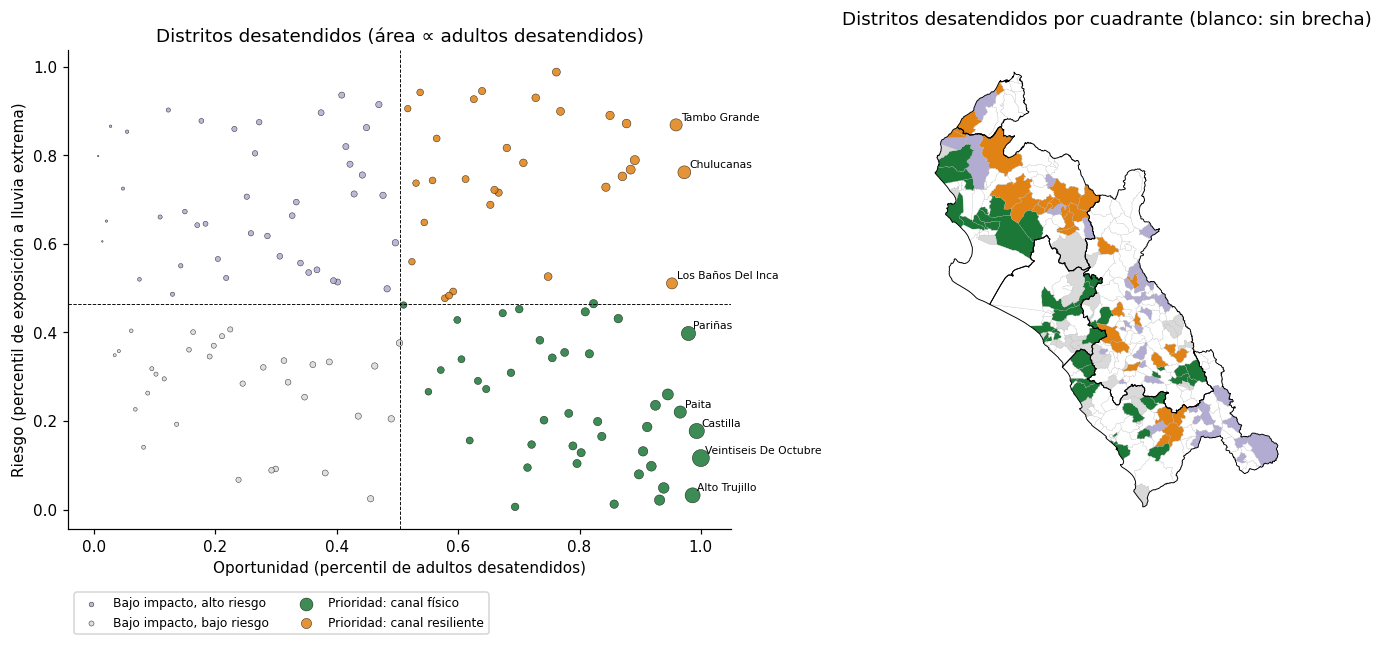

,distritos,adultos_desatendidos
cuadrante,,
"Bajo impacto, alto riesgo",42,43388.0
"Bajo impacto, bajo riesgo",32,30392.0
Prioridad: canal físico,42,509783.0
Prioridad: canal resiliente,31,184459.0


In [3]:
mo, mr = des.oportunidad_pct.median(), des.riesgo_pct.median()
cuad = np.select([(des.oportunidad_pct > mo) & (des.riesgo_pct <= mr), (des.oportunidad_pct > mo) & (des.riesgo_pct > mr),
                  (des.oportunidad_pct <= mo) & (des.riesgo_pct > mr)],
                 ["Prioridad: canal físico", "Prioridad: canal resiliente", "Bajo impacto, alto riesgo"],
                 "Bajo impacto, bajo riesgo")
des["cuadrante"] = cuad
COL = {"Prioridad: canal físico": "#1b7837", "Prioridad: canal resiliente": "#e08214",
       "Bajo impacto, alto riesgo": "#b2abd2", "Bajo impacto, bajo riesgo": "#d9d9d9"}
resumen_cuad = des.groupby("cuadrante").agg(distritos=("ubigeo", "size"),
                                            adultos_desatendidos=("adultos_desatendidos", "sum")).round(0)

fig, axs = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axs[0]
for k, g in des.groupby("cuadrante"):
    ax.scatter(g.oportunidad_pct, g.riesgo_pct, s=np.sqrt(g.adultos_desatendidos) / 2.5, c=COL[k], label=k,
               edgecolor="k", lw=0.3, alpha=0.85)
ax.axvline(mo, color="k", lw=0.6, ls="--"); ax.axhline(mr, color="k", lw=0.6, ls="--")
for _, r in des.nlargest(8, "adultos_desatendidos").iterrows():
    ax.annotate(r.distrito.title(), (r.oportunidad_pct, r.riesgo_pct), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="Oportunidad (percentil de adultos desatendidos)", ylabel="Riesgo (percentil de exposición a lluvia extrema)",
       title="Distritos desatendidos (área ∝ adultos desatendidos)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
m = distritos.merge(des[["ubigeo", "cuadrante"]], on="ubigeo", how="left")
m["color"] = m.cuadrante.map(COL).fillna("white")
m.plot(color=m.color, ax=axs[1], edgecolor="0.7", lw=0.15)
departamentos.boundary.plot(ax=axs[1], color="k", lw=0.6)
axs[1].set_axis_off(); axs[1].set_title("Distritos desatendidos por cuadrante (blanco: sin brecha)")
plt.tight_layout(); plt.savefig(FIG / "09_matriz_oportunidad_riesgo.png", bbox_inches="tight"); plt.show()
resumen_cuad

### Sensibilidad del ranking al peso del riesgo

Score = percentil de oportunidad − λ · percentil de riesgo. Con λ = 0 se ignora el clima; con λ = 1 pesa igual que
la oportunidad. Se mide cuánto cambia el orden (τ de Kendall frente a λ = 0) y cuántos distritos del top 20 se mantienen.

In [4]:
LAMBDAS = [0, 0.25, 0.5, 1.0]
for lam in LAMBDAS:
    des[f"score_l{lam}"] = des.oportunidad_pct - lam * des.riesgo_pct
top0 = set(des.nlargest(20, "score_l0").ubigeo)
sens = pd.DataFrame([{"lambda": lam,
                      "tau_kendall_vs_0": kendalltau(des.score_l0, des[f"score_l{lam}"])[0],
                      "top20_comunes": len(top0 & set(des.nlargest(20, f"score_l{lam}").ubigeo))} for lam in LAMBDAS])
sens.round(3)

,lambda,tau_kendall_vs_0,top20_comunes
0,0.00,1.000,20
1,0.25,0.868,15
2,0.50,0.755,14
3,1.00,0.575,12


## 2. Dos problemas distintos: densificar la ciudad y cubrir el campo

El déficit tiene dos componentes con soluciones distintas. En la ciudad la población ya está a pocos minutos de un
canal; lo que falta es **capacidad** (más cajeros y agentes en el mismo lugar), y un problema de ubicación por
cobertura no aporta, porque cualquier punto cubre a casi todos. En el campo el problema es de **distancia**: la
pregunta es dónde poner pocos canales para que la mayor cantidad de población rural tenga uno cerca. Por eso el
déficit se separa según la fracción urbana del distrito (censo 2025):

* **Densificación urbana:** canales faltantes × fracción urbana, reportados por distrito.
* **Cobertura rural:** adultos desatendidos × fracción rural, repartidos en partes iguales entre los centros poblados
  rurales del distrito (la base no trae población por centro poblado). Esta es la demanda del modelo de ubicación.

In [5]:
des["frac_urbana"] = (des.pob_urbana / des.pob_total_2025).clip(0, 1)
des["canales_urbanos_faltantes"] = des.canales_faltantes * des.frac_urbana
des["adultos_rurales_desatendidos"] = des.adultos_desatendidos * (1 - des.frac_urbana)
print(f"Canales urbanos faltantes: {des.canales_urbanos_faltantes.sum():,.0f} | "
      f"adultos rurales desatendidos: {des.adultos_rurales_desatendidos.sum():,.0f}")
des.nlargest(10, "canales_urbanos_faltantes")[["distrito", "provincia", "departamento", "canales_urbanos_faltantes",
                                               "riesgo_pct", "cuadrante"]].round(2)

Canales urbanos faltantes: 7,777 | adultos rurales desatendidos: 234,273


,distrito,provincia,departamento,canales_urbanos_faltantes,riesgo_pct,cuadrante
258,VEINTISEIS DE OCTUBRE,PIURA,PIURA,1522.50,0.12,Prioridad: canal físico
302,PARIÑAS,TALARA,PIURA,1070.84,0.40,Prioridad: canal físico
250,CASTILLA,PIURA,PIURA,1005.49,0.18,Prioridad: canal físico
138,ALTO TRUJILLO,TRUJILLO,LA LIBERTAD,498.30,0.03,Prioridad: canal físico
277,CHULUCANAS,MORROPON,PIURA,425.94,0.76,Prioridad: canal resiliente
287,PAITA,PAITA,PIURA,373.10,0.22,Prioridad: canal físico
257,TAMBO GRANDE,PIURA,PIURA,263.85,0.87,Prioridad: canal resiliente
222,PIMENTEL,CHICLAYO,LAMBAYEQUE,177.41,0.26,Prioridad: canal físico
216,LA VICTORIA,CHICLAYO,LAMBAYEQUE,154.54,0.02,Prioridad: canal físico
251,CATACAOS,PIURA,PIURA,141.84,0.13,Prioridad: canal físico


## 3. Ubicación óptima en el campo: problema de máxima cobertura (MCLP)

**Formulación** (Church y ReVelle, 1974). Con w_i la demanda del centro poblado rural i, x_j = 1 si se abre un canal
en el candidato j, y_i = 1 si i queda cubierto y N_i los candidatos a 5 km o menos de i:

max Σ w_i y_i   sujeto a   y_i ≤ Σ_{j ∈ N_i} x_j,   Σ x_j = P,   x_j ∈ {0, 1},   0 ≤ y_i ≤ 1.

Todos los centros poblados (urbanos y rurales) de distritos desatendidos son candidatos, porque un canal en un
pueblo urbano puede atender a los caseríos de alrededor. Se resuelve exacto con CBC y se compara con la
heurística voraz, que garantiza al menos 1 − 1/e ≈ 63% del óptimo.

In [6]:
cp = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="centros_poblados").to_crs(CRS)
cp = cp.rename(columns={"inei_distrito": "ubigeo"})[["ubigeo", "ccpp", "tipo", "geometry"]]
cp = cp[cp.ubigeo.isin(des.ubigeo)]
sin_cp = des[~des.ubigeo.isin(cp.ubigeo)]
# Sin capital georreferenciada (distritos de creación reciente) se usa un punto interior del polígono
pts = distritos.set_index("ubigeo").loc[sin_cp.ubigeo].geometry.representative_point()
capitales = gpd.GeoDataFrame({"ubigeo": sin_cp.ubigeo.values, "ccpp": (sin_cp.distrito + " (capital)").values,
                              "tipo": "Urban"}, geometry=pts.values, crs=CRS)
cp = pd.concat([cp, capitales], ignore_index=True)
cp = cp.merge(des[["ubigeo", "distrito", "provincia", "departamento", "adultos_rurales_desatendidos",
                   "riesgo_pct", "cuadrante"]], on="ubigeo")
n_rur = cp[cp.tipo == "Rural"].groupby("ubigeo").size()
cp["demanda"] = np.where(cp.tipo == "Rural", cp.adultos_rurales_desatendidos / cp.ubigeo.map(n_rur), 0.0)
cp["demanda"] = cp.demanda.fillna(0)
print(f"Candidatos: {len(cp):,} centros poblados | con demanda rural: {(cp.demanda > 0).sum():,}")
print(f"Demanda rural asignada: {cp.demanda.sum():,.0f} adultos "
      f"(control: {des.loc[des.ubigeo.isin(n_rur.index), 'adultos_rurales_desatendidos'].sum():,.0f})")

XY = np.c_[cp.geometry.x, cp.geometry.y]
ARBOL = cKDTree(XY)

def vecinos(radio_m):
    return [np.array(v) for v in ARBOL.query_ball_point(XY, radio_m)]

def mclp_exacto(w, N, P):
    n = len(w)
    prob = pulp.LpProblem("MCLP", pulp.LpMaximize)
    x = pulp.LpVariable.dicts("x", range(n), cat="Binary")
    y = pulp.LpVariable.dicts("y", range(n), lowBound=0, upBound=1)
    prob += pulp.lpSum(w[i] * y[i] for i in range(n))
    prob += pulp.lpSum(x.values()) == P
    for i in range(n):
        prob += y[i] <= pulp.lpSum(x[j] for j in N[i])
    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=60))
    sel = [j for j in range(n) if x[j].value() > 0.5]
    return sel, pulp.LpStatus[prob.status]

def cubiertos(sel, N):
    cov = np.zeros(len(N), bool)
    for j in sel:
        cov[N[j]] = True          # la cobertura es simétrica (distancia euclidiana)
    return cov

def mclp_voraz(w, N, P):
    cov = np.zeros(len(w), bool); sel = []
    for _ in range(P):
        gan = np.array([w[v][~cov[v]].sum() for v in N])
        j = int(gan.argmax()); sel.append(j); cov[N[j]] = True
    return sel

Candidatos: 6,241 centros poblados | con demanda rural: 5,860
Demanda rural asignada: 232,136 adultos (control: 232,136)


In [7]:
N5 = vecinos(5000)
w = cp.demanda.values; W = w.sum()
filas, soluciones = [], {}
for P in [10, 25, 50]:
    sel, estado = mclp_exacto(w, N5, P); soluciones[P] = sel
    sg = mclp_voraz(w, N5, P)
    filas.append({"P": P, "estado": estado, "cobertura_exacta_%": 100 * w[cubiertos(sel, N5)].sum() / W,
                  "cobertura_voraz_%": 100 * w[cubiertos(sg, N5)].sum() / W,
                  "adultos_cubiertos": w[cubiertos(sel, N5)].sum()})
comparacion = pd.DataFrame(filas)

# Curva de cobertura con la heurística voraz (casi óptima, ver tabla)
voraz_100 = mclp_voraz(w, N5, 100)
curva = [100 * w[cubiertos(voraz_100[:k], N5)].sum() / W for k in range(1, 101)]
print(f"Tiempo acumulado: {time.time() - t0:.0f} s")
comparacion.round(2)

Tiempo acumulado: 12 s


,P,estado,cobertura_exacta_%,cobertura_voraz_%,adultos_cubiertos
0,10,Optimal,14.13,14.10,32799.69
1,25,Optimal,27.42,27.39,63643.44
2,50,Optimal,42.69,41.93,99102.80


### Sensibilidad al radio y escenario ajustado por riesgo

In [8]:
P = 25
def coincidencia(sel_a, sel_b, tol_m=5000):
    """Sitios de B a <= tol de algún sitio de A (soluciones alternativas suelen diferir en pueblos vecinos)."""
    d, _ = cKDTree(XY[sel_a]).query(XY[sel_b])
    return int((d <= tol_m).sum())

radios = []
for r_km in [3, 5, 10]:
    Nr = vecinos(r_km * 1000)
    sel, _ = mclp_exacto(w, Nr, P)
    radios.append({"radio_km": r_km, "cobertura_%": 100 * w[cubiertos(sel, Nr)].sum() / W,
                   "sitios_identicos_a_5km": len(set(sel) & set(soluciones[P])),
                   "sitios_a_5km_de_la_base": coincidencia(soluciones[P], sel)})
radios = pd.DataFrame(radios)

# Escenario con riesgo: la demanda en zonas expuestas se descuenta hasta 50%
w_r = w * (1 - 0.5 * cp.riesgo_pct.values)
sel_r, _ = mclp_exacto(w_r, N5, P)
alto = cp.riesgo_pct.values > 0.75
def perfil(sel, nombre):
    cov = cubiertos(sel, N5)
    return {"escenario": nombre, "cobertura_%": 100 * w[cov].sum() / W,
            "sitios_en_riesgo_alto": int(alto[sel].sum()),
            "riesgo_medio_sitios_pct": cp.riesgo_pct.values[sel].mean() * 100}
escenarios = pd.DataFrame([perfil(soluciones[P], "Sin riesgo"), perfil(sel_r, "Ajustado por riesgo")])
escenarios["sitios_identicos"] = [np.nan, len(set(sel_r) & set(soluciones[P]))]
escenarios["sitios_a_5km_de_la_base"] = [np.nan, coincidencia(soluciones[P], sel_r)]
display(radios.round(2)); escenarios.round(2)

,radio_km,cobertura_%,sitios_identicos_a_5km,sitios_a_5km_de_la_base
0,3,16.33,1,23
1,5,27.42,25,25
2,10,49.74,0,15


,escenario,cobertura_%,sitios_en_riesgo_alto,riesgo_medio_sitios_pct,sitios_identicos,sitios_a_5km_de_la_base
0,Sin riesgo,27.42,8,57.16,NaN,NaN
1,Ajustado por riesgo,27.01,5,48.81,18.0,20.0


In [9]:
sel = soluciones[P]
cov = cubiertos(sel, N5)
sitios = cp.iloc[sel].copy()
sitios["demanda_cubierta"] = [w[N5[j]][:].sum() for j in sel]   # demanda en su radio (puede solaparse)
sitios["en_solucion_con_riesgo"] = [j in set(sel_r) for j in sel]
sitios = sitios.sort_values("demanda_cubierta", ascending=False)
sitios_wgs = sitios.to_crs(4326)
salida = pd.DataFrame({"ccpp": sitios.ccpp, "tipo": sitios.tipo, "distrito": sitios.distrito,
                       "provincia": sitios.provincia, "departamento": sitios.departamento,
                       "lat": sitios_wgs.geometry.y.round(5), "lon": sitios_wgs.geometry.x.round(5),
                       "demanda_en_radio": sitios.demanda_cubierta.round(0), "riesgo_pct": sitios.riesgo_pct.round(2),
                       "cuadrante": sitios.cuadrante, "se_mantiene_con_riesgo": sitios.en_solucion_con_riesgo})
salida.to_csv(TAB / "09_sitios_mclp_P25.csv", index=False)
pd.concat([comparacion, ], axis=0).to_csv(TAB / "09_mclp_exacto_vs_voraz.csv", index=False)
salida.head(12)

,ccpp,tipo,distrito,provincia,departamento,lat,lon,demanda_en_radio,riesgo_pct,cuadrante,se_mantiene_con_riesgo
128,SHAULLO GRANDE,Rural,LLACANORA,CAJAMARCA,CAJAMARCA,-7.17542,-78.41833,5061.0,0.38,Prioridad: canal físico,True
5792,CHUNGAYO,Rural,SANTO DOMINGO,MORROPON,PIURA,-5.05659,-79.88882,4170.0,0.93,Prioridad: canal resiliente,True
423,FARO BAJO,Rural,SOROCHUCO,CELENDIN,CAJAMARCA,-6.92647,-78.27613,3447.0,0.53,Prioridad: canal resiliente,True
171,QUINUAPATA,Rural,LOS BAÑOS DEL INCA,CAJAMARCA,CAJAMARCA,-7.10738,-78.48607,3077.0,0.51,Prioridad: canal resiliente,True
3813,LAS PALMERAS DE LA JOYITA,Urban,PIMENTEL,CHICLAYO,LAMBAYEQUE,-6.80597,-79.88288,3041.0,0.26,Prioridad: canal físico,True
5666,SAN LORENZO,Rural,CHALACO,MORROPON,PIURA,-5.07043,-79.79845,2888.0,0.90,Prioridad: canal resiliente,True
3261,LA RINCONADA,Rural,MOLLEBAMBA,SANTIAGO DE CHUCO,LA LIBERTAD,-8.15783,-77.97338,2871.0,0.54,"Bajo impacto, alto riesgo",True
265,PUEBLO LIBRE,Rural,SAN JUAN,CAJAMARCA,CAJAMARCA,-7.28619,-78.49857,2858.0,0.43,Prioridad: canal físico,True
5095,SALALA,Rural,EL CARMEN DE LA FRONTERA,HUANCABAMBA,PIURA,-5.11041,-79.46321,2798.0,0.77,Prioridad: canal resiliente,True
3655,CHANCHAMAYO,Rural,SAYAPULLO,GRAN CHIMU,LA LIBERTAD,-7.57238,-78.51278,2589.0,0.46,Prioridad: canal físico,True


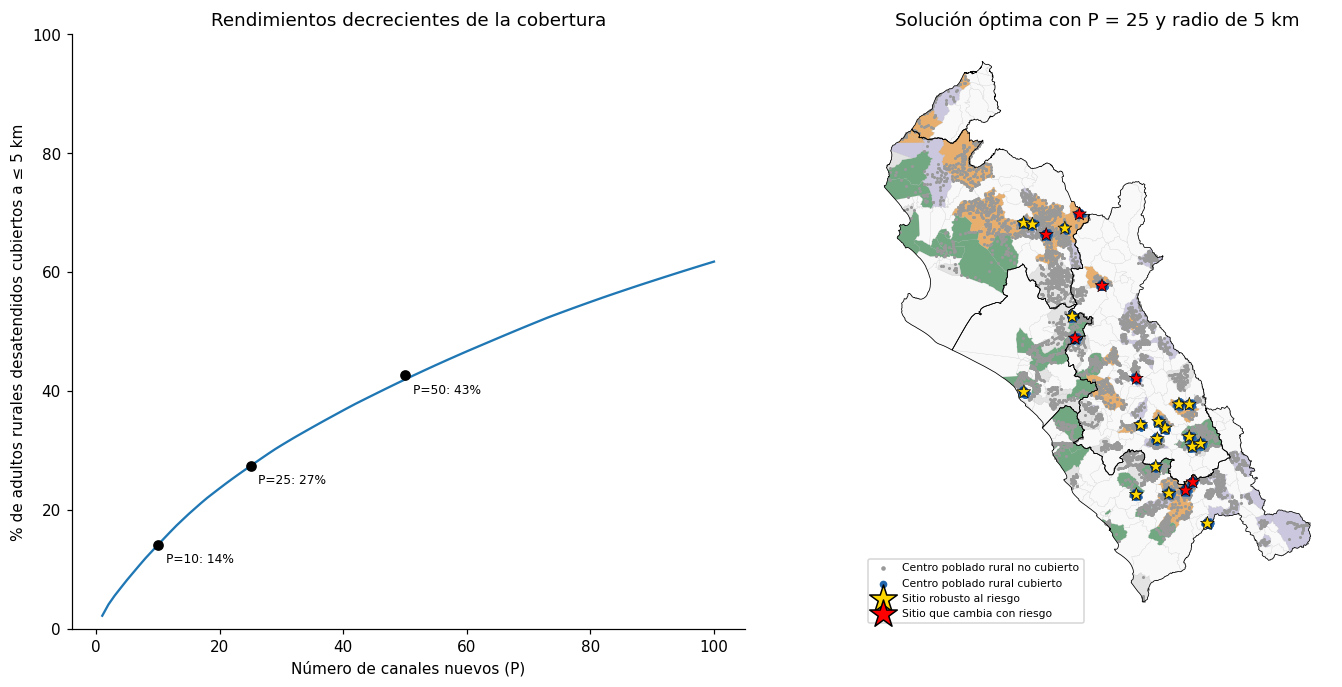

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axs[0]
ax.plot(range(1, 101), curva, color="C0")
for _, r in comparacion.iterrows():
    ax.scatter(r.P, r["cobertura_exacta_%"], color="k", zorder=3)
    ax.annotate(f"P={r.P}: {r['cobertura_exacta_%']:.0f}%", (r.P, r["cobertura_exacta_%"]), xytext=(5, -12),
                textcoords="offset points", fontsize=8)
ax.set(xlabel="Número de canales nuevos (P)", ylabel="% de adultos rurales desatendidos cubiertos a ≤ 5 km",
       title="Rendimientos decrecientes de la cobertura", ylim=(0, 100))

ax = axs[1]
distritos.plot(ax=ax, color="0.95", edgecolor="0.8", lw=0.15)
m.plot(color=m.color, ax=ax, edgecolor="0.8", lw=0.15, alpha=0.6)
departamentos.boundary.plot(ax=ax, color="k", lw=0.5)
dem = cp.demanda.values > 0
ax.scatter(XY[dem & ~cov, 0], XY[dem & ~cov, 1], s=1, c="0.6", label="Centro poblado rural no cubierto")
ax.scatter(XY[dem & cov, 0], XY[dem & cov, 1], s=4, c="#2166ac", label="Centro poblado rural cubierto")
gpd.GeoSeries(sitios.geometry.buffer(5000), crs=CRS).boundary.plot(ax=ax, color="#08306b", lw=0.9)
ax.scatter(sitios.geometry.x, sitios.geometry.y, marker="*", s=90, c=np.where(sitios.en_solucion_con_riesgo, "gold", "red"),
           edgecolor="k", lw=0.4, zorder=5)
ax.scatter([], [], marker="*", s=90, c="gold", edgecolor="k", label="Sitio robusto al riesgo")
ax.scatter([], [], marker="*", s=90, c="red", edgecolor="k", label="Sitio que cambia con riesgo")
ax.legend(fontsize=7, loc="lower left", markerscale=2)
ax.set_axis_off(); ax.set_title(f"Solución óptima con P = {P} y radio de 5 km")
plt.tight_layout(); plt.savefig(FIG / "09_mclp_cobertura.png", bbox_inches="tight"); plt.show()

In [11]:
prior = d.merge(des[["ubigeo", "oportunidad_pct", "cuadrante", "score_l0", "score_l0.5", "canales_urbanos_faltantes",
                     "adultos_rurales_desatendidos"]], on="ubigeo", how="left")
prior["sitios_mclp_P25"] = prior.ubigeo.map(sitios.ubigeo.value_counts()).fillna(0).astype(int)
prior = prior.drop(columns=["lat_capital", "lon_capital"])
prior.to_csv(DATA / "priorizacion_distrital.csv", index=False)
print(f"Distritos con al menos un sitio: {(prior.sitios_mclp_P25 > 0).sum()} | tiempo total {time.time() - t0:.0f} s")

Distritos con al menos un sitio: 23 | tiempo total 29 s


## Hallazgos

1. **Magnitud del déficit.** 147 de los 327 distritos tienen menos acceso que el esperado por su estructura. Para
   igualarlos faltan unos 9 500 canales, equivalentes a 768 mil adultos desatendidos.
2. **La mayor parte del déficit es urbano y de bajo riesgo climático.** Siete distritos urbanos (Veintiséis de
   Octubre, Pariñas, Castilla, Alto Trujillo, Chulucanas, Paita y Tambo Grande) explican la mitad del déficit de
   canales. Es un problema de **densificación** en ciudades intermedias de Piura y en Alto Trujillo, no de distancia.
3. **El riesgo cambia la prioridad, pero no la invierte.** Con el riesgo pesando la mitad que la oportunidad
   (λ = 0,5), el τ de Kendall frente al ranking sin riesgo es 0,76 y 14 de los 20 primeros distritos se mantienen.
   Hay 31 distritos de alta oportunidad y alta exposición, con 184 mil adultos desatendidos, sobre todo en la sierra
   de Piura y en el norte de Cajamarca: ahí conviene un canal que tolere interrupciones.
4. **Cobertura rural.** El problema de máxima cobertura se resuelve de forma exacta en segundos para 6 241
   candidatos. Con 25 canales nuevos se cubre el 27% de los 232 mil adultos rurales desatendidos a 5 km o menos,
   con 50 el 43% y con 100 cerca del 62%. Los rendimientos son decrecientes, y la heurística voraz queda a menos de
   un punto porcentual del óptimo en todos los casos.
5. **Dónde.** Los sitios óptimos se concentran en la sierra de Cajamarca (Llacanora, Sorochuco, Los Baños del Inca,
   San Juan), la sierra de La Libertad (Usquil, Sayapullo, Sanagorán) y la sierra de Piura (Santo Domingo, Chalaco,
   El Carmen de la Frontera). Son zonas con caseríos densos y lejos de cualquier canal.
6. **Robustez.** Al descontar la demanda por riesgo, la cobertura apenas cae (27,4% a 27,0%), 20 de 25 sitios quedan
   a 5 km o menos de un sitio de la solución base y los sitios en zonas de riesgo alto bajan de 8 a 5. El radio sí
   importa: con 10 km la cobertura sube a 50% y la red se reorganiza (15 de 25 sitios cerca de los de 5 km), por lo
   que el radio debe fijarse según el tipo de canal (agente a pie frente a agencia con transporte).

**Limitaciones.** La demanda dentro del distrito se reparte en partes iguales entre caseríos porque la base no trae
población por centro poblado; la distancia es en línea recta y no por red vial; el acceso esperado proviene de un
modelo con R² = 0,33 en validación espacial, por lo que la brecha de cada distrito tiene incertidumbre.

## Referencias

* Church, R., & ReVelle, C. (1974). The maximal covering location problem. *Papers of the Regional Science Association, 32*(1), 101-118.
* Nemhauser, G. L., Wolsey, L. A., & Fisher, M. L. (1978). An analysis of approximations for maximizing submodular set functions. *Mathematical Programming, 14*(1), 265-294.
* Murray, A. T. (2016). Maximal coverage location problem: Impacts, significance, and evolution. *International Regional Science Review, 39*(1), 5-27.